<a href="https://colab.research.google.com/github/mw627/audio-driven-image-generation/blob/main/AI6103_Assignment_Fall_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    print("No GPU detected. Please enable GPU in Colab settings.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU name: Tesla T4
GPU memory (GB): 14.56


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

DATA_DIR = PROJECT_DIR / "dataset"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"

for path in [
    DATA_DIR,
    CHECKPOINT_DIR,
    LOG_DIR,
    FIGURE_DIR,
    RESULT_DIR
]:
    path.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Directory setup completed.")

Project directory: /content/drive/MyDrive/AI6103_Assignment
Directory setup completed.


数据集操作

In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/AI6103_Assignment/dataset")

for path in sorted(DATA_DIR.iterdir()):
    print(path.name, "|", "Directory" if path.is_dir() else "File")

from pathlib import Path
import zipfile

ZIP_PATH = Path(
    "/content/drive/MyDrive/AI6103_Assignment/dataset/dog_breed_dataset.zip"
)

if not ZIP_PATH.exists():
    print("ZIP file not found. Please check the file path.")
else:
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        names = z.namelist()

        print("Total entries:", len(names))
        print("\nFirst 40 entries:")

        for name in names[:40]:
            print(name)

dog_breed_dataset.zip | File
Total entries: 10232

First 40 entries:
data/
data/test_labels.csv
data/train_labels.csv
data/val_labels.csv
data/test/
data/test/images/
data/test/images/d959917d3824b2d501d32b17055d88f8.jpg
data/test/images/1dc44c282163994a08cc05a9c082f960.jpg
data/test/images/0a1b0b7df2918d543347050ad8b16051.jpg
data/test/images/8a6334cbeca54f9d56b83a34ac491aa8.jpg
data/test/images/3bdc7d098a96d40314cf7ed50b83501a.jpg
data/test/images/23ddca9977a7c6547e2502b26cec80fc.jpg
data/test/images/96f04a330af8b03da147644ccb75b4a0.jpg
data/test/images/c443f3ba58dd6a986c974b56b1f1cbb6.jpg
data/test/images/290a83cd8331cfe96a1846f5e1977b55.jpg
data/test/images/bf4efb3a9c94b5a92ef3751faa091121.jpg
data/test/images/7d0ed77e36fd9b1b4c84f5b07b5290d8.jpg
data/test/images/48bdb3561947f1c4b817bdada3db0c0d.jpg
data/test/images/88c0df28f7f27a13e48632be87111a53.jpg
data/test/images/95debc3253f72a005a8473afdd06e730.jpg
data/test/images/7132f29cda3823956bd8f246a16faba8.jpg
data/test/images/185dd9

In [ ]:
from pathlib import Path
import zipfile

PROJECT_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")
DATA_DIR = PROJECT_DIR / "dataset"

ZIP_PATH = DATA_DIR / "dog_breed_dataset.zip"
EXTRACT_DIR = DATA_DIR / "extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# 如果数据集尚未解压，则执行解压
if not (EXTRACT_DIR / "data").exists():
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Extraction completed.")
else:
    print("Dataset has already been extracted.")

DATASET_ROOT = EXTRACT_DIR / "data"

print("\nDataset root:", DATASET_ROOT)
print("Dataset root exists:", DATASET_ROOT.exists())

print("\nTop-level contents:")
for path in sorted(DATASET_ROOT.iterdir()):
    print(f"{'[DIR]' if path.is_dir() else '[FILE]'} {path.name}")

Extracting dataset...
Extraction completed.

Dataset root: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data
Dataset root exists: True

Top-level contents:
[DIR] test
[FILE] test_labels.csv
[DIR] train
[FILE] train_labels.csv
[DIR] val
[FILE] val_labels.csv


In [ ]:
import pandas as pd

CSV_FILES = {
    "train": DATASET_ROOT / "train_labels.csv",
    "val": DATASET_ROOT / "val_labels.csv",
    "test": DATASET_ROOT / "test_labels.csv",
}

for split, csv_path in CSV_FILES.items():
    df = pd.read_csv(csv_path)

    print(f"\n{'=' * 50}")
    print(f"{split.upper()} LABELS")
    print("File:", csv_path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    print(df.head())

    print("\nData types:")
    print(df.dtypes)


TRAIN LABELS
File: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data/train_labels.csv
Shape: (7155, 2)
Columns: ['id', 'breed']

First 5 rows:
                                 id             breed
0  be9686a8b005707ab13d8f5dff1d7431      newfoundland
1  6366e33e378df764b143dbae6809b756            beagle
2  1609abf6c6ac2e8df0af837cbe9cee74  mexican_hairless
3  478c1ceb68afd4e6be917ea8367a71bd      ibizan_hound
4  265d3babc4f879da3b9898ed77d5b585            vizsla

Data types:
id       object
breed    object
dtype: object

VAL LABELS
File: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data/val_labels.csv
Shape: (1533, 2)
Columns: ['id', 'breed']

First 5 rows:
                                 id             breed
0  ad282d2da0cc82233dbc487e8ca80aed           samoyed
1  70f2fd56f61deb7daaeb72b8664cec9a  miniature_poodle
2  9463bed0f3812eee19c6bf929e679638  blenheim_spaniel
3  8898c34ad05d2c95319ff2a2f326e69c     saint_bernard
4  01e2245b46eb747260ff80f1c892daef

In [ ]:
from pathlib import Path

for split in ["train", "val", "test"]:
    image_dir = DATASET_ROOT / split / "images"

    if not image_dir.exists():
        print(f"{split}: Image directory not found: {image_dir}")
        continue

    image_files = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }
    ]

    print(f"{split.upper()} image count: {len(image_files)}")
    print(f"Image directory: {image_dir}")

TRAIN image count: 7155
Image directory: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data/train/images
VAL image count: 1533
Image directory: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data/val/images
TEST image count: 1534
Image directory: /content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data/test/images


In [ ]:
import pandas as pd
from pathlib import Path

DATASET_ROOT = Path(
    "/content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data"
)

train_df = pd.read_csv(DATASET_ROOT / "train_labels.csv")
val_df = pd.read_csv(DATASET_ROOT / "val_labels.csv")
test_df = pd.read_csv(DATASET_ROOT / "test_labels.csv")

# 统计类别数量
train_breeds = set(train_df["breed"].unique())
val_breeds = set(val_df["breed"].unique())
test_breeds = set(test_df["breed"].unique())

print("Number of training classes:", len(train_breeds))
print("Number of validation classes:", len(val_breeds))
print("Number of test classes:", len(test_breeds))

print("\nClass consistency checks:")
print("Validation classes match training:", val_breeds == train_breeds)
print("Test classes match training:", test_breeds == train_breeds)

print("\nMissing classes in validation:")
print(sorted(train_breeds - val_breeds))

print("\nMissing classes in test:")
print(sorted(train_breeds - test_breeds))

# 检查是否存在重复图片 ID
for split_name, df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:
    print(
        f"{split_name} duplicate IDs:",
        int(df["id"].duplicated().sum())
    )

# 检查不同数据集之间是否存在重复 ID
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])
test_ids = set(test_df["id"])

print("\nCross-split ID overlap:")
print("Train-Val:", len(train_ids & val_ids))
print("Train-Test:", len(train_ids & test_ids))
print("Val-Test:", len(val_ids & test_ids))

Number of training classes: 120
Number of validation classes: 120
Number of test classes: 120

Class consistency checks:
Validation classes match training: True
Test classes match training: True

Missing classes in validation:
[]

Missing classes in test:
[]
train duplicate IDs: 0
val duplicate IDs: 0
test duplicate IDs: 0

Cross-split ID overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0


In [ ]:
from PIL import Image
from pathlib import Path

SPLITS = ["train", "val", "test"]

image_extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

for split in SPLITS:
    split_df = pd.read_csv(DATASET_ROOT / f"{split}_labels.csv")
    image_dir = DATASET_ROOT / split / "images"

    missing_images = []
    unreadable_images = []

    for image_id in split_df["id"]:
        # 当前数据集的图片文件名不包含扩展名
        candidates = [
            image_dir / f"{image_id}{ext}"
            for ext in image_extensions
        ]

        image_path = next(
            (p for p in candidates if p.exists()),
            None
        )

        if image_path is None:
            missing_images.append(image_id)
            continue

        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception:
            unreadable_images.append(str(image_path))

    print(f"\n{split.upper()}")
    print("CSV rows:", len(split_df))
    print("Missing images:", len(missing_images))
    print("Unreadable images:", len(unreadable_images))

    if missing_images:
        print("Missing image examples:", missing_images[:5])

    if unreadable_images:
        print("Unreadable image examples:", unreadable_images[:5])


TRAIN
CSV rows: 7155
Missing images: 0
Unreadable images: 0

VAL
CSV rows: 1533
Missing images: 0
Unreadable images: 0

TEST
CSV rows: 1534
Missing images: 0
Unreadable images: 0


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path
import pandas as pd

DATASET_ROOT = Path(
    "/content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data"
)

# 读取训练集标签
train_df = pd.read_csv(DATASET_ROOT / "train_labels.csv")

# 训练集基础预处理：转换为 RGB、调整尺寸、转换为 Tensor
stats_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
])

class DogBreedDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transform
        self.extensions = [".jpg", ".jpeg", ".png", ".bmp", ".webp"]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = row["id"]
        breed = row["breed"]

        image_path = None

        for ext in self.extensions:
            candidate = self.image_dir / f"{image_id}{ext}"
            if candidate.exists():
                image_path = candidate
                break

        if image_path is None:
            raise FileNotFoundError(
                f"Image not found for ID: {image_id}"
            )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        return image, breed

# 此处只使用训练集计算均值和标准差
stats_dataset = DogBreedDataset(
    dataframe=train_df,
    image_dir=DATASET_ROOT / "train" / "images",
    transform=stats_transform,
)

stats_loader = DataLoader(
    stats_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

channel_sum = torch.zeros(3, dtype=torch.float64)
channel_squared_sum = torch.zeros(3, dtype=torch.float64)
total_pixels = 0

for batch_idx, (images, _) in enumerate(stats_loader):
    # images 的形状为 [batch_size, 3, 100, 100]
    images = images.to(torch.float64)

    batch_pixels = images.shape[0] * images.shape[2] * images.shape[3]

    channel_sum += images.sum(dim=(0, 2, 3))
    channel_squared_sum += (images ** 2).sum(dim=(0, 2, 3))
    total_pixels += batch_pixels

    if (batch_idx + 1) % 10 == 0:
        print(
            f"Processed {min((batch_idx + 1) * 128, len(stats_dataset))}"
            f" / {len(stats_dataset)} training images"
        )

# 计算总体均值和总体标准差
channel_mean = channel_sum / total_pixels

channel_variance = (
    channel_squared_sum / total_pixels
    - channel_mean ** 2
).clamp(min=0)

channel_std = torch.sqrt(channel_variance)

MEAN = channel_mean.tolist()
STD = channel_std.tolist()

print("\nTraining-set channel statistics")
print("Mean (R, G, B):", MEAN)
print("Std  (R, G, B):", STD)

Processed 1280 / 7155 training images
Processed 2560 / 7155 training images
Processed 3840 / 7155 training images
Processed 5120 / 7155 training images
Processed 6400 / 7155 training images

Training-set channel statistics
Mean (R, G, B): [0.4771834057763069, 0.4527636099287068, 0.3927860050343754]
Std  (R, G, B): [0.25341599247313307, 0.24796733174129357, 0.25226678270663994]


In [ ]:
import pandas as pd
import torch

from pathlib import Path
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# =========================
# 1. Dataset configuration
# =========================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/AI6103_Assignment/dataset/extracted/data"
)

BATCH_SIZE = 128

MEAN = [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754
]

STD = [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994
]

# =========================
# 2. Data transformations
# =========================

normalize = transforms.Normalize(
    mean=MEAN,
    std=STD
)

# Training augmentation:
# Random horizontal flip + zero padding + random crop
train_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Pad(12, fill=0),
    transforms.RandomCrop((100, 100)),
    transforms.ToTensor(),
    normalize
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    normalize
])

# =========================
# 3. Load label files
# =========================

train_df = pd.read_csv(DATASET_ROOT / "train_labels.csv")
val_df = pd.read_csv(DATASET_ROOT / "val_labels.csv")
test_df = pd.read_csv(DATASET_ROOT / "test_labels.csv")

# =========================
# 4. Build datasets
# =========================

train_base_dataset = DogBreedDataset(
    dataframe=train_df,
    image_dir=DATASET_ROOT / "train" / "images",
    transform=train_transform
)

val_base_dataset = DogBreedDataset(
    dataframe=val_df,
    image_dir=DATASET_ROOT / "val" / "images",
    transform=eval_transform
)

test_base_dataset = DogBreedDataset(
    dataframe=test_df,
    image_dir=DATASET_ROOT / "test" / "images",
    transform=eval_transform
)

# Use the same class-to-index mapping for all splits
CLASSES = sorted(train_df["breed"].unique())
NUM_CLASSES = len(CLASSES)

CLASS_TO_IDX = {
    breed: idx
    for idx, breed in enumerate(CLASSES)
}

IDX_TO_CLASS = {
    idx: breed
    for breed, idx in CLASS_TO_IDX.items()
}


class IndexedDogBreedDataset(Dataset):
    def __init__(self, base_dataset, class_to_idx):
        self.base_dataset = base_dataset
        self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, breed = self.base_dataset[idx]
        label = self.class_to_idx[breed]

        return image, label


train_dataset = IndexedDogBreedDataset(
    train_base_dataset, CLASS_TO_IDX
)

val_dataset = IndexedDogBreedDataset(
    val_base_dataset, CLASS_TO_IDX
)

test_dataset = IndexedDogBreedDataset(
    test_base_dataset, CLASS_TO_IDX
)

# =========================
# 5. Build data loaders
# =========================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# =========================
# 6. Verify data loaders
# =========================

print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label range:", labels.min().item(), "to", labels.max().item())
print("Image tensor finite:", torch.isfinite(images).all().item())

# Verify that all labels are valid
assert NUM_CLASSES == 120
assert len(train_dataset) == 7155
assert len(val_dataset) == 1533
assert len(test_dataset) == 1534

assert images.shape[1:] == (3, 100, 100)
assert labels.dtype == torch.int64
assert torch.isfinite(images).all()

print("\nAll dataset and batch checks passed.")

Number of classes: 120
Batch size: 128
Training samples: 7155
Validation samples: 1533
Test samples: 1534

Batch image shape: torch.Size([128, 3, 100, 100])
Batch label shape: torch.Size([128])
Image dtype: torch.float32
Label dtype: torch.int64
Label range: 0 to 119
Image tensor finite: True

All dataset and batch checks passed.


In [ ]:
import json
import pandas as pd
import torch
import torchvision

from pathlib import Path
from datetime import datetime, timezone

# =========================
# 1. Project directories
# =========================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/AI6103_Assignment"
)

DATASET_ROOT = (
    PROJECT_DIR / "dataset" / "extracted" / "data"
)

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"
CONFIG_DIR = PROJECT_DIR / "config"

for directory in [
    CHECKPOINT_DIR,
    LOG_DIR,
    FIGURE_DIR,
    RESULT_DIR,
    CONFIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# =========================
# 2. Save preprocessing config
# =========================

MEAN = [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754
]

STD = [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994
]

train_df = pd.read_csv(DATASET_ROOT / "train_labels.csv")
val_df = pd.read_csv(DATASET_ROOT / "val_labels.csv")
test_df = pd.read_csv(DATASET_ROOT / "test_labels.csv")

CLASSES = sorted(train_df["breed"].unique())

config = {
    "project": "AI6103 Assignment",
    "last_completed_stage": "data_validation_and_preprocessing_statistics",
    "last_updated_utc": datetime.now(timezone.utc).isoformat(),

    "dataset_root": str(DATASET_ROOT),
    "train_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),

    "num_classes": len(CLASSES),
    "classes": CLASSES,

    "image_size": [100, 100],
    "batch_size": 128,

    "normalization": {
        "mean_rgb": MEAN,
        "std_rgb": STD
    },

    "training_augmentation": {
        "random_horizontal_flip_probability": 0.5,
        "zero_padding": 12,
        "random_crop_size": [100, 100]
    },

    "model": {
        "architecture": "EfficientNetV2-S",
        "pretrained": False,
        "num_classes": len(CLASSES)
    },

    "environment": {
        "python_torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "cuda_available": torch.cuda.is_available(),
        "gpu_name": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        )
    },

    "test_set_policy": (
        "Do not use test metrics for hyperparameter selection. "
        "Evaluate on the holdout test set only after all experiments."
    )
}

config_path = CONFIG_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

# Save class-to-index mapping
class_mapping_df = pd.DataFrame({
    "breed": CLASSES,
    "class_index": list(range(len(CLASSES)))
})

mapping_path = CONFIG_DIR / "class_mapping.csv"
class_mapping_df.to_csv(mapping_path, index=False)

# =========================
# 3. Save progress record
# =========================

progress_text = f"""# AI6103 Assignment Progress

Last completed stage:
- Dataset extracted to Google Drive
- Dataset integrity checked
- All three splits contain 120 classes
- No missing or unreadable images detected
- No duplicate IDs or cross-split ID overlap detected
- Training-set RGB mean and standard deviation calculated
- Dataset loading pipeline verified

Dataset:
- Training samples: {len(train_df)}
- Validation samples: {len(val_df)}
- Test samples: {len(test_df)}
- Number of classes: {len(CLASSES)}

Image preprocessing:
- Resize: 100 x 100
- Training augmentation: random horizontal flip (p=0.5)
- Training augmentation: zero padding of 12 pixels
- Training augmentation: random crop to 100 x 100
- Normalization mean: {MEAN}
- Normalization std: {STD}

Model:
- EfficientNetV2-S
- Random initialization, no pretrained weights
- Number of output classes: {len(CLASSES)}

Next stage:
- Implement model, training loop and validation loop
- Run learning-rate experiments with LR 0.5, 0.05 and 0.001
- Save per-epoch metrics, plots and model checkpoints

Important:
- Select hyperparameters using the validation set only.
- Evaluate the holdout test set only after completing the experiments.
- Do not write an answer for Section 7, The Takeaway Message.
"""

progress_path = LOG_DIR / "progress.md"
progress_path.write_text(progress_text, encoding="utf-8")

print("Checkpoint files saved successfully.")
print("Configuration:", config_path)
print("Class mapping:", mapping_path)
print("Progress record:", progress_path)

print("\nSaved file sizes:")
for path in [config_path, mapping_path, progress_path]:
    print(f"{path.name}: {path.stat().st_size:,} bytes")

Checkpoint files saved successfully.
Configuration: /content/drive/MyDrive/AI6103_Assignment/config/experiment_config.json
Class mapping: /content/drive/MyDrive/AI6103_Assignment/config/class_mapping.csv
Progress record: /content/drive/MyDrive/AI6103_Assignment/logs/progress.md

Saved file sizes:
experiment_config.json: 3,769 bytes
class_mapping.csv: 2,099 bytes
progress.md: 1,308 bytes


In [ ]:
from pathlib import Path
import shutil
import os

# 1. 检查 Colab 本地磁盘
print("=== Colab local storage ===")

disk = shutil.disk_usage("/content")

print(f"Total:     {disk.total / 1024**3:.2f} GB")
print(f"Used:      {disk.used / 1024**3:.2f} GB")
print(f"Free:      {disk.free / 1024**3:.2f} GB")

# 2. 检查本地项目目录
LOCAL_PROJECT_DIR = Path("/content/AI6103_Assignment")

print("\n=== Local project ===")
print("Exists:", LOCAL_PROJECT_DIR.exists())

# 3. 检查 Google Drive 目录
DRIVE_PROJECT_DIR = Path(
    "/content/drive/MyDrive/AI6103_Assignment"
)

print("\n=== Google Drive project ===")
print("Exists:", DRIVE_PROJECT_DIR.exists())

if DRIVE_PROJECT_DIR.exists():
    for relative_path in [
        "config/experiment_config.json",
        "config/class_mapping.csv",
        "logs/progress.md",
    ]:
        path = DRIVE_PROJECT_DIR / relative_path

        print(
            relative_path,
            "| exists:", path.exists(),
            "| size:", path.stat().st_size if path.exists() else "N/A"
        )

# 4. 检查数据集压缩包
ZIP_PATH = Path(
    "/content/drive/MyDrive/AI6103_Assignment/"
    "dataset/dog_breed_dataset.zip"
)

print("\n=== Dataset archive ===")
print("ZIP exists:", ZIP_PATH.exists())

if ZIP_PATH.exists():
    print(f"ZIP size: {ZIP_PATH.stat().st_size / 1024**2:.2f} MB")

=== Colab local storage ===
Total:     235.68 GB
Used:      43.17 GB
Free:      192.49 GB

=== Local project ===
Exists: False

=== Google Drive project ===
Exists: True
config/experiment_config.json | exists: True | size: 3769
config/class_mapping.csv | exists: True | size: 2099
logs/progress.md | exists: True | size: 1308

=== Dataset archive ===
ZIP exists: True
ZIP size: 344.83 MB


In [ ]:
from pathlib import Path

LOCAL_PROJECT_DIR = Path("/content/AI6103_Assignment")

LOCAL_DATA_DIR = LOCAL_PROJECT_DIR / "dataset"
LOCAL_EXTRACT_DIR = LOCAL_DATA_DIR / "extracted"

CHECKPOINT_DIR = LOCAL_PROJECT_DIR / "checkpoints"
LOG_DIR = LOCAL_PROJECT_DIR / "logs"
FIGURE_DIR = LOCAL_PROJECT_DIR / "figures"
RESULT_DIR = LOCAL_PROJECT_DIR / "results"
CONFIG_DIR = LOCAL_PROJECT_DIR / "config"

for directory in [
    LOCAL_DATA_DIR,
    LOCAL_EXTRACT_DIR,
    CHECKPOINT_DIR,
    LOG_DIR,
    FIGURE_DIR,
    RESULT_DIR,
    CONFIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Local project structure created.")

for path in sorted(LOCAL_PROJECT_DIR.iterdir()):
    print(path.name)

Local project structure created.
checkpoints
config
dataset
figures
logs
results


In [ ]:
import json
from pathlib import Path

LOCAL_PROJECT_DIR = Path("/content/AI6103_Assignment")
CONFIG_DIR = LOCAL_PROJECT_DIR / "config"
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

config = {
    "assignment": "AI6103",
    "model": "EfficientNetV2-S",
    "pretrained": False,
    "num_classes": 120,
    "image_size": [100, 100],
    "batch_size": 128,
    "mean": [
        0.4771834057763069,
        0.4527636099287068,
        0.3927860050343754
    ],
    "std": [
        0.25341599247313307,
        0.24796733174129357,
        0.25226678270663994
    ]
}

config_path = CONFIG_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

# 真正验证文件是否保存
assert config_path.exists()
assert config_path.stat().st_size > 0

# 再次读取，检查文件内容能否正常解析
with open(config_path, "r", encoding="utf-8") as f:
    loaded_config = json.load(f)

assert loaded_config["num_classes"] == 120

print("Local configuration saved and verified.")
print("Path:", config_path)
print("Size:", config_path.stat().st_size, "bytes")

Local configuration saved and verified.
Path: /content/AI6103_Assignment/config/experiment_config.json
Size: 343 bytes


In [ ]:
from pathlib import Path
import shutil

# Google Drive 中的原始压缩包
DRIVE_ZIP = Path(
    "/content/drive/MyDrive/AI6103_Assignment/dataset/dog_breed_dataset.zip"
)

# Colab 本地目标路径
LOCAL_PROJECT_DIR = Path("/content/AI6103_Assignment")
LOCAL_DATA_DIR = LOCAL_PROJECT_DIR / "dataset"
LOCAL_ZIP = LOCAL_DATA_DIR / "dog_breed_dataset.zip"

LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)

# 检查源文件
if not DRIVE_ZIP.exists():
    raise FileNotFoundError(f"找不到数据集压缩包：{DRIVE_ZIP}")

print(f"源文件大小：{DRIVE_ZIP.stat().st_size / 1024**2:.2f} MB")
print("开始复制，请等待完成……")

# 只复制一次，不要重复运行
shutil.copy2(DRIVE_ZIP, LOCAL_ZIP)

# 验证复制结果
if not LOCAL_ZIP.exists():
    raise RuntimeError("本地压缩包不存在。")

source_size = DRIVE_ZIP.stat().st_size
local_size = LOCAL_ZIP.stat().st_size

print(f"Google Drive 文件大小：{source_size:,} bytes")
print(f"本地文件大小：{local_size:,} bytes")
print("复制成功：", source_size == local_size)
print("本地文件路径：", LOCAL_ZIP)

源文件大小：344.83 MB
开始复制，请等待完成……
Google Drive 文件大小：361,582,673 bytes
本地文件大小：361,582,673 bytes
复制成功： True
本地文件路径： /content/AI6103_Assignment/dataset/dog_breed_dataset.zip


In [ ]:
from pathlib import Path
import zipfile

LOCAL_PROJECT_DIR = Path("/content/AI6103_Assignment")
LOCAL_ZIP = LOCAL_PROJECT_DIR / "dataset" / "dog_breed_dataset.zip"
EXTRACT_DIR = LOCAL_PROJECT_DIR / "dataset" / "extracted"

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print("开始检查压缩包……")

with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
    bad_file = zf.testzip()

    if bad_file is not None:
        raise RuntimeError(f"压缩包存在损坏文件：{bad_file}")

    print(f"压缩包检查通过，共 {len(zf.namelist())} 个条目。")
    print("开始解压……")

    zf.extractall(EXTRACT_DIR)

print("解压完成。")

# 确认数据集目录
DATA_ROOT = EXTRACT_DIR / "data"

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"未找到预期的数据目录：{DATA_ROOT}\n"
        "请把解压后的目录列表发给我。"
    )

for split in ["train", "val", "test"]:
    image_dir = DATA_ROOT / split / "images"
    label_file = DATA_ROOT / f"{split}_labels.csv"

    print(f"\n{split}:")
    print("  图片目录存在：", image_dir.exists())
    print("  标签文件存在：", label_file.exists())

print("\n本地数据集路径：", DATA_ROOT)

开始检查压缩包……
压缩包检查通过，共 10232 个条目。
开始解压……
解压完成。

train:
  图片目录存在： True
  标签文件存在： True

val:
  图片目录存在： True
  标签文件存在： True

test:
  图片目录存在： True
  标签文件存在： True

本地数据集路径： /content/AI6103_Assignment/dataset/extracted/data


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image

# =========================
# 1. 设置本地路径
# =========================
PROJECT_DIR = Path("/content/AI6103_Assignment")
DATA_ROOT = PROJECT_DIR / "dataset" / "extracted" / "data"

TRAIN_CSV = DATA_ROOT / "train_labels.csv"
VAL_CSV = DATA_ROOT / "val_labels.csv"
TEST_CSV = DATA_ROOT / "test_labels.csv"

TRAIN_IMG_DIR = DATA_ROOT / "train" / "images"
VAL_IMG_DIR = DATA_ROOT / "val" / "images"
TEST_IMG_DIR = DATA_ROOT / "test" / "images"

# =========================
# 2. 读取标签
# =========================
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("Dataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nTraining label preview:")
print(train_df.head())

# =========================
# 3. 建立类别映射
# 仅根据训练集确定类别顺序
# =========================
classes = sorted(train_df["breed"].unique())

CLASS_TO_IDX = {
    breed: idx for idx, breed in enumerate(classes)
}
IDX_TO_CLASS = {
    idx: breed for breed, idx in CLASS_TO_IDX.items()
}

NUM_CLASSES = len(classes)

print("\nNumber of classes:", NUM_CLASSES)
print("First 5 classes:", classes[:5])

# =========================
# 4. 检查类别一致性
# =========================
train_classes = set(train_df["breed"].unique())
val_classes = set(val_df["breed"].unique())
test_classes = set(test_df["breed"].unique())

print("\nClass consistency:")
print("Validation matches training:", val_classes == train_classes)
print("Test matches training:", test_classes == train_classes)

assert NUM_CLASSES == 120, f"预期 120 个类别，实际为 {NUM_CLASSES}"
assert val_classes == train_classes
assert test_classes == train_classes

# =========================
# 5. 检查图片数量
# =========================
def count_images(image_dir):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    return sum(
        1 for path in image_dir.iterdir()
        if path.is_file() and path.suffix.lower() in extensions
    )

print("\nImage counts:")
print("Train images:", count_images(TRAIN_IMG_DIR))
print("Validation images:", count_images(VAL_IMG_DIR))
print("Test images:", count_images(TEST_IMG_DIR))

assert count_images(TRAIN_IMG_DIR) == len(train_df)
assert count_images(VAL_IMG_DIR) == len(val_df)
assert count_images(TEST_IMG_DIR) == len(test_df)

print("\nDataset reload and verification completed.")

Dataset sizes:
Train: 7155
Validation: 1533
Test: 1534

Training label preview:
                                 id             breed
0  be9686a8b005707ab13d8f5dff1d7431      newfoundland
1  6366e33e378df764b143dbae6809b756            beagle
2  1609abf6c6ac2e8df0af837cbe9cee74  mexican_hairless
3  478c1ceb68afd4e6be917ea8367a71bd      ibizan_hound
4  265d3babc4f879da3b9898ed77d5b585            vizsla

Number of classes: 120
First 5 classes: ['affenpinscher', 'afghan_hound', 'african_hunting_dog', 'airedale', 'american_staffordshire_terrier']

Class consistency:
Validation matches training: True
Test matches training: True

Image counts:
Train images: 7155
Validation images: 1533
Test images: 1534

Dataset reload and verification completed.


In [ ]:
from pathlib import Path
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# =========================
# 1. 数据路径
# =========================
PROJECT_DIR = Path("/content/AI6103_Assignment")
DATA_ROOT = PROJECT_DIR / "dataset" / "extracted" / "data"

TRAIN_IMG_DIR = DATA_ROOT / "train" / "images"
VAL_IMG_DIR = DATA_ROOT / "val" / "images"
TEST_IMG_DIR = DATA_ROOT / "test" / "images"

# =========================
# 2. 归一化参数
# 来自此前对训练集的统计
# =========================
MEAN = [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754
]

STD = [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994
]

# =========================
# 3. 定义数据增强与预处理
# =========================
train_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Pad(12, fill=0),
    transforms.RandomCrop((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

# =========================
# 4. 定义 Dataset
# =========================
class DogBreedDataset(Dataset):
    def __init__(self, dataframe, image_dir, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True).copy()
        self.image_dir = Path(image_dir)
        self.class_to_idx = class_to_idx
        self.transform = transform

        self.extensions = [
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        ]

    def __len__(self):
        return len(self.df)

    def _find_image(self, image_id):
        image_id = str(image_id)

        # 如果 ID 已经包含扩展名，则直接检查该文件
        direct_path = self.image_dir / image_id
        if direct_path.is_file():
            return direct_path

        # 否则依次检查常见图片扩展名
        for ext in self.extensions:
            candidate = self.image_dir / f"{image_id}{ext}"
            if candidate.is_file():
                return candidate

        raise FileNotFoundError(
            f"找不到图片 ID={image_id}，目录为 {self.image_dir}"
        )

    def __getitem__(self, index):
        row = self.df.iloc[index]

        image_path = self._find_image(row["id"])
        image = Image.open(image_path).convert("RGB")

        breed = row["breed"]
        label = self.class_to_idx[breed]

        if self.transform is not None:
            image = self.transform(image)

        return image, label

# =========================
# 5. 构建 Dataset
# =========================
train_dataset = DogBreedDataset(
    dataframe=train_df,
    image_dir=TRAIN_IMG_DIR,
    class_to_idx=CLASS_TO_IDX,
    transform=train_transform
)

val_dataset = DogBreedDataset(
    dataframe=val_df,
    image_dir=VAL_IMG_DIR,
    class_to_idx=CLASS_TO_IDX,
    transform=eval_transform
)

test_dataset = DogBreedDataset(
    dataframe=test_df,
    image_dir=TEST_IMG_DIR,
    class_to_idx=CLASS_TO_IDX,
    transform=eval_transform
)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nTransforms:")
print("Training:", train_transform)
print("Evaluation:", eval_transform)

Dataset sizes:
Train: 7155
Validation: 1533
Test: 1534

Transforms:
Training: Compose(
    Resize(size=(100, 100), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    Pad(padding=12, fill=0, padding_mode=constant)
    RandomCrop(size=(100, 100), padding=None)
    ToTensor()
    Normalize(mean=[0.4771834057763069, 0.4527636099287068, 0.3927860050343754], std=[0.25341599247313307, 0.24796733174129357, 0.25226678270663994])
)
Evaluation: Compose(
    Resize(size=(100, 100), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.4771834057763069, 0.4527636099287068, 0.3927860050343754], std=[0.25341599247313307, 0.24796733174129357, 0.25226678270663994])
)


In [ ]:
BATCH_SIZE = 128

# Colab 环境使用 2 个 worker
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# 取一个 batch 验证数据格式
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label range:", labels.min().item(), "-", labels.max().item())
print("Images finite:", torch.isfinite(images).all().item())
print("Batch size:", images.size(0))

# 检查输入形状、类别范围和数值
assert images.ndim == 4
assert images.shape[1:] == (3, 100, 100)
assert labels.dtype == torch.int64
assert labels.min().item() >= 0
assert labels.max().item() < 120
assert torch.isfinite(images).all()

print("\nDataLoader verification passed.")

Image batch shape: torch.Size([128, 3, 100, 100])
Label batch shape: torch.Size([128])
Image dtype: torch.float32
Label dtype: torch.int64
Label range: 0 - 119
Images finite: True
Batch size: 128

DataLoader verification passed.


In [ ]:
import torch
import torch.nn as nn
import torchvision
from torchvision.models import efficientnet_v2_s

# =========================
# 1. 检查运行环境
# =========================
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "当前没有检测到 GPU。请在 Colab 的 "
        "Runtime -> Change runtime type 中选择 GPU。"
    )

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
)

# =========================
# 2. 初始化模型
# =========================
NUM_CLASSES = 120

model = efficientnet_v2_s(weights=None)

# 将默认分类层替换为 120 类输出
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)

model = model.to(device)

# =========================
# 3. 检查模型配置
# =========================
print("\nModel:", model.__class__.__name__)
print("Pretrained weights: None")
print("Number of classes:", NUM_CLASSES)
print("Classifier:", model.classifier)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# 检查输出层
assert model.classifier[1].out_features == 120
assert all(p.requires_grad for p in model.parameters())

print("\nModel initialization passed.")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

Model: EfficientNet
Pretrained weights: None
Number of classes: 120
Classifier: Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=120, bias=True)
)
Total parameters: 20,331,208
Trainable parameters: 20,331,208

Model initialization passed.


In [ ]:
# 从 DataLoader 取一个 batch
images, labels = next(iter(train_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

# 测试前向传播
model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)
print("Output contains only finite values:", torch.isfinite(outputs).all().item())
print("Output device:", outputs.device)

assert outputs.shape == (images.shape[0], 120)
assert torch.isfinite(outputs).all()

print("\nForward pass passed.")

Input shape: torch.Size([128, 3, 100, 100])
Output shape: torch.Size([128, 120])
Labels shape: torch.Size([128])
Output contains only finite values: True
Output device: cuda:0

Forward pass passed.


In [ ]:
from pathlib import Path
import json
import pandas as pd
import torch

# =========================
# 1. 项目目录
# =========================
PROJECT_DIR = Path("/content/AI6103_Assignment")

CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
CONFIG_DIR = PROJECT_DIR / "config"
LOG_DIR = PROJECT_DIR / "logs"
RESULT_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

for directory in [
    CHECKPOINT_DIR,
    CONFIG_DIR,
    LOG_DIR,
    RESULT_DIR,
    FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# =========================
# 2. 保存基础配置
# =========================
config = {
    "model": "EfficientNetV2-S",
    "pretrained": False,
    "num_classes": NUM_CLASSES,
    "image_size": [100, 100],
    "batch_size": BATCH_SIZE,
    "momentum": 0.9,
    "optimizer": "SGD",
    "mean": MEAN,
    "std": STD,
    "train_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "test_samples": len(test_dataset),
    "seed": 42,
    "device": torch.cuda.get_device_name(0)
}

config_path = CONFIG_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

# 保存类别映射
mapping_path = CONFIG_DIR / "class_mapping.csv"

pd.DataFrame({
    "class_index": list(IDX_TO_CLASS.keys()),
    "breed": list(IDX_TO_CLASS.values())
}).to_csv(mapping_path, index=False)

# 创建空的实验记录表
metrics_path = LOG_DIR / "epoch_metrics.csv"

if not metrics_path.exists():
    pd.DataFrame(columns=[
        "experiment",
        "epoch",
        "learning_rate",
        "weight_decay",
        "train_loss",
        "train_accuracy",
        "val_loss",
        "val_accuracy",
        "elapsed_seconds"
    ]).to_csv(metrics_path, index=False)

print("Local experiment files created.")

for path in [config_path, mapping_path, metrics_path]:
    print(
        f"{path.relative_to(PROJECT_DIR)} | "
        f"exists={path.exists()} | "
        f"size={path.stat().st_size:,} bytes"
    )

# 验证配置文件能够重新读取
with open(config_path, "r", encoding="utf-8") as f:
    loaded_config = json.load(f)

assert loaded_config["model"] == "EfficientNetV2-S"
assert loaded_config["pretrained"] is False
assert loaded_config["num_classes"] == 120

print("\nConfiguration verification passed.")

Local experiment files created.
config/experiment_config.json | exists=True | size=475 bytes
config/class_mapping.csv | exists=True | size=2,099 bytes
logs/epoch_metrics.csv | exists=True | size=108 bytes

Configuration verification passed.


In [ ]:
from pathlib import Path
import torch

CHECKPOINT_DIR = Path("/content/AI6103_Assignment/checkpoints")

# 保存当前模型状态
test_checkpoint_path = CHECKPOINT_DIR / "checkpoint_io_test.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "num_classes": NUM_CLASSES,
    "model_name": "EfficientNetV2-S",
    "pretrained": False
}, test_checkpoint_path)

assert test_checkpoint_path.exists()
assert test_checkpoint_path.stat().st_size > 0

print("Checkpoint saved.")
print(f"File size: {test_checkpoint_path.stat().st_size / 1024**2:.2f} MB")

# 重新加载并验证参数
checkpoint = torch.load(
    test_checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["num_classes"] == 120
assert checkpoint["pretrained"] is False

saved_state = checkpoint["model_state_dict"]
current_state = model.state_dict()

assert saved_state.keys() == current_state.keys()

for key in current_state:
    assert torch.equal(saved_state[key], current_state[key].cpu()), (
        f"参数不一致：{key}"
    )

print("Checkpoint loaded and verified.")
print("All model parameters match.")

# 删除临时测试文件，避免与正式检查点混淆
test_checkpoint_path.unlink()

print("Temporary test checkpoint removed.")

Checkpoint saved.
File size: 78.42 MB
Checkpoint loaded and verified.
All model parameters match.
Temporary test checkpoint removed.


Learning rate experiments

In [ ]:
import random
import numpy as np
import torch
from pathlib import Path

# =========================
# 1. 固定随机种子
# =========================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# 确保实验文件夹存在
PROJECT_DIR = Path("/content/AI6103_Assignment")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
RESULT_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

for directory in [
    CHECKPOINT_DIR, LOG_DIR, RESULT_DIR, FIGURE_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# =========================
# 2. 定义本节实验配置
# =========================
LR_EXPERIMENTS = [0.5, 0.05, 0.001]

BATCH_SIZE = 128
NUM_EPOCHS_LR = 15
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0

print("Learning-rate experiments:")
for lr in LR_EXPERIMENTS:
    print({
        "learning_rate": lr,
        "batch_size": BATCH_SIZE,
        "epochs": NUM_EPOCHS_LR,
        "momentum": MOMENTUM,
        "weight_decay": WEIGHT_DECAY,
        "scheduler": None
    })

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Batch size:", BATCH_SIZE)
print("Train batches per epoch:", len(train_loader))
print("Validation batches per epoch:", len(val_loader))
print("Device:", device)

assert len(train_dataset) == 7155
assert len(val_dataset) == 1533
assert len(train_loader) == 56
assert len(val_loader) == 12

print("\nExperiment environment verification passed.")

Learning-rate experiments:
{'learning_rate': 0.5, 'batch_size': 128, 'epochs': 15, 'momentum': 0.9, 'weight_decay': 0.0, 'scheduler': None}
{'learning_rate': 0.05, 'batch_size': 128, 'epochs': 15, 'momentum': 0.9, 'weight_decay': 0.0, 'scheduler': None}
{'learning_rate': 0.001, 'batch_size': 128, 'epochs': 15, 'momentum': 0.9, 'weight_decay': 0.0, 'scheduler': None}

Training samples: 7155
Validation samples: 1533
Batch size: 128
Train batches per epoch: 56
Validation batches per epoch: 12
Device: cuda

Experiment environment verification passed.


In [ ]:
import shutil
from pathlib import Path

disk = shutil.disk_usage("/content")

print(f"Total disk: {disk.total / 1024**3:.2f} GB")
print(f"Used disk:  {disk.used / 1024**3:.2f} GB")
print(f"Free disk:  {disk.free / 1024**3:.2f} GB")

PROJECT_DIR = Path("/content/AI6103_Assignment")
print(
    "Project directory exists:",
    PROJECT_DIR.exists()
)

print(
    "Metrics file exists:",
    (PROJECT_DIR / "logs" / "epoch_metrics.csv").exists()
)

Total disk: 235.68 GB
Used disk:  43.88 GB
Free disk:  191.79 GB
Project directory exists: True
Metrics file exists: True


In [ ]:
import os
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torchvision.models import efficientnet_v2_s

# ============================================================
# 1. 基本设置
# ============================================================
PROJECT_DIR = Path("/content/AI6103_Assignment")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
RESULT_DIR = PROJECT_DIR / "results"

for path in [CHECKPOINT_DIR, LOG_DIR, RESULT_DIR]:
    path.mkdir(parents=True, exist_ok=True)

METRICS_PATH = LOG_DIR / "epoch_metrics.csv"
SUMMARY_PATH = RESULT_DIR / "learning_rate_summary.csv"

device = torch.device("cuda")
NUM_CLASSES = 120
EPOCHS = 15
LEARNING_RATES = [0.5, 0.05, 0.001]
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0

# 避免实验日志与以前运行的记录混在一起
if METRICS_PATH.exists():
    existing = pd.read_csv(METRICS_PATH)
    existing = existing[
        ~existing["experiment"].isin(
            [f"lr_{lr}" for lr in LEARNING_RATES]
        )
    ]
    existing.to_csv(METRICS_PATH, index=False)
else:
    pd.DataFrame(columns=[
        "experiment", "epoch", "learning_rate",
        "weight_decay", "train_loss", "train_accuracy",
        "val_loss", "val_accuracy", "elapsed_seconds"
    ]).to_csv(METRICS_PATH, index=False)

# ============================================================
# 2. 固定随机种子
# ============================================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# ============================================================
# 3. 模型初始化
# ============================================================
def create_model():
    model = efficientnet_v2_s(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features,
        NUM_CLASSES
    )
    return model.to(device)

# ============================================================
# 4. 单轮训练
# ============================================================
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"训练损失出现非有限值：{loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

# ============================================================
# 5. 验证
# ============================================================
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"验证损失出现非有限值：{loss.item()}"
            )

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

# ============================================================
# 6. 执行单个学习率实验
# ============================================================
def run_lr_experiment(lr):
    experiment = f"lr_{lr}"
    checkpoint_path = CHECKPOINT_DIR / f"{experiment}_final.pth"

    # 每个学习率实验都重新初始化模型
    set_seed(42)

    model = create_model()
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")

    best_val_accuracy = -1.0
    best_epoch = 0
    start_time = time.time()

    print("\n" + "=" * 70)
    print(f"Starting experiment: {experiment}")
    print(f"Learning rate: {lr}")
    print("=" * 70)

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.time()

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        elapsed = time.time() - epoch_start
        total_elapsed = time.time() - start_time

        record = {
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": lr,
            "weight_decay": WEIGHT_DECAY,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "elapsed_seconds": elapsed
        }

        # 每轮立即写入 CSV，降低意外中断造成的数据损失
        metrics_df = pd.DataFrame([record])
        metrics_df.to_csv(
            METRICS_PATH,
            mode="a",
            header=not METRICS_PATH.exists()
                  or METRICS_PATH.stat().st_size == 0,
            index=False
        )

        # 更新验证集准确率最高的模型
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            torch.save({
                "experiment": experiment,
                "epoch": epoch,
                "learning_rate": lr,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "best_epoch": best_epoch
            }, CHECKPOINT_DIR / f"{experiment}_best.pth")

        # 保存最新状态，以便需要时恢复
        torch.save({
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": lr,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch
        }, CHECKPOINT_DIR / f"{experiment}_latest.pth")

        print(
            f"{experiment} | "
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_accuracy:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_accuracy:.4f} | "
            f"Time {elapsed:.1f}s"
        )

        # 检查点写入后检查文件是否有效
        latest_path = CHECKPOINT_DIR / f"{experiment}_latest.pth"
        if not latest_path.exists() or latest_path.stat().st_size == 0:
            raise RuntimeError(
                f"检查点保存失败：{latest_path}"
            )

    # 保存实验最终模型
    torch.save({
        "experiment": experiment,
        "epoch": EPOCHS,
        "learning_rate": lr,
        "model_state_dict": model.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch
    }, checkpoint_path)

    elapsed_total = time.time() - start_time

    print(f"\nFinished {experiment}")
    print(f"Best validation accuracy: {best_val_accuracy:.4f}")
    print(f"Best epoch: {best_epoch}")
    print(f"Total time: {elapsed_total / 60:.2f} minutes")

    del model, optimizer, scaler
    torch.cuda.empty_cache()

    return {
        "experiment": experiment,
        "learning_rate": lr,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "elapsed_minutes": elapsed_total / 60
    }

# ============================================================
# 7. 运行三个实验
# ============================================================
summaries = []

for lr in LEARNING_RATES:
    summary = run_lr_experiment(lr)
    summaries.append(summary)

    pd.DataFrame(summaries).to_csv(SUMMARY_PATH, index=False)

print("\n" + "=" * 70)
print("ALL LEARNING-RATE EXPERIMENTS COMPLETED")
print("=" * 70)

summary_df = pd.DataFrame(summaries)
print(summary_df.to_string(index=False))

print("\nMetrics file:", METRICS_PATH)
print("Summary file:", SUMMARY_PATH)

print("\nCheckpoint files:")
for path in sorted(CHECKPOINT_DIR.glob("lr_*.pth")):
    print(f"{path.name}: {path.stat().st_size / 1024**2:.2f} MB")

# 确认日志可重新读取
saved_metrics = pd.read_csv(METRICS_PATH)
for lr in LEARNING_RATES:
    exp = f"lr_{lr}"
    count = len(saved_metrics[saved_metrics["experiment"] == exp])
    print(f"{exp}: {count} recorded epochs")


Starting experiment: lr_0.5
Learning rate: 0.5
lr_0.5 | Epoch 01/15 | Train Loss 5.1272 | Train Acc 0.0082 | Val Loss 5.0752 | Val Acc 0.0098 | Time 26.8s
lr_0.5 | Epoch 02/15 | Train Loss 4.8384 | Train Acc 0.0099 | Val Loss 4.8332 | Val Acc 0.0098 | Time 25.7s
lr_0.5 | Epoch 03/15 | Train Loss 4.8222 | Train Acc 0.0105 | Val Loss 4.8084 | Val Acc 0.0130 | Time 25.7s
lr_0.5 | Epoch 04/15 | Train Loss 4.8235 | Train Acc 0.0067 | Val Loss 4.7912 | Val Acc 0.0104 | Time 26.3s
lr_0.5 | Epoch 05/15 | Train Loss 4.8004 | Train Acc 0.0129 | Val Loss 4.7817 | Val Acc 0.0098 | Time 25.8s
lr_0.5 | Epoch 06/15 | Train Loss 4.7878 | Train Acc 0.0109 | Val Loss 4.7637 | Val Acc 0.0124 | Time 25.9s
lr_0.5 | Epoch 07/15 | Train Loss 4.7832 | Train Acc 0.0108 | Val Loss 4.7491 | Val Acc 0.0157 | Time 25.6s
lr_0.5 | Epoch 08/15 | Train Loss 4.7478 | Train Acc 0.0126 | Val Loss 4.7088 | Val Acc 0.0163 | Time 25.5s
lr_0.5 | Epoch 09/15 | Train Loss 4.7277 | Train Acc 0.0133 | Val Loss 4.6740 | Val Acc 

Available columns:
['experiment', 'epoch', 'learning_rate', 'weight_decay', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'elapsed_seconds']

Number of records: 45

Experiments:
['lr_0.5' 'lr_0.05' 'lr_0.001']

Epoch counts:
experiment
lr_0.001    15
lr_0.05     15
lr_0.5      15
Name: epoch, dtype: int64


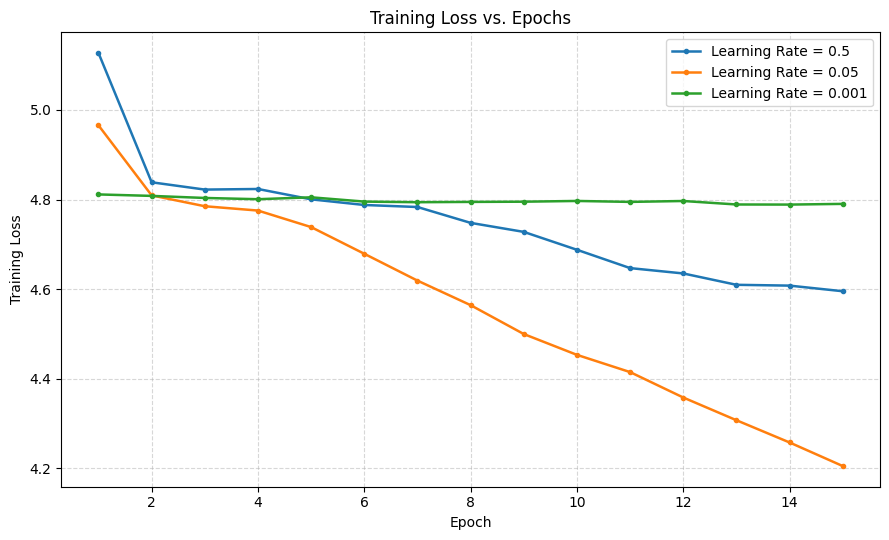

Saved: /content/AI6103_Assignment/figures/section3_training_loss.png


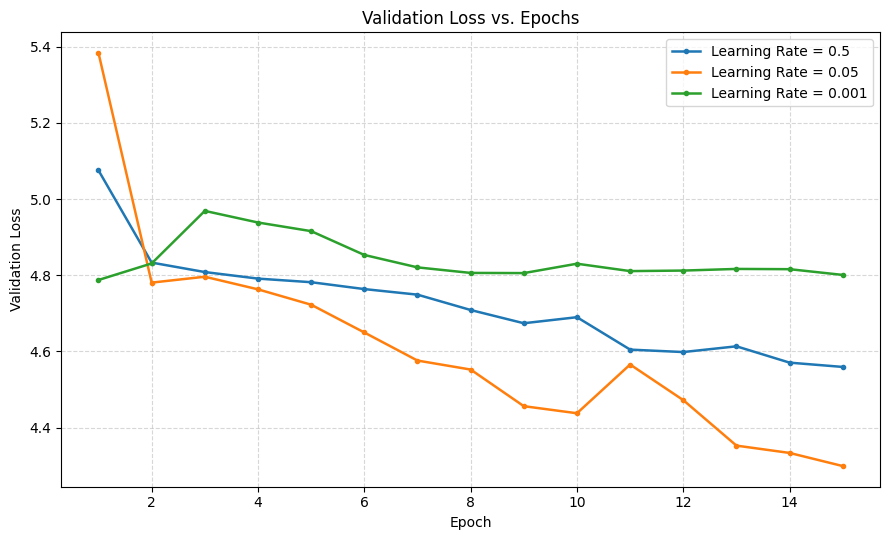

Saved: /content/AI6103_Assignment/figures/section3_validation_loss.png


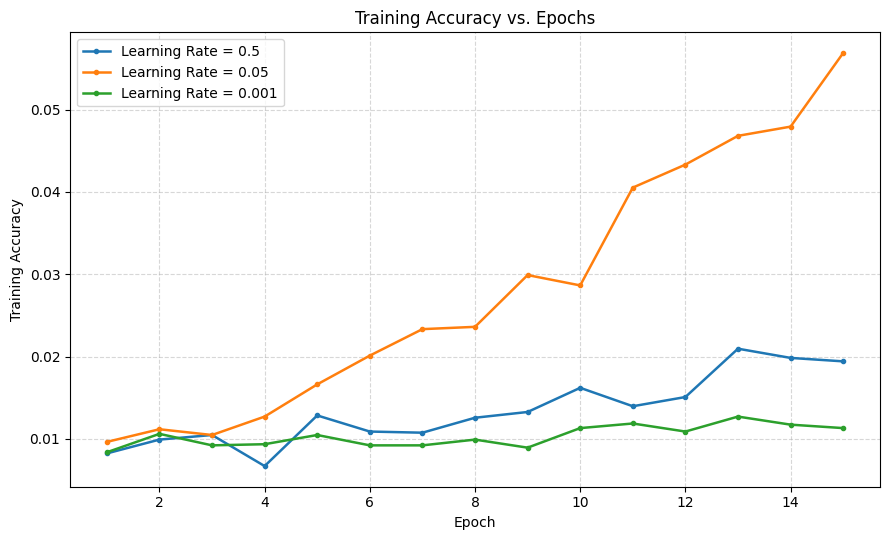

Saved: /content/AI6103_Assignment/figures/section3_training_accuracy.png


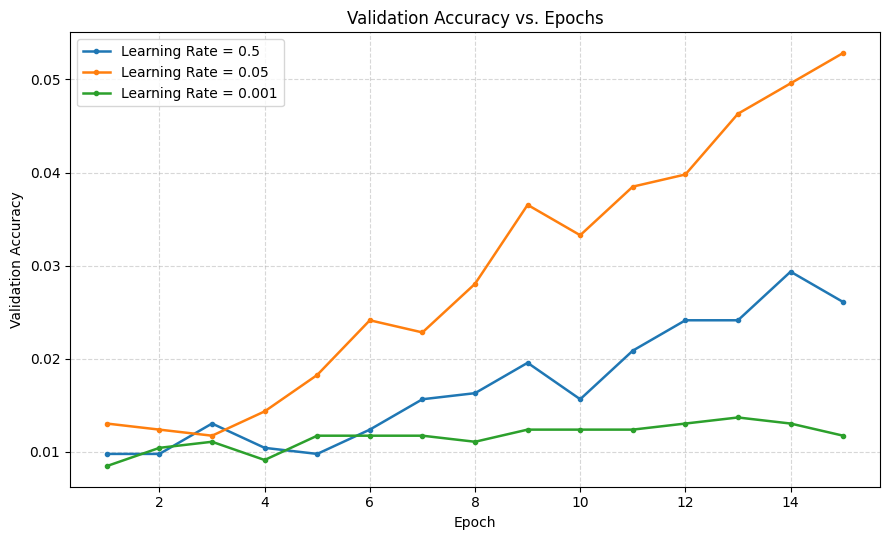

Saved: /content/AI6103_Assignment/figures/section3_validation_accuracy.png

Section 3 plots generated.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. Set paths
# ==========================================
PROJECT_DIR = Path("/content/AI6103_Assignment")
METRICS_PATH = PROJECT_DIR / "logs" / "epoch_metrics.csv"
FIGURES_DIR = PROJECT_DIR / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. Load training metrics
# ==========================================
if not METRICS_PATH.exists():
    raise FileNotFoundError(
        f"Metrics file not found: {METRICS_PATH}"
    )

df = pd.read_csv(METRICS_PATH)

print("Available columns:")
print(df.columns.tolist())

print("\nNumber of records:", len(df))

print("\nExperiments:")
print(df["experiment"].unique())

# Select the three learning-rate experiments
experiments = ["lr_0.5", "lr_0.05", "lr_0.001"]

df = df[df["experiment"].isin(experiments)].copy()

# Sort epochs to ensure correct plotting order
df = df.sort_values(["experiment", "epoch"])

# Check whether each experiment has 15 recorded epochs
print("\nEpoch counts:")
print(df.groupby("experiment")["epoch"].count())

# ==========================================
# 3. Define plotting function
# ==========================================
def plot_metric(metric, title, ylabel, filename):
    plt.figure(figsize=(9, 5.5))

    for experiment in experiments:
        subset = df[df["experiment"] == experiment]

        if subset.empty:
            print(f"Warning: no data found for {experiment}")
            continue

        # Display readable learning-rate labels
        label = experiment.replace("lr_", "Learning Rate = ")

        plt.plot(
            subset["epoch"],
            subset[metric],
            marker="o",
            markersize=3,
            linewidth=1.8,
            label=label
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()

    output_path = FIGURES_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Saved: {output_path}")

# ==========================================
# 4. Generate four figures
# ==========================================
plot_metric(
    metric="train_loss",
    title="Training Loss vs. Epochs",
    ylabel="Training Loss",
    filename="section3_training_loss.png"
)

plot_metric(
    metric="val_loss",
    title="Validation Loss vs. Epochs",
    ylabel="Validation Loss",
    filename="section3_validation_loss.png"
)

plot_metric(
    metric="train_accuracy",
    title="Training Accuracy vs. Epochs",
    ylabel="Training Accuracy",
    filename="section3_training_accuracy.png"
)

plot_metric(
    metric="val_accuracy",
    title="Validation Accuracy vs. Epochs",
    ylabel="Validation Accuracy",
    filename="section3_validation_accuracy.png"
)

print("\nSection 3 plots generated.")

In [ ]:
import torch
import pandas as pd
import inspect
from pathlib import Path

PROJECT_DIR = Path("/content/AI6103_Assignment")
METRICS_PATH = PROJECT_DIR / "logs" / "epoch_metrics.csv"

print("=" * 60)
print("1. Runtime")
print("=" * 60)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n" + "=" * 60)
print("2. DataLoaders")
print("=" * 60)

for name in ["train_loader", "val_loader", "test_loader"]:
    if name in globals():
        loader = globals()[name]
        print(
            f"{name}: "
            f"dataset_size={len(loader.dataset)}, "
            f"batch_size={loader.batch_size}, "
            f"num_batches={len(loader)}"
        )
    else:
        print(f"{name}: not found")

print("\n" + "=" * 60)
print("3. Existing training functions")
print("=" * 60)

for name, obj in list(globals().items()):
    if (
        callable(obj)
        and not name.startswith("_")
        and any(key in name.lower() for key in ["train", "experiment", "evaluate"])
    ):
        try:
            print(f"\nFunction: {name}")
            print("Signature:", inspect.signature(obj))
        except (ValueError, TypeError):
            pass

print("\n" + "=" * 60)
print("4. Metrics file")
print("=" * 60)

if METRICS_PATH.exists():
    metrics = pd.read_csv(METRICS_PATH)

    print("Columns:", metrics.columns.tolist())
    print("Total records:", len(metrics))

    if "experiment" in metrics.columns:
        print("\nRecorded experiments:")
        print(metrics["experiment"].value_counts().to_string())

    print("\nLast 3 records:")
    print(metrics.tail(3).to_string(index=False))
else:
    print("Metrics file not found.")

print("\n" + "=" * 60)
print("5. Existing checkpoints")
print("=" * 60)

checkpoint_dir = PROJECT_DIR / "checkpoints"

if checkpoint_dir.exists():
    for path in sorted(checkpoint_dir.glob("*.pth")):
        print(f"{path.name}: {path.stat().st_size / 1024**2:.2f} MB")

print("\nEnvironment inspection completed.")

1. Runtime
CUDA available: True
GPU: Tesla T4

2. DataLoaders
train_loader: dataset_size=7155, batch_size=128, num_batches=56
val_loader: dataset_size=1533, batch_size=128, num_batches=12
test_loader: dataset_size=1534, batch_size=128, num_batches=12

3. Existing training functions

Function: train_transform
Signature: (img)

Function: train_one_epoch
Signature: (model, loader, criterion, optimizer, scaler)

Function: evaluate
Signature: (model, loader, criterion)

Function: run_lr_experiment
Signature: (lr)

4. Metrics file
Columns: ['experiment', 'epoch', 'learning_rate', 'weight_decay', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'elapsed_seconds']
Total records: 45

Recorded experiments:
experiment
lr_0.5      15
lr_0.05     15
lr_0.001    15

Last 3 records:
experiment  epoch  learning_rate  weight_decay  train_loss  train_accuracy  val_loss  val_accuracy  elapsed_seconds
  lr_0.001     13          0.001           0.0    4.788885        0.012718  4.816587      0.01

In [ ]:
import inspect

print("=" * 70)
print("train_one_epoch")
print("=" * 70)
print(inspect.getsource(train_one_epoch))

print("\n" + "=" * 70)
print("evaluate")
print("=" * 70)
print(inspect.getsource(evaluate))

print("\n" + "=" * 70)
print("Model initialization")
print("=" * 70)

print(inspect.getsource(run_lr_experiment))

train_one_epoch
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=True
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"训练损失出现非有限值：{loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return (
   

In [ ]:
import os
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.optim.lr_scheduler import CosineAnnealingLR

# ==========================================
# 1. Project paths
# ==========================================
PROJECT_DIR = Path("/content/AI6103_Assignment")
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
LOG_DIR = PROJECT_DIR / "logs"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

for folder in [
    CHECKPOINT_DIR,
    LOG_DIR,
    RESULTS_DIR,
    FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

METRICS_PATH = LOG_DIR / "epoch_metrics.csv"

# ==========================================
# 2. Verify required variables
# ==========================================
required_variables = [
    "train_loader",
    "val_loader",
    "create_model",
    "train_one_epoch",
    "evaluate",
    "device"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        f"Missing required variables: {missing_variables}. "
        "Please rerun the corresponding setup cells."
    )

assert len(train_loader.dataset) == 7155
assert len(val_loader.dataset) == 1533

# ==========================================
# 3. Section 4 settings
# ==========================================
INITIAL_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0
BATCH_SIZE = 128
NUM_EPOCHS = 300

print("Section 4 configuration")
print("-" * 45)
print("Device:", device)
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))
print("Batch size:", train_loader.batch_size)
print("Initial learning rate:", INITIAL_LR)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs:", NUM_EPOCHS)
print("Metrics file:", METRICS_PATH)

# Check existing records to prevent accidental overwrite.
if METRICS_PATH.exists():
    existing_metrics = pd.read_csv(METRICS_PATH)

    print("\nExisting metric records:", len(existing_metrics))

    if "experiment" in existing_metrics.columns:
        print(
            existing_metrics["experiment"]
            .value_counts()
            .to_string()
        )

print("\nPreparation completed.")

Section 4 configuration
---------------------------------------------
Device: cuda
Training samples: 7155
Validation samples: 1533
Batch size: 128
Initial learning rate: 0.05
Momentum: 0.9
Weight decay: 0.0
Epochs: 300
Metrics file: /content/AI6103_Assignment/logs/epoch_metrics.csv

Existing metric records: 45
experiment
lr_0.5      15
lr_0.05     15
lr_0.001    15

Preparation completed.


In [ ]:
def run_section4_experiment(
    experiment,
    cosine_annealing=False,
    num_epochs=300
):
    """
    Section 4:
    Compare constant learning rate against cosine annealing.

    Resume from the latest checkpoint if one exists.
    """

    latest_path = CHECKPOINT_DIR / f"{experiment}_latest.pth"
    best_path = CHECKPOINT_DIR / f"{experiment}_best.pth"
    final_path = CHECKPOINT_DIR / f"{experiment}_final.pth"

    # ------------------------------------------
    # 1. Reproducible model initialization
    # ------------------------------------------
    set_seed(42)

    model = create_model()
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=INITIAL_LR,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")

    scheduler = None

    if cosine_annealing:
        scheduler = CosineAnnealingLR(
            optimizer,
            T_max=num_epochs,
            eta_min=0.0
        )

    start_epoch = 1
    best_val_accuracy = -1.0
    best_epoch = 0

    # ------------------------------------------
    # 2. Resume if a checkpoint exists
    # ------------------------------------------
    if latest_path.exists():
        checkpoint = torch.load(
            latest_path,
            map_location=device,
            weights_only=False
        )

        saved_epoch = int(checkpoint["epoch"])

        if saved_epoch > num_epochs:
            raise RuntimeError(
                f"Checkpoint epoch {saved_epoch} exceeds "
                f"requested epochs {num_epochs}."
            )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        if "scaler_state_dict" in checkpoint:
            scaler.load_state_dict(checkpoint["scaler_state_dict"])

        if cosine_annealing:
            if "scheduler_state_dict" not in checkpoint:
                raise RuntimeError(
                    "The checkpoint has no scheduler state. "
                    "Use a fresh experiment name to start from scratch."
                )

            scheduler.load_state_dict(
                checkpoint["scheduler_state_dict"]
            )

        start_epoch = saved_epoch + 1
        best_val_accuracy = checkpoint.get(
            "best_val_accuracy", -1.0
        )
        best_epoch = checkpoint.get("best_epoch", 0)

        print(
            f"Resuming {experiment} from epoch "
            f"{start_epoch}/{num_epochs}"
        )

    else:
        print(f"Starting a new experiment: {experiment}")

    # ------------------------------------------
    # 3. Ensure existing records are not duplicated
    # ------------------------------------------
    if METRICS_PATH.exists():
        metrics_df = pd.read_csv(METRICS_PATH)

        if "experiment" in metrics_df.columns:
            experiment_rows = metrics_df[
                metrics_df["experiment"] == experiment
            ]

            if not experiment_rows.empty:
                logged_epochs = set(
                    experiment_rows["epoch"].astype(int).tolist()
                )

                expected_logged_epochs = set(
                    range(1, start_epoch)
                )

                if logged_epochs != expected_logged_epochs:
                    raise RuntimeError(
                        f"Log/checkpoint mismatch for {experiment}. "
                        f"Logged epochs: {sorted(logged_epochs)[:5]}...; "
                        f"expected completed epochs: "
                        f"{sorted(expected_logged_epochs)[:5]}..."
                    )

    # ------------------------------------------
    # 4. Training
    # ------------------------------------------
    experiment_start = time.time()

    for epoch in range(start_epoch, num_epochs + 1):
        epoch_start = time.time()

        # Record the learning rate used in this epoch.
        current_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion
        )

        elapsed_seconds = time.time() - epoch_start

        # Save metrics after the epoch has completed.
        record = {
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": current_lr,
            "weight_decay": WEIGHT_DECAY,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "elapsed_seconds": elapsed_seconds
        }

        pd.DataFrame([record]).to_csv(
            METRICS_PATH,
            mode="a",
            header=(
                not METRICS_PATH.exists()
                or METRICS_PATH.stat().st_size == 0
            ),
            index=False
        )

        # Update best model based on validation accuracy.
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_checkpoint = {
                "experiment": experiment,
                "epoch": epoch,
                "learning_rate": current_lr,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "best_epoch": best_epoch,
                "cosine_annealing": cosine_annealing
            }

            if scheduler is not None:
                best_checkpoint["scheduler_state_dict"] = (
                    scheduler.state_dict()
                )

            torch.save(best_checkpoint, best_path)

        # Advance the learning-rate schedule after this epoch.
        if scheduler is not None:
            scheduler.step()

        # Save latest state for recovery.
        latest_checkpoint = {
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch,
            "cosine_annealing": cosine_annealing
        }

        if scheduler is not None:
            latest_checkpoint["scheduler_state_dict"] = (
                scheduler.state_dict()
            )

        temporary_path = latest_path.with_suffix(".tmp")

        torch.save(latest_checkpoint, temporary_path)
        os.replace(temporary_path, latest_path)

        print(
            f"{experiment} | "
            f"Epoch {epoch:03d}/{num_epochs} | "
            f"LR {current_lr:.7f} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_accuracy:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_accuracy:.4f} | "
            f"Time {elapsed_seconds:.1f}s"
        )

    # ------------------------------------------
    # 5. Save final model
    # ------------------------------------------
    final_checkpoint = {
        "experiment": experiment,
        "epoch": num_epochs,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "model_state_dict": model.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,
        "cosine_annealing": cosine_annealing
    }

    torch.save(final_checkpoint, final_path)

    elapsed_minutes = (time.time() - experiment_start) / 60

    print("\n" + "=" * 65)
    print("Experiment completed:", experiment)
    print("Best validation accuracy:", f"{best_val_accuracy:.4f}")
    print("Best epoch:", best_epoch)
    print("Elapsed time this session:", f"{elapsed_minutes:.2f} minutes")
    print("Best checkpoint:", best_path)
    print("Final checkpoint:", final_path)
    print("=" * 65)

    del model, optimizer, scaler, scheduler
    torch.cuda.empty_cache()

    return {
        "experiment": experiment,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "elapsed_minutes": elapsed_minutes
    }


print("Section 4 training function defined successfully.")

Section 4 training function defined successfully.


section 4 余弦退火

In [ ]:
def run_section4_experiment(
    experiment,
    cosine_annealing=False,
    num_epochs=300
):
    """
    Section 4:
    Compare constant learning rate against cosine annealing.

    Resume from the latest checkpoint if one exists.
    """

    latest_path = CHECKPOINT_DIR / f"{experiment}_latest.pth"
    best_path = CHECKPOINT_DIR / f"{experiment}_best.pth"
    final_path = CHECKPOINT_DIR / f"{experiment}_final.pth"

    # ------------------------------------------
    # 1. Reproducible model initialization
    # ------------------------------------------
    set_seed(42)

    model = create_model()
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=INITIAL_LR,
        momentum=MOMENTUM,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")

    scheduler = None

    if cosine_annealing:
        scheduler = CosineAnnealingLR(
            optimizer,
            T_max=num_epochs,
            eta_min=0.0
        )

    start_epoch = 1
    best_val_accuracy = -1.0
    best_epoch = 0

    # ------------------------------------------
    # 2. Resume if a checkpoint exists
    # ------------------------------------------
    if latest_path.exists():
        checkpoint = torch.load(
            latest_path,
            map_location=device,
            weights_only=False
        )

        saved_epoch = int(checkpoint["epoch"])

        if saved_epoch > num_epochs:
            raise RuntimeError(
                f"Checkpoint epoch {saved_epoch} exceeds "
                f"requested epochs {num_epochs}."
            )

        model.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

        if "scaler_state_dict" in checkpoint:
            scaler.load_state_dict(checkpoint["scaler_state_dict"])

        if cosine_annealing:
            if "scheduler_state_dict" not in checkpoint:
                raise RuntimeError(
                    "The checkpoint has no scheduler state. "
                    "Use a fresh experiment name to start from scratch."
                )

            scheduler.load_state_dict(
                checkpoint["scheduler_state_dict"]
            )

        start_epoch = saved_epoch + 1
        best_val_accuracy = checkpoint.get(
            "best_val_accuracy", -1.0
        )
        best_epoch = checkpoint.get("best_epoch", 0)

        print(
            f"Resuming {experiment} from epoch "
            f"{start_epoch}/{num_epochs}"
        )

    else:
        print(f"Starting a new experiment: {experiment}")

    # ------------------------------------------
    # 3. Ensure existing records are not duplicated
    # ------------------------------------------
    if METRICS_PATH.exists():
        metrics_df = pd.read_csv(METRICS_PATH)

        if "experiment" in metrics_df.columns:
            experiment_rows = metrics_df[
                metrics_df["experiment"] == experiment
            ]

            if not experiment_rows.empty:
                logged_epochs = set(
                    experiment_rows["epoch"].astype(int).tolist()
                )

                expected_logged_epochs = set(
                    range(1, start_epoch)
                )

                if logged_epochs != expected_logged_epochs:
                    raise RuntimeError(
                        f"Log/checkpoint mismatch for {experiment}. "
                        f"Logged epochs: {sorted(logged_epochs)[:5]}...; "
                        f"expected completed epochs: "
                        f"{sorted(expected_logged_epochs)[:5]}..."
                    )

    # ------------------------------------------
    # 4. Training
    # ------------------------------------------
    experiment_start = time.time()

    for epoch in range(start_epoch, num_epochs + 1):
        epoch_start = time.time()

        # Record the learning rate used in this epoch.
        current_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion
        )

        elapsed_seconds = time.time() - epoch_start

        # Save metrics after the epoch has completed.
        record = {
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": current_lr,
            "weight_decay": WEIGHT_DECAY,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "elapsed_seconds": elapsed_seconds
        }

        pd.DataFrame([record]).to_csv(
            METRICS_PATH,
            mode="a",
            header=(
                not METRICS_PATH.exists()
                or METRICS_PATH.stat().st_size == 0
            ),
            index=False
        )

        # Update best model based on validation accuracy.
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_checkpoint = {
                "experiment": experiment,
                "epoch": epoch,
                "learning_rate": current_lr,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "best_epoch": best_epoch,
                "cosine_annealing": cosine_annealing
            }

            if scheduler is not None:
                best_checkpoint["scheduler_state_dict"] = (
                    scheduler.state_dict()
                )

            torch.save(best_checkpoint, best_path)

        # Advance the learning-rate schedule after this epoch.
        if scheduler is not None:
            scheduler.step()

        # Save latest state for recovery.
        latest_checkpoint = {
            "experiment": experiment,
            "epoch": epoch,
            "learning_rate": optimizer.param_groups[0]["lr"],
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "best_val_accuracy": best_val_accuracy,
            "best_epoch": best_epoch,
            "cosine_annealing": cosine_annealing
        }

        if scheduler is not None:
            latest_checkpoint["scheduler_state_dict"] = (
                scheduler.state_dict()
            )

        temporary_path = latest_path.with_suffix(".tmp")

        torch.save(latest_checkpoint, temporary_path)
        os.replace(temporary_path, latest_path)

        print(
            f"{experiment} | "
            f"Epoch {epoch:03d}/{num_epochs} | "
            f"LR {current_lr:.7f} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_accuracy:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_accuracy:.4f} | "
            f"Time {elapsed_seconds:.1f}s"
        )

    # ------------------------------------------
    # 5. Save final model
    # ------------------------------------------
    final_checkpoint = {
        "experiment": experiment,
        "epoch": num_epochs,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "model_state_dict": model.state_dict(),
        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,
        "cosine_annealing": cosine_annealing
    }

    torch.save(final_checkpoint, final_path)

    elapsed_minutes = (time.time() - experiment_start) / 60

    print("\n" + "=" * 65)
    print("Experiment completed:", experiment)
    print("Best validation accuracy:", f"{best_val_accuracy:.4f}")
    print("Best epoch:", best_epoch)
    print("Elapsed time this session:", f"{elapsed_minutes:.2f} minutes")
    print("Best checkpoint:", best_path)
    print("Final checkpoint:", final_path)
    print("=" * 65)

    del model, optimizer, scaler, scheduler
    torch.cuda.empty_cache()

    return {
        "experiment": experiment,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "elapsed_minutes": elapsed_minutes
    }


print("Section 4 training function defined successfully.")

Section 4 training function defined successfully.


In [ ]:
result_constant = run_section4_experiment(
    experiment="section4_constant",
    cosine_annealing=False,
    num_epochs=300
)

Starting a new experiment: section4_constant
section4_constant | Epoch 001/300 | LR 0.0500000 | Train Loss 4.9461 | Train Acc 0.0102 | Val Loss 5.0869 | Val Acc 0.0111 | Time 24.8s
section4_constant | Epoch 002/300 | LR 0.0500000 | Train Loss 4.8175 | Train Acc 0.0117 | Val Loss 4.7802 | Val Acc 0.0144 | Time 27.3s
section4_constant | Epoch 003/300 | LR 0.0500000 | Train Loss 4.7768 | Train Acc 0.0123 | Val Loss 4.7677 | Val Acc 0.0189 | Time 25.1s
section4_constant | Epoch 004/300 | LR 0.0500000 | Train Loss 4.7341 | Train Acc 0.0162 | Val Loss 4.7279 | Val Acc 0.0183 | Time 24.7s
section4_constant | Epoch 005/300 | LR 0.0500000 | Train Loss 4.6845 | Train Acc 0.0155 | Val Loss 4.7199 | Val Acc 0.0267 | Time 25.2s
section4_constant | Epoch 006/300 | LR 0.0500000 | Train Loss 4.6338 | Train Acc 0.0228 | Val Loss 4.6246 | Val Acc 0.0222 | Time 25.7s
section4_constant | Epoch 007/300 | LR 0.0500000 | Train Loss 4.5741 | Train Acc 0.0267 | Val Loss 4.6697 | Val Acc 0.0261 | Time 25.6s
sec

In [ ]:
import json
import zipfile
import pandas as pd
from pathlib import Path
from datetime import datetime

# ==========================================
# 1. Define project paths
# ==========================================
PROJECT_DIR = Path("/content/AI6103_Assignment")

METRICS_PATH = PROJECT_DIR / "logs" / "epoch_metrics.csv"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
CONFIG_DIR = PROJECT_DIR / "config"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. Verify training records
# ==========================================
if not METRICS_PATH.exists():
    raise FileNotFoundError(f"Metrics file missing: {METRICS_PATH}")

metrics = pd.read_csv(METRICS_PATH)

print("=" * 60)
print("Training records verification")
print("=" * 60)

print("Total records:", len(metrics))
print("\nEpoch counts:")
print(metrics.groupby("experiment")["epoch"].count())

expected_epochs = {
    "lr_0.5": 15,
    "lr_0.05": 15,
    "lr_0.001": 15,
    "section4_constant": 300
}

for experiment, expected in expected_epochs.items():
    actual = int(
        (metrics["experiment"] == experiment).sum()
    )

    if actual != expected:
        raise RuntimeError(
            f"{experiment}: expected {expected} records, "
            f"but found {actual}. Please investigate before backup."
        )

print("\nAll completed experiments have the expected record counts.")

# ==========================================
# 3. Generate experiment summary
# ==========================================
summary_rows = []

for experiment, group in metrics.groupby("experiment"):
    group = group.sort_values("epoch")

    best_idx = group["val_accuracy"].idxmax()
    best_row = group.loc[best_idx]
    final_row = group.iloc[-1]

    summary_rows.append({
        "experiment": experiment,
        "epochs_recorded": len(group),
        "best_epoch": int(best_row["epoch"]),
        "best_val_accuracy": float(best_row["val_accuracy"]),
        "best_val_loss": float(best_row["val_loss"]),
        "final_train_loss": float(final_row["train_loss"]),
        "final_train_accuracy": float(final_row["train_accuracy"]),
        "final_val_loss": float(final_row["val_loss"]),
        "final_val_accuracy": float(final_row["val_accuracy"])
    })

summary_df = pd.DataFrame(summary_rows)

SUMMARY_PATH = RESULTS_DIR / "experiment_summary_20261020.csv"
summary_df.to_csv(SUMMARY_PATH, index=False)

print("\nExperiment summary:")
print(summary_df.to_string(index=False))

# ==========================================
# 4. Prepare important files
# ==========================================
files_to_backup = [
    METRICS_PATH,
    SUMMARY_PATH
]

# Include config files.
if CONFIG_DIR.exists():
    files_to_backup.extend(
        path for path in CONFIG_DIR.rglob("*")
        if path.is_file()
    )

# Include all figures.
if FIGURES_DIR.exists():
    files_to_backup.extend(
        path for path in FIGURES_DIR.rglob("*")
        if path.is_file()
    )

# Include existing experiment result files, excluding the summary above.
if RESULTS_DIR.exists():
    files_to_backup.extend(
        path for path in RESULTS_DIR.rglob("*")
        if path.is_file()
        and path != SUMMARY_PATH
        and not path.name.endswith(".zip")
    )

# Include the important trained checkpoints.
checkpoint_names = [
    "lr_0.5_best.pth",
    "lr_0.05_best.pth",
    "lr_0.001_best.pth",
    "section4_constant_best.pth",
    "section4_constant_final.pth",
    "section4_constant_latest.pth"
]

for name in checkpoint_names:
    path = CHECKPOINT_DIR / name

    if path.exists():
        files_to_backup.append(path)
    else:
        print(f"WARNING: Checkpoint not found: {name}")

# Remove duplicate paths.
files_to_backup = list(dict.fromkeys(files_to_backup))

# ==========================================
# 5. Write backup manifest
# ==========================================
manifest = {
    "backup_date": datetime.now().isoformat(timespec="seconds"),
    "project": "AI6103 Assignment",
    "completed_experiments": expected_epochs,
    "total_expected_metric_records": sum(expected_epochs.values()),
    "included_files": [
        str(path.relative_to(PROJECT_DIR))
        for path in files_to_backup
    ],
    "notes": [
        "Section 3 learning-rate experiments completed.",
        "Section 4 constant learning-rate experiment completed.",
        "Section 4 cosine annealing experiment not yet completed.",
        "Test set has not been used for final evaluation."
    ]
}

manifest_path = RESULTS_DIR / "backup_manifest_20261020.json"

with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

files_to_backup.append(manifest_path)

# ==========================================
# 6. Create ZIP archive
# ==========================================
backup_path = PROJECT_DIR / "AI6103_backup_20261020.zip"

with zipfile.ZipFile(
    backup_path,
    mode="w",
    compression=zipfile.ZIP_STORED
) as zf:

    for path in files_to_backup:
        if path.exists() and path.is_file():
            archive_name = str(path.relative_to(PROJECT_DIR))
            zf.write(path, arcname=archive_name)

print("\n" + "=" * 60)
print("BACKUP COMPLETED")
print("=" * 60)
print("Backup path:", backup_path)
print(f"Backup size: {backup_path.stat().st_size / 1024**3:.2f} GB")
print("Files included:", len(files_to_backup))
print("Manifest:", manifest_path)

Training records verification
Total records: 345

Epoch counts:
experiment
lr_0.001              15
lr_0.05               15
lr_0.5                15
section4_constant    300
Name: epoch, dtype: int64

All completed experiments have the expected record counts.

Experiment summary:
       experiment  epochs_recorded  best_epoch  best_val_accuracy  best_val_loss  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy
         lr_0.001               15          13           0.013699       4.816587          4.790226              0.011321        4.800831            0.011742
          lr_0.05               15          15           0.052838       4.299208          4.204805              0.056883        4.299208            0.052838
           lr_0.5               15          14           0.029354       4.570632          4.595162              0.019427        4.559375            0.026093
section4_constant              300         171           0.196999       8.124753          

In [ ]:
import os
import shutil
import zipfile
from pathlib import Path

from google.colab import drive

# ==========================================
# 1. Mount Google Drive
# ==========================================
drive.mount("/content/drive")

# ==========================================
# 2. Define paths
# ==========================================
PROJECT_DIR = Path("/content/AI6103_Assignment")

DRIVE_ZIP = Path(
    "/content/drive/MyDrive/AI6103_Assignment/"
    "dataset/dog_breed_dataset.zip"
)

LOCAL_DATA_DIR = PROJECT_DIR / "dataset"
LOCAL_ZIP = LOCAL_DATA_DIR / "dog_breed_dataset.zip"
EXTRACT_DIR = LOCAL_DATA_DIR / "extracted"
DATA_DIR = EXTRACT_DIR / "data"

# Create directories
LOCAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 3. Check the original dataset archive
# ==========================================
if not DRIVE_ZIP.exists():
    raise FileNotFoundError(
        f"Dataset archive not found in Google Drive:\n{DRIVE_ZIP}"
    )

drive_size = DRIVE_ZIP.stat().st_size

print("=" * 60)
print("Original dataset archive")
print("=" * 60)
print("Path:", DRIVE_ZIP)
print(f"Size: {drive_size:,} bytes")
print(f"Size: {drive_size / 1024**2:.2f} MB")

# ==========================================
# 4. Copy archive to Colab local storage
# ==========================================
if (
    not LOCAL_ZIP.exists()
    or LOCAL_ZIP.stat().st_size != drive_size
):
    print("\nCopying dataset to local storage...")

    shutil.copy2(DRIVE_ZIP, LOCAL_ZIP)

else:
    print("\nA matching local archive already exists.")
    print("Skipping copy.")

# Verify copied file size
local_size = LOCAL_ZIP.stat().st_size

if local_size != drive_size:
    raise RuntimeError(
        f"File size mismatch!\n"
        f"Drive: {drive_size}\n"
        f"Local: {local_size}"
    )

print("\nDataset archive copied successfully.")
print(f"Local archive size: {local_size:,} bytes")

# ==========================================
# 5. Verify ZIP integrity
# ==========================================
print("\nChecking ZIP integrity...")

with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
    bad_file = zf.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Corrupted file found inside ZIP: {bad_file}"
        )

    print("ZIP integrity check passed.")
    print("Files in archive:", len(zf.namelist()))

# ==========================================
# 6. Extract dataset
# ==========================================
if not DATA_DIR.exists():
    print("\nExtracting dataset...")

    with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
        zf.extractall(EXTRACT_DIR)

else:
    print("\nExtracted dataset directory already exists.")
    print("Skipping extraction.")

# ==========================================
# 7. Verify expected directory structure
# ==========================================
expected_paths = [
    DATA_DIR / "train" / "images",
    DATA_DIR / "train" / "train_labels.csv",
    DATA_DIR / "val" / "images",
    DATA_DIR / "val" / "val_labels.csv",
    DATA_DIR / "test" / "images",
    DATA_DIR / "test" / "test_labels.csv",
]

print("\n" + "=" * 60)
print("Dataset structure verification")
print("=" * 60)

for path in expected_paths:
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {path}")

missing_paths = [
    path for path in expected_paths
    if not path.exists()
]

if missing_paths:
    print(
        "\nThe dataset structure differs from the expected layout. "
        "Stop here and send me the output."
    )
else:
    print("\nDataset loading completed successfully.")
    print("Dataset root:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Original dataset archive
Path: /content/drive/MyDrive/AI6103_Assignment/dataset/dog_breed_dataset.zip
Size: 361,582,673 bytes
Size: 344.83 MB

Copying dataset to local storage...

Dataset archive copied successfully.
Local archive size: 361,582,673 bytes

Checking ZIP integrity...
ZIP integrity check passed.
Files in archive: 10232

Extracting dataset...

Dataset structure verification
[OK] /content/AI6103_Assignment/dataset/extracted/data/train/images
[MISSING] /content/AI6103_Assignment/dataset/extracted/data/train/train_labels.csv
[OK] /content/AI6103_Assignment/dataset/extracted/data/val/images
[MISSING] /content/AI6103_Assignment/dataset/extracted/data/val/val_labels.csv
[OK] /content/AI6103_Assignment/dataset/extracted/data/test/images
[MISSING] /content/AI6103_Assignment/dataset/extracted/data/test/test_labels.csv

The dataset structure differs from th

In [ ]:
import zipfile
from pathlib import Path

LOCAL_ZIP = Path("/content/AI6103_Assignment/dataset/dog_breed_dataset.zip")
EXTRACT_DIR = Path("/content/AI6103_Assignment/dataset/extracted")

print("=" * 60)
print("1. CSV files inside the ZIP archive")
print("=" * 60)

with zipfile.ZipFile(LOCAL_ZIP, "r") as zf:
    all_files = zf.namelist()

    csv_files = [
        name for name in all_files
        if name.lower().endswith(".csv")
    ]

    print(f"Total CSV files found: {len(csv_files)}")

    for name in csv_files[:100]:
        print(name)

print("\n" + "=" * 60)
print("2. Top-level paths inside the ZIP archive")
print("=" * 60)

top_level = sorted({
    name.split("/")[0]
    for name in all_files
    if name.strip("/")
})

for name in top_level:
    print(name)

print("\n" + "=" * 60)
print("3. CSV files already extracted")
print("=" * 60)

if EXTRACT_DIR.exists():
    extracted_csvs = sorted(EXTRACT_DIR.rglob("*.csv"))

    print(f"Total extracted CSV files found: {len(extracted_csvs)}")

    for path in extracted_csvs[:100]:
        print(path)
else:
    print("Extraction directory does not exist.")

1. CSV files inside the ZIP archive
Total CSV files found: 3
data/test_labels.csv
data/train_labels.csv
data/val_labels.csv

2. Top-level paths inside the ZIP archive
data

3. CSV files already extracted
Total extracted CSV files found: 3
/content/AI6103_Assignment/dataset/extracted/data/test_labels.csv
/content/AI6103_Assignment/dataset/extracted/data/train_labels.csv
/content/AI6103_Assignment/dataset/extracted/data/val_labels.csv


In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/AI6103_Assignment/dataset/extracted/data")

print("=" * 60)
print("1. Label CSV structure")
print("=" * 60)

for split in ["train", "val", "test"]:
    csv_path = DATA_DIR / f"{split}_labels.csv"
    df = pd.read_csv(csv_path)

    print(f"\n[{split.upper()}]")
    print(f"CSV path: {csv_path}")
    print(f"Shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    print("First 5 rows:")
    print(df.head().to_string(index=False))

print("\n" + "=" * 60)
print("2. Image directory structure")
print("=" * 60)

for split in ["train", "val", "test"]:
    image_dir = DATA_DIR / split / "images"

    print(f"\n[{split.upper()}]")
    print(f"Image directory exists: {image_dir.exists()}")

    if image_dir.exists():
        image_files = [
            p for p in image_dir.iterdir()
            if p.is_file()
        ]

        print(f"Number of files: {len(image_files)}")
        print("First 5 filenames:")
        for path in sorted(image_files)[:5]:
            print(f"  {path.name}")

1. Label CSV structure

[TRAIN]
CSV path: /content/AI6103_Assignment/dataset/extracted/data/train_labels.csv
Shape: (7155, 2)
Columns: ['id', 'breed']
First 5 rows:
                              id            breed
be9686a8b005707ab13d8f5dff1d7431     newfoundland
6366e33e378df764b143dbae6809b756           beagle
1609abf6c6ac2e8df0af837cbe9cee74 mexican_hairless
478c1ceb68afd4e6be917ea8367a71bd     ibizan_hound
265d3babc4f879da3b9898ed77d5b585           vizsla

[VAL]
CSV path: /content/AI6103_Assignment/dataset/extracted/data/val_labels.csv
Shape: (1533, 2)
Columns: ['id', 'breed']
First 5 rows:
                              id            breed
ad282d2da0cc82233dbc487e8ca80aed          samoyed
70f2fd56f61deb7daaeb72b8664cec9a miniature_poodle
9463bed0f3812eee19c6bf929e679638 blenheim_spaniel
8898c34ad05d2c95319ff2a2f326e69c    saint_bernard
01e2245b46eb747260ff80f1c892daef brittany_spaniel

[TEST]
CSV path: /content/AI6103_Assignment/dataset/extracted/data/test_labels.csv
Shape: (1534,

In [ ]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/AI6103_Assignment/dataset/extracted/data")

splits = {
    "train": {
        "csv": DATA_DIR / "train_labels.csv",
        "images": DATA_DIR / "train" / "images",
    },
    "val": {
        "csv": DATA_DIR / "val_labels.csv",
        "images": DATA_DIR / "val" / "images",
    },
    "test": {
        "csv": DATA_DIR / "test_labels.csv",
        "images": DATA_DIR / "test" / "images",
    },
}

all_image_ids = {}
all_labels = {}

print("=" * 65)
print("Dataset Integrity Check")
print("=" * 65)

for split, paths in splits.items():
    df = pd.read_csv(paths["csv"])

    # CSV 中的 id 不带 .jpg 后缀
    label_ids = set(df["id"].astype(str))
    image_ids = {
        p.stem
        for p in paths["images"].iterdir()
        if p.is_file() and p.suffix.lower() == ".jpg"
    }

    missing_images = label_ids - image_ids
    missing_labels = image_ids - label_ids

    all_image_ids[split] = image_ids
    all_labels[split] = set(df["breed"].astype(str))

    print(f"\n[{split.upper()}]")
    print(f"CSV rows: {len(df)}")
    print(f"Unique image IDs in CSV: {df['id'].nunique()}")
    print(f"JPG images: {len(image_ids)}")
    print(f"Unique breeds: {df['breed'].nunique()}")
    print(f"Missing image files: {len(missing_images)}")
    print(f"Images without labels: {len(missing_labels)}")
    print(f"Duplicate CSV IDs: {df['id'].duplicated().sum()}")

    if missing_images:
        print("Examples of missing images:", list(missing_images)[:5])

    if missing_labels:
        print("Examples of images without labels:", list(missing_labels)[:5])

print("\n" + "=" * 65)
print("Class and Split Checks")
print("=" * 65)

train_classes = all_labels["train"]

print(f"Training classes: {len(train_classes)}")
print(f"Validation classes: {len(all_labels['val'])}")
print(f"Test classes: {len(all_labels['test'])}")

for split in ["val", "test"]:
    unseen_classes = all_labels[split] - train_classes
    print(f"{split.upper()} classes absent from training: {len(unseen_classes)}")
    if unseen_classes:
        print("Examples:", sorted(unseen_classes)[:10])

for split_a, split_b in [
    ("train", "val"),
    ("train", "test"),
    ("val", "test"),
]:
    overlap = all_image_ids[split_a] & all_image_ids[split_b]
    print(f"Image overlap ({split_a} vs {split_b}): {len(overlap)}")

Dataset Integrity Check


FileNotFoundError: [Errno 2] No such file or directory: '/content/AI6103_Assignment/dataset/extracted/data/train_labels.csv'

In [ ]:
from pathlib import Path

DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")
LOCAL_PROJECT = Path("/content/AI6103_Assignment")

print("=" * 65)
print("1. Google Drive project files")
print("=" * 65)

if not DRIVE_PROJECT.exists():
    print(f"Project directory not found: {DRIVE_PROJECT}")
else:
    for folder_name in ["logs", "checkpoints", "figures", "results", "config"]:
        folder = DRIVE_PROJECT / folder_name
        print(f"\n[{folder_name}]")

        if not folder.exists():
            print("  Directory not found")
            continue

        files = sorted(p for p in folder.rglob("*") if p.is_file())
        print(f"  File count: {len(files)}")

        for path in files[:30]:
            size_mb = path.stat().st_size / (1024 * 1024)
            print(f"  {path.relative_to(DRIVE_PROJECT)} ({size_mb:.2f} MB)")

        if len(files) > 30:
            print(f"  ... and {len(files) - 30} more files")

print("\n" + "=" * 65)
print("2. Local project files")
print("=" * 65)

for folder_name in ["logs", "checkpoints", "figures", "results", "config"]:
    folder = LOCAL_PROJECT / folder_name
    print(f"\n[{folder_name}]")

    if not folder.exists():
        print("  Directory not found")
        continue

    files = sorted(p for p in folder.rglob("*") if p.is_file())
    print(f"  File count: {len(files)}")

    for path in files[:15]:
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"  {path.relative_to(LOCAL_PROJECT)} ({size_mb:.2f} MB)")

1. Google Drive project files

[logs]
  File count: 1
  logs/progress.md (0.00 MB)

[checkpoints]
  File count: 0

[figures]
  File count: 0

[results]
  File count: 0

[config]
  File count: 2
  config/class_mapping.csv (0.00 MB)
  config/experiment_config.json (0.00 MB)

2. Local project files

[logs]
  Directory not found

[checkpoints]
  Directory not found

[figures]
  Directory not found

[results]
  Directory not found

[config]
  Directory not found


In [ ]:
from pathlib import Path
import json

DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")

# 1. 查看实验进度记录
progress_path = DRIVE_PROJECT / "logs" / "progress.md"

print("=" * 65)
print("1. Experiment progress.md")
print("=" * 65)

if progress_path.exists():
    print(progress_path.read_text(encoding="utf-8"))
else:
    print("progress.md not found.")

# 2. 查看实验配置
config_path = DRIVE_PROJECT / "config" / "experiment_config.json"

print("\n" + "=" * 65)
print("2. Experiment configuration")
print("=" * 65)

if config_path.exists():
    try:
        config = json.loads(config_path.read_text(encoding="utf-8"))
        print(json.dumps(config, indent=2, ensure_ascii=False))
    except Exception as e:
        print(f"Could not parse JSON: {e}")
        print(config_path.read_text(encoding="utf-8"))
else:
    print("experiment_config.json not found.")

# 3. 查看类别映射文件
mapping_path = DRIVE_PROJECT / "config" / "class_mapping.csv"

print("\n" + "=" * 65)
print("3. Class mapping")
print("=" * 65)

if mapping_path.exists():
    import pandas as pd
    mapping = pd.read_csv(mapping_path)
    print(f"Shape: {mapping.shape}")
    print(f"Columns: {mapping.columns.tolist()}")
    print(mapping.head(10).to_string(index=False))
else:
    print("class_mapping.csv not found.")

1. Experiment progress.md
# AI6103 Assignment Progress

Last completed stage:
- Dataset extracted to Google Drive
- Dataset integrity checked
- All three splits contain 120 classes
- No missing or unreadable images detected
- No duplicate IDs or cross-split ID overlap detected
- Training-set RGB mean and standard deviation calculated
- Dataset loading pipeline verified

Dataset:
- Training samples: 7155
- Validation samples: 1533
- Test samples: 1534
- Number of classes: 120

Image preprocessing:
- Resize: 100 x 100
- Training augmentation: random horizontal flip (p=0.5)
- Training augmentation: zero padding of 12 pixels
- Training augmentation: random crop to 100 x 100
- Normalization mean: [0.4771834057763069, 0.4527636099287068, 0.3927860050343754]
- Normalization std: [0.25341599247313307, 0.24796733174129357, 0.25226678270663994]

Model:
- EfficientNetV2-S
- Random initialization, no pretrained weights
- Number of output classes: 120

Next stage:
- Implement model, training loop a

In [ ]:
from pathlib import Path
import os

print("=" * 65)
print("1. Search local storage for experiment checkpoints")
print("=" * 65)

search_roots = [
    Path("/content"),
    Path("/root"),
]

checkpoint_names = [
    "section4_constant_latest.pth",
    "section4_constant_best.pth",
    "lr_0.05_best.pth",
    "lr_0.05_final.pth",
]

found_checkpoints = []

for root in search_roots:
    if not root.exists():
        continue

    for checkpoint_name in checkpoint_names:
        try:
            matches = list(root.rglob(checkpoint_name))
            for path in matches:
                if path.is_file():
                    found_checkpoints.append(path)
                    size_mb = path.stat().st_size / (1024 * 1024)
                    print(f"[FOUND] {path} ({size_mb:.2f} MB)")
        except (PermissionError, OSError):
            pass

if not found_checkpoints:
    print("No matching checkpoints found in local storage.")

print("\n" + "=" * 65)
print("2. Search Google Drive for experiment artifacts")
print("=" * 65)

drive_root = Path("/content/drive/MyDrive/AI6103_Assignment")

artifact_extensions = {".pth", ".pt", ".csv", ".png", ".jpg", ".json"}

found_artifacts = []

for path in drive_root.rglob("*"):
    if path.is_file() and path.suffix.lower() in artifact_extensions:
        # Skip the original dataset archive and dataset files.
        if "dataset" in path.parts:
            continue

        found_artifacts.append(path)
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"{path.relative_to(drive_root)} ({size_mb:.2f} MB)")

if not found_artifacts:
    print("No experiment artifacts found in Google Drive.")

print("\n" + "=" * 65)
print("3. Current runtime")
print("=" * 65)

print("Project directory exists:",
      Path("/content/AI6103_Assignment").exists())
print("CUDA available:")

try:
    import torch
    print(torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    print("PyTorch check failed:", repr(e))

1. Search local storage for experiment checkpoints
No matching checkpoints found in local storage.

2. Search Google Drive for experiment artifacts
config/experiment_config.json (0.00 MB)
config/class_mapping.csv (0.00 MB)

3. Current runtime
Project directory exists: True
CUDA available:
True
GPU: Tesla T4


In [ ]:
from pathlib import Path
import json
import shutil
import pandas as pd
import torch
import torchvision

# ============================================================
# 1. Define project paths
# ============================================================
DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")
LOCAL_PROJECT = Path("/content/AI6103_Assignment")

DATA_DIR = LOCAL_PROJECT / "dataset" / "extracted" / "data"

DRIVE_CHECKPOINT_DIR = DRIVE_PROJECT / "checkpoints"
DRIVE_LOG_DIR = DRIVE_PROJECT / "logs"
DRIVE_FIGURE_DIR = DRIVE_PROJECT / "figures"
DRIVE_RESULT_DIR = DRIVE_PROJECT / "results"

LOCAL_CHECKPOINT_DIR = LOCAL_PROJECT / "checkpoints"
LOCAL_LOG_DIR = LOCAL_PROJECT / "logs"
LOCAL_FIGURE_DIR = LOCAL_PROJECT / "figures"
LOCAL_RESULT_DIR = LOCAL_PROJECT / "results"

# ============================================================
# 2. Create directories locally and in Google Drive
# ============================================================
for directory in [
    LOCAL_CHECKPOINT_DIR,
    LOCAL_LOG_DIR,
    LOCAL_FIGURE_DIR,
    LOCAL_RESULT_DIR,
    DRIVE_CHECKPOINT_DIR,
    DRIVE_LOG_DIR,
    DRIVE_FIGURE_DIR,
    DRIVE_RESULT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# ============================================================
# 3. Restore saved configuration
# ============================================================
config_path = DRIVE_PROJECT / "config" / "experiment_config.json"

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

MEAN = config["normalization"]["mean_rgb"]
STD = config["normalization"]["std_rgb"]

IMAGE_SIZE = tuple(config["image_size"])
BATCH_SIZE = config["batch_size"]
NUM_CLASSES = config["num_classes"]

CLASS_NAMES = config["classes"]
CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}
IDX_TO_CLASS = {
    idx: name for name, idx in CLASS_TO_IDX.items()
}

# ============================================================
# 4. Define experiment parameters
# ============================================================
INITIAL_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0
NUM_EPOCHS = 300

# Append-only training metrics
METRICS_PATH = LOCAL_LOG_DIR / "epoch_metrics.csv"
DRIVE_METRICS_PATH = DRIVE_LOG_DIR / "epoch_metrics.csv"

# ============================================================
# 5. Verify environment and paths
# ============================================================
print("=" * 65)
print("Project environment restored")
print("=" * 65)

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset directory exists:", DATA_DIR.exists())
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Normalization mean:", MEAN)
print("Normalization std:", STD)

print("\nLocal project:", LOCAL_PROJECT)
print("Google Drive project:", DRIVE_PROJECT)

print("\nCheckpoint directory:", DRIVE_CHECKPOINT_DIR)
print("Metrics file:", DRIVE_METRICS_PATH)

print("\nAll required directories have been created.")

Project environment restored
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4

Dataset directory exists: False
Number of classes: 120
Image size: (100, 100)
Batch size: 128
Normalization mean: [0.4771834057763069, 0.4527636099287068, 0.3927860050343754]
Normalization std: [0.25341599247313307, 0.24796733174129357, 0.25226678270663994]

Local project: /content/AI6103_Assignment
Google Drive project: /content/drive/MyDrive/AI6103_Assignment

Checkpoint directory: /content/drive/MyDrive/AI6103_Assignment/checkpoints
Metrics file: /content/drive/MyDrive/AI6103_Assignment/logs/epoch_metrics.csv

All required directories have been created.


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
# Create model
model = create_model().to(device)

num_parameters = sum(
    parameter.numel() for parameter in model.parameters()
)

print("=" * 65)
print("Dataset and DataLoader verification")
print("=" * 65)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("\nTraining batch image shape:", tuple(images.shape))
print("Training batch label shape:", tuple(labels.shape))

print("\n" + "=" * 65)
print("Model verification")
print("=" * 65)

print("Architecture: EfficientNetV2-S")
print("Pretrained weights: None")
print("Output classes:", NUM_CLASSES)
print(f"Total parameters: {num_parameters:,}")

model.eval()

with torch.no_grad():
    sample_output = model(images[:2].to(device))

print("Model output shape:", tuple(sample_output.shape))

assert sample_output.shape == (2, NUM_CLASSES)

print("\nAll checks passed.")

NameError: name 'create_model' is not defined

In [ ]:
import os
import csv
import time
import random
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.amp import GradScaler

# ============================================================
# 1. Experiment settings
# ============================================================
SEED = 42
INITIAL_LR = 0.05
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0
NUM_EPOCHS = 300

METRIC_COLUMNS = [
    "experiment",
    "epoch",
    "learning_rate",
    "weight_decay",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "elapsed_seconds",
]

METRICS_PATH = LOCAL_LOG_DIR / "epoch_metrics.csv"
DRIVE_METRICS_PATH = DRIVE_LOG_DIR / "epoch_metrics.csv"

# ============================================================
# 2. Seed function
# ============================================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ============================================================
# 3. Mixed-precision scaler
# ============================================================
def create_scaler():
    return GradScaler("cuda", enabled=(device.type == "cuda"))

# ============================================================
# 4. Train for one epoch
# ============================================================
def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples,
    )

# ============================================================
# 5. Evaluate on validation data
# ============================================================
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_correct += (outputs.argmax(dim=1) == labels).sum().item()
        total_samples += batch_size

    return (
        total_loss / total_samples,
        total_correct / total_samples,
    )

# ============================================================
# 6. Save metrics locally and to Google Drive
# ============================================================
def save_metric_record(record):
    METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRIVE_METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)

    write_header = not METRICS_PATH.exists()

    with open(METRICS_PATH, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=METRIC_COLUMNS)

        if write_header:
            writer.writeheader()

        writer.writerow(record)
        f.flush()
        os.fsync(f.fileno())

    # Persist every epoch's metrics to Drive.
    shutil.copy2(METRICS_PATH, DRIVE_METRICS_PATH)

# ============================================================
# 7. Check current metrics without overwriting them
# ============================================================
print("=" * 65)
print("Training utilities initialized")
print("=" * 65)

print("Device:", device)
print("Initial learning rate:", INITIAL_LR)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Epochs per main experiment:", NUM_EPOCHS)
print("Metrics columns:", METRIC_COLUMNS)

print("\nLocal metrics file exists:", METRICS_PATH.exists())
print("Drive metrics file exists:", DRIVE_METRICS_PATH.exists())

if METRICS_PATH.exists():
    existing_metrics = pd.read_csv(METRICS_PATH)
    print("Existing local records:", len(existing_metrics))
else:
    print("Existing local records: 0")

if DRIVE_METRICS_PATH.exists():
    drive_metrics = pd.read_csv(DRIVE_METRICS_PATH)
    print("Existing Drive records:", len(drive_metrics))
else:
    print("Existing Drive records: 0")

print("\nNo training has been started.")

Training utilities initialized
Device: cuda
Initial learning rate: 0.05
Momentum: 0.9
Weight decay: 0.0
Epochs per main experiment: 300
Metrics columns: ['experiment', 'epoch', 'learning_rate', 'weight_decay', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'elapsed_seconds']

Local metrics file exists: False
Drive metrics file exists: False
Existing local records: 0
Existing Drive records: 0

No training has been started.


Cosine Annealing verification
Epoch 1 LR:   0.05000000
Epoch 50 LR:  0.04678035
Epoch 100 LR: 0.03772604
Epoch 150 LR: 0.02526179
Epoch 200 LR: 0.01272741
Epoch 250 LR: 0.00348145
Epoch 300 LR: 0.00000137

Initial LR correct: True
Learning rate decreases: True
Final scheduled LR reaches zero: False


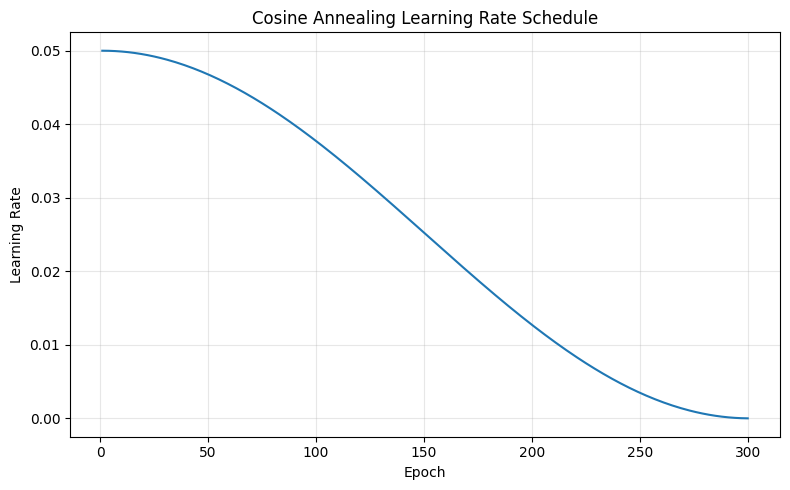

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

INITIAL_LR = 0.05
NUM_EPOCHS = 300
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0

# 使用一个临时参数验证调度器，不训练真实模型
dummy_parameter = torch.nn.Parameter(torch.zeros(1))

dummy_optimizer = torch.optim.SGD(
    [dummy_parameter],
    lr=INITIAL_LR,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    dummy_optimizer,
    T_max=NUM_EPOCHS,
    eta_min=0.0,
)

learning_rates = []

for epoch in range(NUM_EPOCHS):
    learning_rates.append(dummy_optimizer.param_groups[0]["lr"])

    # 模拟一次优化器更新，然后推进调度器
    dummy_optimizer.step()
    scheduler.step()

print("=" * 60)
print("Cosine Annealing verification")
print("=" * 60)

print(f"Epoch 1 LR:   {learning_rates[0]:.8f}")
print(f"Epoch 50 LR:  {learning_rates[49]:.8f}")
print(f"Epoch 100 LR: {learning_rates[99]:.8f}")
print(f"Epoch 150 LR: {learning_rates[149]:.8f}")
print(f"Epoch 200 LR: {learning_rates[199]:.8f}")
print(f"Epoch 250 LR: {learning_rates[249]:.8f}")
print(f"Epoch 300 LR: {learning_rates[299]:.8f}")

print("\nInitial LR correct:",
      np.isclose(learning_rates[0], INITIAL_LR))
print("Learning rate decreases:",
      learning_rates[0] > learning_rates[149] > learning_rates[299])
print("Final scheduled LR reaches zero:",
      np.isclose(learning_rates[-1], 0.0))

plt.figure(figsize=(8, 5))
plt.plot(range(1, NUM_EPOCHS + 1), learning_rates)
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Cosine Annealing Learning Rate Schedule")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# 检查第 300 轮 scheduler.step() 执行后的最终学习率
final_lr = dummy_optimizer.param_groups[0]["lr"]

print("=" * 50)
print("Cosine Annealing final verification")
print("=" * 50)
print(f"LR used at the beginning of Epoch 300: {learning_rates[-1]:.10f}")
print(f"LR after the final scheduler.step():   {final_lr:.10f}")
print(f"Final scheduled LR reaches zero: {np.isclose(final_lr, 0.0)}")

Cosine Annealing final verification
LR used at the beginning of Epoch 300: 0.0000013708
LR after the final scheduler.step():   0.0000000000
Final scheduled LR reaches zero: True


In [ ]:
import os
import torch
from pathlib import Path

# 确认保存目录
for directory in [
    LOCAL_CHECKPOINT_DIR,
    DRIVE_CHECKPOINT_DIR,
    LOCAL_LOG_DIR,
    DRIVE_LOG_DIR,
    LOCAL_FIGURE_DIR,
    DRIVE_FIGURE_DIR,
    LOCAL_RESULT_DIR,
    DRIVE_RESULT_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

# 定义可靠的检查点保存函数
def save_checkpoint(model, optimizer, scheduler, epoch, experiment_name):
    checkpoint = {
        "experiment": experiment_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": (
            scheduler.state_dict() if scheduler is not None else None
        ),
    }

    filename = f"{experiment_name}_latest.pth"

    # 先保存到本地临时文件，再替换正式文件
    local_path = LOCAL_CHECKPOINT_DIR / filename
    local_temp_path = LOCAL_CHECKPOINT_DIR / f"{filename}.tmp"

    torch.save(checkpoint, local_temp_path)
    os.replace(local_temp_path, local_path)

    # 同步到 Google Drive
    drive_path = DRIVE_CHECKPOINT_DIR / filename
    drive_temp_path = DRIVE_CHECKPOINT_DIR / f"{filename}.tmp"

    torch.save(checkpoint, drive_temp_path)
    os.replace(drive_temp_path, drive_path)

    return local_path, drive_path


# 使用临时测试文件验证保存和读取功能
test_path = DRIVE_CHECKPOINT_DIR / "_checkpoint_test.pt"
test_temp_path = DRIVE_CHECKPOINT_DIR / "_checkpoint_test.pt.tmp"

torch.save({"test": "checkpoint_save_ok", "epoch": 1}, test_temp_path)
os.replace(test_temp_path, test_path)

test_data = torch.load(
    test_path,
    map_location="cpu",
    weights_only=True
)

print("=" * 50)
print("Checkpoint save verification")
print("=" * 50)
print("Local checkpoint directory exists:",
      LOCAL_CHECKPOINT_DIR.exists())
print("Google Drive checkpoint directory exists:",
      DRIVE_CHECKPOINT_DIR.exists())
print("Test checkpoint saved and loaded:",
      test_data["test"] == "checkpoint_save_ok")
print("Test data:", test_data)

# 删除临时测试文件，不影响正式实验数据
test_path.unlink(missing_ok=True)
print("Temporary test file cleaned up.")

Checkpoint save verification
Local checkpoint directory exists: True
Google Drive checkpoint directory exists: True
Test checkpoint saved and loaded: True
Test data: {'test': 'checkpoint_save_ok', 'epoch': 1}
Temporary test file cleaned up.


In [ ]:
import csv
import os
import shutil
from pathlib import Path

# 每轮训练需要保存的指标
METRIC_COLUMNS = [
    "experiment",
    "epoch",
    "learning_rate",
    "weight_decay",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "elapsed_seconds",
]

METRICS_PATH = LOCAL_LOG_DIR / "epoch_metrics.csv"
DRIVE_METRICS_PATH = DRIVE_LOG_DIR / "epoch_metrics.csv"


def save_metric_record(record):
    """保存单轮指标，并同步完整日志到 Google Drive。"""

    METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)
    DRIVE_METRICS_PATH.parent.mkdir(parents=True, exist_ok=True)

    write_header = not METRICS_PATH.exists()

    with open(METRICS_PATH, "a", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=METRIC_COLUMNS)

        if write_header:
            writer.writeheader()

        writer.writerow(record)
        f.flush()
        os.fsync(f.fileno())

    # 同步至 Google Drive
    shutil.copy2(METRICS_PATH, DRIVE_METRICS_PATH)


# 使用独立的临时 CSV 文件测试，避免污染正式实验日志
test_local_path = LOCAL_LOG_DIR / "_metrics_test.csv"
test_drive_path = DRIVE_LOG_DIR / "_metrics_test.csv"

test_record = {
    "experiment": "logging_test",
    "epoch": 1,
    "learning_rate": 0.05,
    "weight_decay": 0.0,
    "train_loss": 4.5,
    "train_accuracy": 0.02,
    "val_loss": 4.6,
    "val_accuracy": 0.01,
    "elapsed_seconds": 10.0,
}

try:
    with open(test_local_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=METRIC_COLUMNS)
        writer.writeheader()
        writer.writerow(test_record)

    shutil.copy2(test_local_path, test_drive_path)

    # 分别读取本地与 Google Drive 中的测试记录
    with open(test_local_path, newline="", encoding="utf-8") as f:
        local_rows = list(csv.DictReader(f))

    with open(test_drive_path, newline="", encoding="utf-8") as f:
        drive_rows = list(csv.DictReader(f))

    print("=" * 50)
    print("Training metrics save verification")
    print("=" * 50)
    print("Local CSV saved correctly:", len(local_rows) == 1)
    print("Google Drive CSV saved correctly:", len(drive_rows) == 1)
    print("Metric columns correct:",
          list(local_rows[0].keys()) == METRIC_COLUMNS)
    print("Test record:", drive_rows[0])

finally:
    test_local_path.unlink(missing_ok=True)
    test_drive_path.unlink(missing_ok=True)

print("Temporary test files cleaned up.")

Training metrics save verification
Local CSV saved correctly: True
Google Drive CSV saved correctly: True
Metric columns correct: True
Test record: {'experiment': 'logging_test', 'epoch': '1', 'learning_rate': '0.05', 'weight_decay': '0.0', 'train_loss': '4.5', 'train_accuracy': '0.02', 'val_loss': '4.6', 'val_accuracy': '0.01', 'elapsed_seconds': '10.0'}
Temporary test files cleaned up.


In [ ]:
import inspect

print("=" * 60)
print("Training function verification")
print("=" * 60)

# 1. 检查训练函数
print("\n[1] train_one_epoch")
print(inspect.signature(train_one_epoch))

# 2. 检查验证函数
print("\n[2] evaluate")
print(inspect.signature(evaluate))

# 3. 检查逐轮日志保存函数
print("\n[3] save_metric_record")
print(inspect.signature(save_metric_record))

# 4. 检查检查点保存函数
print("\n[4] save_checkpoint")
print(inspect.signature(save_checkpoint))

# 5. 检查关键对象
print("\n[5] Environment")
print("Device:", device)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Initial learning rate:", INITIAL_LR)
print("Momentum:", MOMENTUM)
print("Weight decay:", WEIGHT_DECAY)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# 6. 检查正式日志是否已有记录
if METRICS_PATH.exists():
    import pandas as pd
    existing_metrics = pd.read_csv(METRICS_PATH)
    print("\nExisting local metric records:", len(existing_metrics))
else:
    print("\nExisting local metric records: 0")

if DRIVE_METRICS_PATH.exists():
    import pandas as pd
    drive_metrics = pd.read_csv(DRIVE_METRICS_PATH)
    print("Existing Drive metric records:", len(drive_metrics))
else:
    print("Existing Drive metric records: 0")

Training function verification

[1] train_one_epoch
(model, loader, criterion, optimizer, scaler)

[2] evaluate
(model, loader, criterion)

[3] save_metric_record
(record)

[4] save_checkpoint
(model, optimizer, scheduler, epoch, experiment_name)

[5] Environment
Device: cuda
Number of classes: 120
Batch size: 128
Initial learning rate: 0.05
Momentum: 0.9
Weight decay: 0.0
Train batches: 56
Validation batches: 12

Existing local metric records: 0
Existing Drive metric records: 0


#section 3

In [ ]:
import time
import shutil
import pandas as pd
import torch
import torch.nn as nn
from pathlib import Path

# 确保指标文件使用统一路径
METRICS_PATH = LOCAL_LOG_DIR / "epoch_metrics.csv"
DRIVE_METRICS_PATH = DRIVE_LOG_DIR / "epoch_metrics.csv"

# Section 3 的设置
SECTION3_EPOCHS = 15
SECTION3_LRS = [0.5, 0.05, 0.001]


def run_experiment(
    experiment_name,
    learning_rate,
    epochs,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
    mixup_alpha=0.2,
):
    """
    训练模型并逐轮保存指标和检查点。
    当前 Section 3 使用普通交叉熵，不启用 scheduler 或 Mixup。
    """

    set_seed(42)

    model = create_model().to(device)
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=MOMENTUM,
        weight_decay=weight_decay,
    )

    scheduler = None
    if use_cosine_scheduler:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=0.0,
        )

    scaler = create_scaler()
    best_val_accuracy = -1.0
    best_epoch = 0
    start_time = time.time()

    checkpoint_path = DRIVE_CHECKPOINT_DIR / f"{experiment_name}_latest.pth"
    best_checkpoint_path = DRIVE_CHECKPOINT_DIR / f"{experiment_name}_best.pth"

    print("=" * 70)
    print(f"Experiment: {experiment_name}")
    print(f"Learning rate: {learning_rate}")
    print(f"Epochs: {epochs}")
    print(f"Weight decay: {weight_decay}")
    print(f"Cosine scheduler: {use_cosine_scheduler}")
    print("=" * 70)

    for epoch in range(1, epochs + 1):
        epoch_start = time.time()
        current_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler
        )

        val_loss, val_accuracy = evaluate(
            model, val_loader, criterion
        )

        elapsed_seconds = time.time() - start_time

        record = {
            "experiment": experiment_name,
            "epoch": epoch,
            "learning_rate": current_lr,
            "weight_decay": weight_decay,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "elapsed_seconds": elapsed_seconds,
        }

        # 保存当前轮的指标，并同步至 Drive
        save_metric_record(record)

        # 每轮更新最新检查点
        save_checkpoint(
            model, optimizer, scheduler, epoch, experiment_name
        )

        # 保存验证集准确率最高的模型
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_checkpoint = {
                "experiment": experiment_name,
                "epoch": epoch,
                "best_val_accuracy": best_val_accuracy,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": (
                    scheduler.state_dict()
                    if scheduler is not None else None
                ),
            }

            torch.save(best_checkpoint, best_checkpoint_path)

            # 复制最佳模型到本地目录
            shutil.copy2(
                best_checkpoint_path,
                LOCAL_CHECKPOINT_DIR / f"{experiment_name}_best.pth",
            )

        print(
            f"[{experiment_name}] "
            f"Epoch {epoch:02d}/{epochs} | "
            f"LR {current_lr:.6f} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_accuracy:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_accuracy:.4f} | "
            f"Best Val Acc {best_val_accuracy:.4f} "
            f"(Epoch {best_epoch}) | "
            f"Epoch Time {time.time() - epoch_start:.1f}s"
        )

        # scheduler 在每轮训练和验证结束后更新
        if scheduler is not None:
            scheduler.step()

    print(f"\nExperiment {experiment_name} completed.")
    print(f"Best validation accuracy: {best_val_accuracy:.4f}")
    print(f"Best epoch: {best_epoch}")
    print(f"Total elapsed time: {(time.time() - start_time) / 60:.2f} minutes")

    # 返回汇总结果
    experiment_metrics = pd.read_csv(METRICS_PATH)
    experiment_metrics = experiment_metrics[
        experiment_metrics["experiment"] == experiment_name
    ]

    summary = {
        "experiment": experiment_name,
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "epochs": epochs,
        "best_epoch": best_epoch,
        "best_val_accuracy": best_val_accuracy,
        "final_train_loss": float(
            experiment_metrics.iloc[-1]["train_loss"]
        ),
        "final_train_accuracy": float(
            experiment_metrics.iloc[-1]["train_accuracy"]
        ),
        "final_val_loss": float(
            experiment_metrics.iloc[-1]["val_loss"]
        ),
        "final_val_accuracy": float(
            experiment_metrics.iloc[-1]["val_accuracy"]
        ),
        "elapsed_minutes": (time.time() - start_time) / 60,
    }

    return model, summary

In [ ]:
model_lr05, summary_lr05 = run_experiment(
    experiment_name="lr_0.5",
    learning_rate=0.5,
    epochs=15,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
)

print("\nExperiment Summary:")
for key, value in summary_lr05.items():
    print(f"{key}: {value}")

Experiment: lr_0.5
Learning rate: 0.5
Epochs: 15
Weight decay: 0.0
Cosine scheduler: False
[lr_0.5] Epoch 01/15 | LR 0.500000 | Train Loss 5.1499 | Train Acc 0.0101 | Val Loss 4.8279 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 35.8s
[lr_0.5] Epoch 02/15 | LR 0.500000 | Train Loss 4.8530 | Train Acc 0.0088 | Val Loss 4.8224 | Val Acc 0.0091 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 28.6s
[lr_0.5] Epoch 03/15 | LR 0.500000 | Train Loss 4.8180 | Train Acc 0.0096 | Val Loss 4.8009 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 31.3s
[lr_0.5] Epoch 04/15 | LR 0.500000 | Train Loss 4.8110 | Train Acc 0.0089 | Val Loss 4.8013 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 30.6s
[lr_0.5] Epoch 05/15 | LR 0.500000 | Train Loss 4.8206 | Train Acc 0.0112 | Val Loss 4.8362 | Val Acc 0.0091 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 31.1s
[lr_0.5] Epoch 06/15 | LR 0.500000 | Train Loss 4.8179 | Train Acc 0.0116 | Val Loss 4.7882 | Val Acc 0.0091 

In [ ]:
model_lr005, summary_lr005 = run_experiment(
    experiment_name="lr_0.05",
    learning_rate=0.05,
    epochs=15,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
)

print("\nExperiment Summary:")
for key, value in summary_lr005.items():
    print(f"{key}: {value}")

Experiment: lr_0.05
Learning rate: 0.05
Epochs: 15
Weight decay: 0.0
Cosine scheduler: False
[lr_0.05] Epoch 01/15 | LR 0.050000 | Train Loss 4.9541 | Train Acc 0.0095 | Val Loss 4.8638 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Epoch Time 31.7s
[lr_0.05] Epoch 02/15 | LR 0.050000 | Train Loss 4.8104 | Train Acc 0.0109 | Val Loss 4.8255 | Val Acc 0.0111 | Best Val Acc 0.0111 (Epoch 2) | Epoch Time 32.7s
[lr_0.05] Epoch 03/15 | LR 0.050000 | Train Loss 4.7833 | Train Acc 0.0113 | Val Loss 4.7813 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 3) | Epoch Time 39.8s
[lr_0.05] Epoch 04/15 | LR 0.050000 | Train Loss 4.7731 | Train Acc 0.0130 | Val Loss 4.7693 | Val Acc 0.0215 | Best Val Acc 0.0215 (Epoch 4) | Epoch Time 41.3s
[lr_0.05] Epoch 05/15 | LR 0.050000 | Train Loss 4.7460 | Train Acc 0.0147 | Val Loss 4.7529 | Val Acc 0.0157 | Best Val Acc 0.0215 (Epoch 4) | Epoch Time 34.1s
[lr_0.05] Epoch 06/15 | LR 0.050000 | Train Loss 4.7120 | Train Acc 0.0150 | Val Loss 4.7520 | Val Acc

In [ ]:
model_lr0001, summary_lr0001 = run_experiment(
    experiment_name="lr_0.001",
    learning_rate=0.001,
    epochs=15,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
)

print("\nExperiment Summary:")
for key, value in summary_lr0001.items():
    print(f"{key}: {value}")

Experiment: lr_0.001
Learning rate: 0.001
Epochs: 15
Weight decay: 0.0
Cosine scheduler: False
[lr_0.001] Epoch 01/15 | LR 0.001000 | Train Loss 4.8161 | Train Acc 0.0082 | Val Loss 4.7875 | Val Acc 0.0085 | Best Val Acc 0.0085 (Epoch 1) | Epoch Time 28.8s
[lr_0.001] Epoch 02/15 | LR 0.001000 | Train Loss 4.8019 | Train Acc 0.0080 | Val Loss 4.7881 | Val Acc 0.0065 | Best Val Acc 0.0085 (Epoch 1) | Epoch Time 28.1s
[lr_0.001] Epoch 03/15 | LR 0.001000 | Train Loss 4.8012 | Train Acc 0.0098 | Val Loss 4.8429 | Val Acc 0.0144 | Best Val Acc 0.0144 (Epoch 3) | Epoch Time 35.7s
[lr_0.001] Epoch 04/15 | LR 0.001000 | Train Loss 4.7955 | Train Acc 0.0099 | Val Loss 4.8128 | Val Acc 0.0117 | Best Val Acc 0.0144 (Epoch 3) | Epoch Time 34.4s
[lr_0.001] Epoch 05/15 | LR 0.001000 | Train Loss 4.7953 | Train Acc 0.0120 | Val Loss 4.8144 | Val Acc 0.0130 | Best Val Acc 0.0144 (Epoch 3) | Epoch Time 31.5s
[lr_0.001] Epoch 06/15 | LR 0.001000 | Train Loss 4.7946 | Train Acc 0.0103 | Val Loss 4.7926 |

Section 3 record counts:
lr_0.5: 15 epochs
lr_0.05: 15 epochs
lr_0.001: 15 epochs


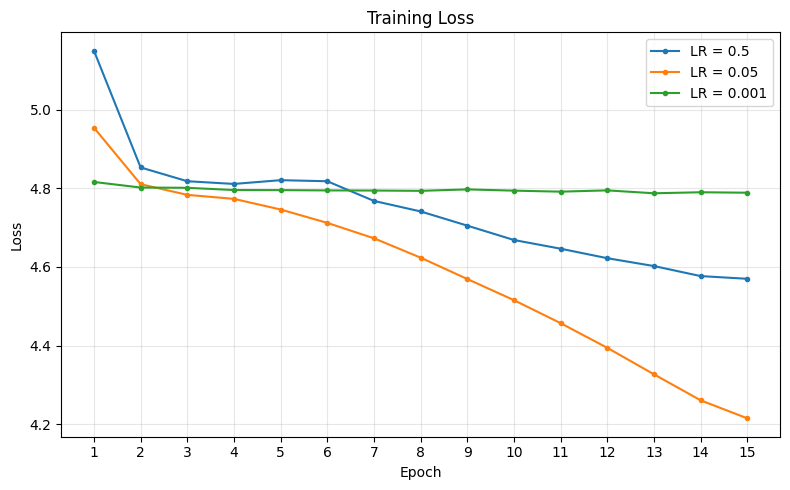

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section3_training_loss.png


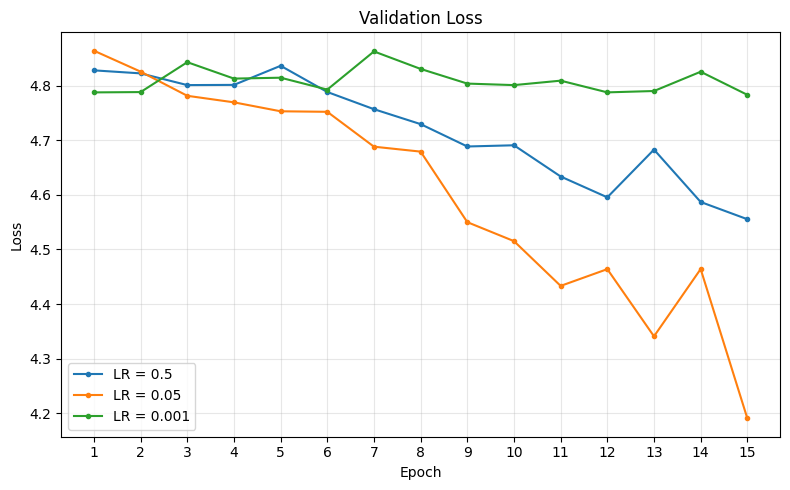

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section3_validation_loss.png


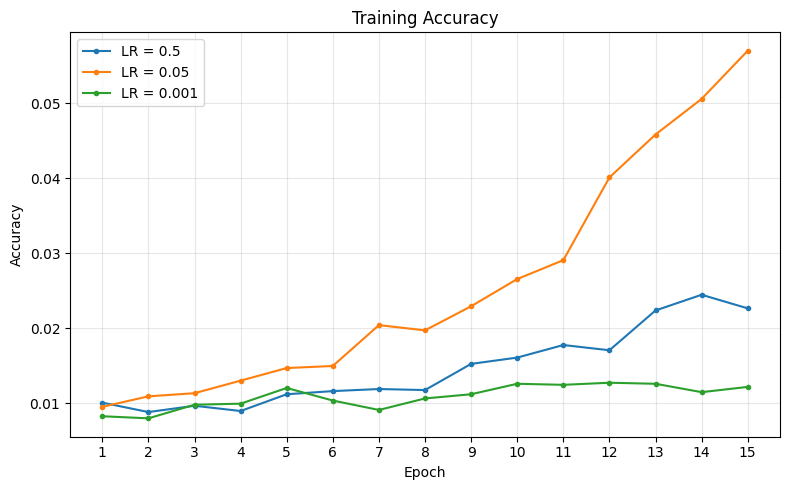

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section3_training_accuracy.png


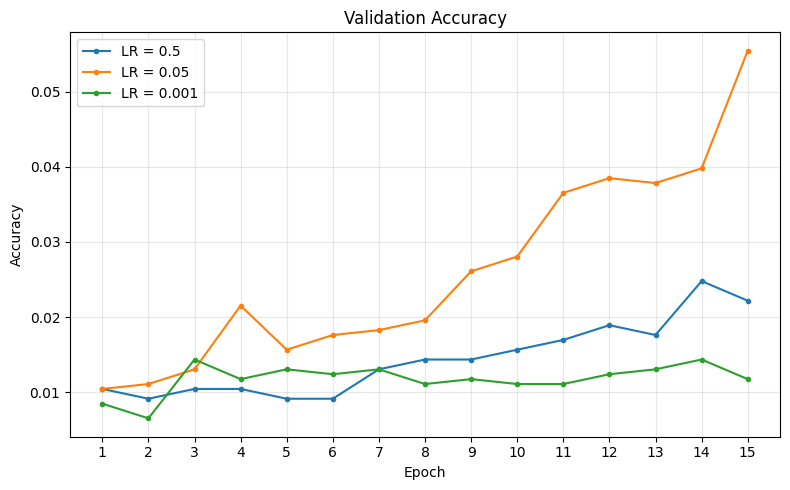

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section3_validation_accuracy.png

All four Section 3 figures saved to Google Drive.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import shutil

# 读取完整训练日志
metrics = pd.read_csv(METRICS_PATH)

# 仅提取 Section 3 的三个实验
section3_names = ["lr_0.5", "lr_0.05", "lr_0.001"]
section3 = metrics[metrics["experiment"].isin(section3_names)].copy()

# 检查实验记录是否完整
expected_counts = {
    name: 15 for name in section3_names
}
actual_counts = section3.groupby("experiment").size().to_dict()

print("Section 3 record counts:")
for name in section3_names:
    print(f"{name}: {actual_counts.get(name, 0)} epochs")

assert all(actual_counts.get(name, 0) == 15 for name in section3_names), (
    "实验记录不完整，请先检查 epoch_metrics.csv。"
)

# 绘图
plot_configs = [
    ("train_loss", "Training Loss", "Loss", "section3_training_loss.png"),
    ("val_loss", "Validation Loss", "Loss", "section3_validation_loss.png"),
    ("train_accuracy", "Training Accuracy", "Accuracy", "section3_training_accuracy.png"),
    ("val_accuracy", "Validation Accuracy", "Accuracy", "section3_validation_accuracy.png"),
]

colors = {
    "lr_0.5": "tab:blue",
    "lr_0.05": "tab:orange",
    "lr_0.001": "tab:green",
}

for metric, title, ylabel, filename in plot_configs:
    plt.figure(figsize=(8, 5))

    for name in section3_names:
        subset = section3[section3["experiment"] == name].sort_values("epoch")

        plt.plot(
            subset["epoch"],
            subset[metric],
            label=f"LR = {name.replace('lr_', '')}",
            color=colors[name],
            marker="o",
            markersize=3,
        )

    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.xticks(range(1, 16))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    local_path = LOCAL_FIGURE_DIR / filename
    drive_path = DRIVE_FIGURE_DIR / filename

    plt.savefig(local_path, dpi=300, bbox_inches="tight")
    shutil.copy2(local_path, drive_path)

    plt.show()
    plt.close()

    print("Saved:", drive_path)

print("\nAll four Section 3 figures saved to Google Drive.")

In [ ]:
import pandas as pd
import shutil

# 读取全部训练记录
metrics = pd.read_csv(METRICS_PATH)

section3_names = ["lr_0.5", "lr_0.05", "lr_0.001"]
section3 = metrics[metrics["experiment"].isin(section3_names)].copy()

# 整理每个实验的最终指标与最佳验证集表现
summary_rows = []

for name in section3_names:
    exp = section3[section3["experiment"] == name].sort_values("epoch")

    best_idx = exp["val_accuracy"].idxmax()
    best_row = exp.loc[best_idx]
    final_row = exp.iloc[-1]

    summary_rows.append({
        "experiment": name,
        "learning_rate": float(final_row["learning_rate"]),
        "epochs": len(exp),
        "final_train_loss": float(final_row["train_loss"]),
        "final_train_accuracy": float(final_row["train_accuracy"]),
        "final_val_loss": float(final_row["val_loss"]),
        "final_val_accuracy": float(final_row["val_accuracy"]),
        "best_val_accuracy": float(best_row["val_accuracy"]),
        "best_epoch": int(best_row["epoch"]),
    })

summary_df = pd.DataFrame(summary_rows)

# 保存到本地和 Google Drive
local_summary_path = LOCAL_RESULT_DIR / "section3_summary.csv"
drive_summary_path = DRIVE_RESULT_DIR / "section3_summary.csv"

summary_df.to_csv(local_summary_path, index=False)
shutil.copy2(local_summary_path, drive_summary_path)

print(summary_df.to_string(index=False))
print("\nSaved to:", drive_summary_path)

experiment  learning_rate  epochs  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  best_val_accuracy  best_epoch
    lr_0.5          0.500      15          4.569790              0.022642        4.555280            0.022179           0.024788          14
   lr_0.05          0.050      15          4.214874              0.057023        4.190616            0.055447           0.055447          15
  lr_0.001          0.001      15          4.788718              0.012159        4.783069            0.011742           0.014351           3

Saved to: /content/drive/MyDrive/AI6103_Assignment/results/section3_summary.csv


In [ ]:
model_constant, summary_constant = run_experiment(
    experiment_name="section4_constant",
    learning_rate=0.05,
    epochs=300,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
)

print("\nSection 4 Constant LR Summary:")
for key, value in summary_constant.items():
    print(f"{key}: {value}")

Experiment: section4_constant
Learning rate: 0.05
Epochs: 300
Weight decay: 0.0
Cosine scheduler: False
[section4_constant] Epoch 01/300 | LR 0.050000 | Train Loss 4.9505 | Train Acc 0.0101 | Val Loss 4.8817 | Val Acc 0.0124 | Best Val Acc 0.0124 (Epoch 1) | Epoch Time 33.5s
[section4_constant] Epoch 02/300 | LR 0.050000 | Train Loss 4.8065 | Train Acc 0.0120 | Val Loss 4.7775 | Val Acc 0.0124 | Best Val Acc 0.0124 (Epoch 1) | Epoch Time 28.6s
[section4_constant] Epoch 03/300 | LR 0.050000 | Train Loss 4.7780 | Train Acc 0.0124 | Val Loss 4.7785 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 3) | Epoch Time 32.3s
[section4_constant] Epoch 04/300 | LR 0.050000 | Train Loss 4.7589 | Train Acc 0.0144 | Val Loss 4.7520 | Val Acc 0.0150 | Best Val Acc 0.0150 (Epoch 4) | Epoch Time 36.0s
[section4_constant] Epoch 05/300 | LR 0.050000 | Train Loss 4.7209 | Train Acc 0.0158 | Val Loss 4.7093 | Val Acc 0.0176 | Best Val Acc 0.0176 (Epoch 5) | Epoch Time 41.4s
[section4_constant] Epoch 06/300 | L

In [ ]:
model_cosine, summary_cosine = run_experiment(
    experiment_name="section4_cosine",
    learning_rate=0.05,
    epochs=300,
    weight_decay=0.0,
    use_cosine_scheduler=True,
    use_mixup=False,
)

print("\nSection 4 Cosine Annealing Summary:")
for key, value in summary_cosine.items():
    print(f"{key}: {value}")

Experiment: section4_cosine
Learning rate: 0.05
Epochs: 300
Weight decay: 0.0
Cosine scheduler: True
[section4_cosine] Epoch 01/300 | LR 0.050000 | Train Loss 4.9644 | Train Acc 0.0077 | Val Loss 5.4158 | Val Acc 0.0091 | Best Val Acc 0.0091 (Epoch 1) | Epoch Time 32.5s
[section4_cosine] Epoch 02/300 | LR 0.049999 | Train Loss 4.8064 | Train Acc 0.0119 | Val Loss 4.7852 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 2) | Epoch Time 37.5s
[section4_cosine] Epoch 03/300 | LR 0.049995 | Train Loss 4.7779 | Train Acc 0.0117 | Val Loss 4.7667 | Val Acc 0.0144 | Best Val Acc 0.0144 (Epoch 3) | Epoch Time 40.1s
[section4_cosine] Epoch 04/300 | LR 0.049988 | Train Loss 4.7510 | Train Acc 0.0150 | Val Loss 4.7136 | Val Acc 0.0189 | Best Val Acc 0.0189 (Epoch 4) | Epoch Time 35.9s
[section4_cosine] Epoch 05/300 | LR 0.049978 | Train Loss 4.6801 | Train Acc 0.0180 | Val Loss 4.6442 | Val Acc 0.0235 | Best Val Acc 0.0235 (Epoch 5) | Epoch Time 35.6s
[section4_cosine] Epoch 06/300 | LR 0.049966 | Tr

Epoch counts:
experiment
section4_constant    300
section4_cosine      300
Name: epoch, dtype: int64


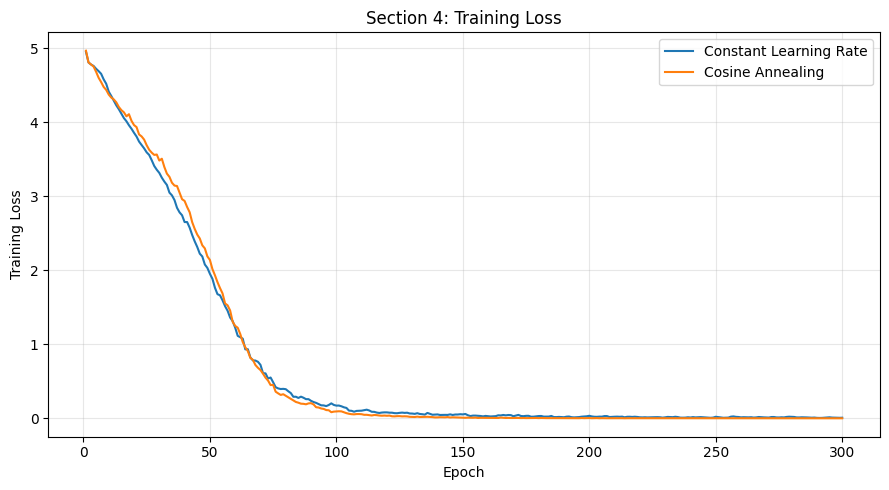

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section4_training_loss.png


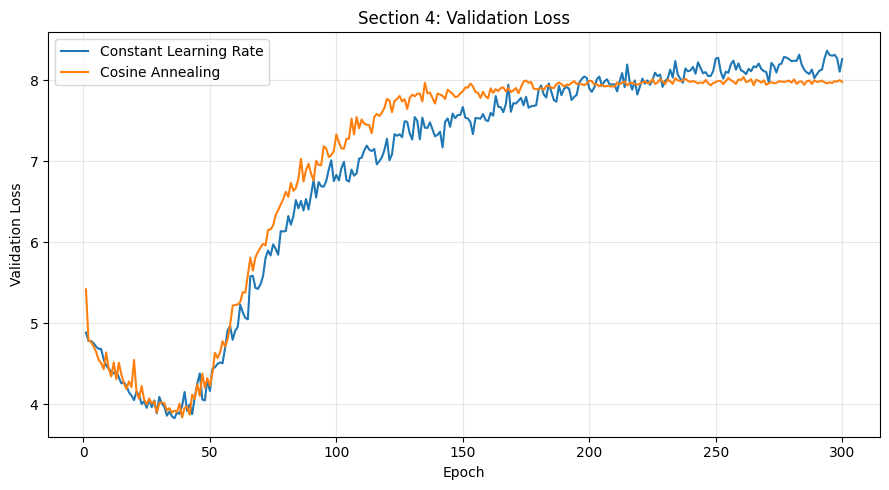

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section4_validation_loss.png


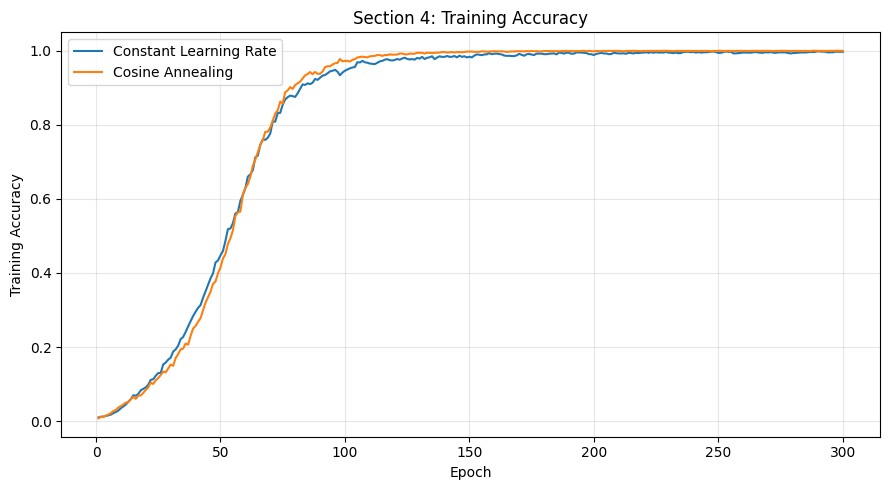

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section4_training_accuracy.png


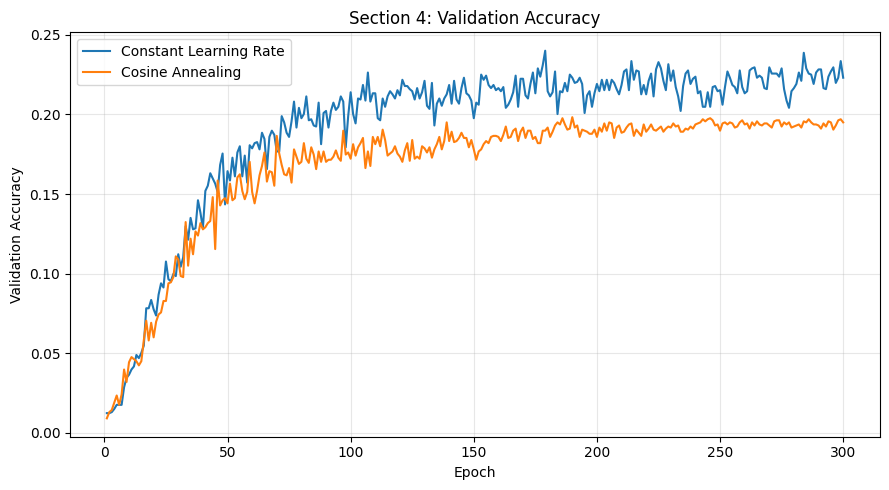

Saved: /content/drive/MyDrive/AI6103_Assignment/figures/section4_validation_accuracy.png

Section 4 figures generated.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load all recorded metrics
metrics_df = pd.read_csv(METRICS_PATH)

# Select Section 4 experiments only
section4_df = metrics_df[
    metrics_df["experiment"].isin(
        ["section4_constant", "section4_cosine"]
    )
].copy()

# Verify each experiment has 300 epochs
print("Epoch counts:")
print(section4_df.groupby("experiment")["epoch"].nunique())

# Create output directories
LOCAL_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

experiments = [
    ("section4_constant", "Constant Learning Rate"),
    ("section4_cosine", "Cosine Annealing"),
]

plots = [
    ("train_loss", "Training Loss", "section4_training_loss.png"),
    ("val_loss", "Validation Loss", "section4_validation_loss.png"),
    ("train_accuracy", "Training Accuracy", "section4_training_accuracy.png"),
    ("val_accuracy", "Validation Accuracy", "section4_validation_accuracy.png"),
]

for metric, title, filename in plots:
    plt.figure(figsize=(9, 5))

    for experiment_name, label in experiments:
        exp_df = section4_df[
            section4_df["experiment"] == experiment_name
        ].sort_values("epoch")

        plt.plot(
            exp_df["epoch"],
            exp_df[metric],
            label=label,
            linewidth=1.5,
        )

    plt.xlabel("Epoch")
    plt.ylabel(title)
    plt.title(f"Section 4: {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    local_path = LOCAL_FIGURE_DIR / filename
    drive_path = DRIVE_FIGURE_DIR / filename

    plt.savefig(local_path, dpi=300, bbox_inches="tight")
    plt.savefig(drive_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Saved: {drive_path}")

print("\nSection 4 figures generated.")

In [ ]:
import pandas as pd
import shutil

metrics_df = pd.read_csv(METRICS_PATH)

section4_names = [
    "section4_constant",
    "section4_cosine",
]

rows = []

for name in section4_names:
    exp_df = (
        metrics_df[metrics_df["experiment"] == name]
        .sort_values("epoch")
        .reset_index(drop=True)
    )

    if len(exp_df) != 300:
        raise ValueError(
            f"{name} has {len(exp_df)} epoch records; expected 300."
        )

    final_row = exp_df.iloc[-1]
    best_row = exp_df.loc[exp_df["val_accuracy"].idxmax()]

    rows.append({
        "experiment": name,
        "learning_rate": 0.05,
        "weight_decay": 0.0,
        "epochs": len(exp_df),
        "best_epoch": int(best_row["epoch"]),
        "best_val_accuracy": best_row["val_accuracy"],
        "final_train_loss": final_row["train_loss"],
        "final_train_accuracy": final_row["train_accuracy"],
        "final_val_loss": final_row["val_loss"],
        "final_val_accuracy": final_row["val_accuracy"],
        "elapsed_minutes": final_row["elapsed_seconds"] / 60,
    })

section4_summary = pd.DataFrame(rows)

print(section4_summary.to_string(index=False))

local_path = LOCAL_RESULT_DIR / "section4_summary.csv"
drive_path = DRIVE_RESULT_DIR / "section4_summary.csv"

section4_summary.to_csv(local_path, index=False)
shutil.copy2(local_path, drive_path)

print(f"\nSaved to: {drive_path}")

       experiment  learning_rate  weight_decay  epochs  best_epoch  best_val_accuracy  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  elapsed_minutes
section4_constant           0.05           0.0     300         179           0.240052          0.010028              0.997065        8.260446            0.223092       161.522792
  section4_cosine           0.05           0.0     300         190           0.198304          0.002205              0.999581        7.977432            0.195042       166.000132

Saved to: /content/drive/MyDrive/AI6103_Assignment/results/section4_summary.csv


In [ ]:
from pathlib import Path
import shutil
import hashlib
import pandas as pd
import os
import json
from datetime import datetime

# ==========================================
# 1. Define project paths
# ==========================================
LOCAL_PROJECT = Path("/content/AI6103_Assignment")
DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")

ARTIFACT_DIRS = [
    "checkpoints",
    "logs",
    "figures",
    "results",
    "config",
]

LOCAL_DATASET_ARCHIVE = (
    DRIVE_PROJECT / "dataset" / "dog_breed_dataset.zip"
)

LOCAL_ARCHIVE_COPY = (
    LOCAL_PROJECT / "dataset" / "dog_breed_dataset.zip"
)

assert LOCAL_PROJECT.exists(), (
    f"Local project not found: {LOCAL_PROJECT}"
)
assert DRIVE_PROJECT.exists(), (
    f"Google Drive project not found: {DRIVE_PROJECT}"
)
assert LOCAL_DATASET_ARCHIVE.exists(), (
    f"Dataset archive not found: {LOCAL_DATASET_ARCHIVE}"
)

# ==========================================
# 2. Copy local artifacts to Google Drive
#    Do not delete any existing Drive files
# ==========================================
for folder_name in ARTIFACT_DIRS:
    local_folder = LOCAL_PROJECT / folder_name
    drive_folder = DRIVE_PROJECT / folder_name

    drive_folder.mkdir(parents=True, exist_ok=True)

    if not local_folder.exists():
        print(f"WARNING: Local folder missing: {local_folder}")
        continue

    copied_count = 0

    for src in local_folder.rglob("*"):
        if not src.is_file():
            continue

        relative_path = src.relative_to(local_folder)
        dst = drive_folder / relative_path

        dst.parent.mkdir(parents=True, exist_ok=True)

        # Copy current local artifact to Drive.
        # Existing Drive-only files are not deleted.
        shutil.copy2(src, dst)
        copied_count += 1

    print(
        f"{folder_name}: synchronized "
        f"{copied_count} local files to Google Drive"
    )

# ==========================================
# 3. Keep a local copy of the original dataset ZIP
# ==========================================
LOCAL_ARCHIVE_COPY.parent.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    LOCAL_DATASET_ARCHIVE,
    LOCAL_ARCHIVE_COPY,
)

assert LOCAL_ARCHIVE_COPY.exists()
assert (
    LOCAL_ARCHIVE_COPY.stat().st_size
    == LOCAL_DATASET_ARCHIVE.stat().st_size
)

print("\nDataset archive copied to local project.")

# ==========================================
# 4. SHA-256 utility
# ==========================================
def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

# ==========================================
# 5. Build a manifest of project artifacts
# ==========================================
manifest_rows = []

for folder_name in ARTIFACT_DIRS:
    local_folder = LOCAL_PROJECT / folder_name

    if not local_folder.exists():
        continue

    for path in sorted(local_folder.rglob("*")):
        if not path.is_file():
            continue

        relative_path = path.relative_to(LOCAL_PROJECT)
        drive_path = DRIVE_PROJECT / relative_path

        local_hash = sha256_file(path)

        drive_exists = drive_path.exists()
        drive_hash = (
            sha256_file(drive_path)
            if drive_exists
            else None
        )

        manifest_rows.append({
            "relative_path": str(relative_path),
            "local_exists": True,
            "drive_exists": drive_exists,
            "local_size_bytes": path.stat().st_size,
            "drive_size_bytes": (
                drive_path.stat().st_size
                if drive_exists else None
            ),
            "local_sha256": local_hash,
            "drive_sha256": drive_hash,
            "verified": (
                drive_exists and local_hash == drive_hash
            ),
        })

# Also record the original dataset ZIP.
for path in [LOCAL_ARCHIVE_COPY, LOCAL_DATASET_ARCHIVE]:
    if path.exists():
        manifest_rows.append({
            "relative_path": str(path),
            "local_exists": path == LOCAL_ARCHIVE_COPY,
            "drive_exists": path == LOCAL_DATASET_ARCHIVE,
            "local_size_bytes": (
                LOCAL_ARCHIVE_COPY.stat().st_size
                if LOCAL_ARCHIVE_COPY.exists() else None
            ),
            "drive_size_bytes": (
                LOCAL_DATASET_ARCHIVE.stat().st_size
                if LOCAL_DATASET_ARCHIVE.exists() else None
            ),
            "local_sha256": (
                sha256_file(LOCAL_ARCHIVE_COPY)
                if LOCAL_ARCHIVE_COPY.exists() else None
            ),
            "drive_sha256": (
                sha256_file(LOCAL_DATASET_ARCHIVE)
                if LOCAL_DATASET_ARCHIVE.exists() else None
            ),
            "verified": (
                LOCAL_ARCHIVE_COPY.exists()
                and LOCAL_DATASET_ARCHIVE.exists()
                and sha256_file(LOCAL_ARCHIVE_COPY)
                    == sha256_file(LOCAL_DATASET_ARCHIVE)
            ),
        })

manifest_df = pd.DataFrame(manifest_rows)

# ==========================================
# 6. Save manifest to both locations
# ==========================================
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

local_manifest = (
    LOCAL_PROJECT / "results" / "backup_manifest.csv"
)
drive_manifest = (
    DRIVE_PROJECT / "results" / "backup_manifest.csv"
)

local_manifest.parent.mkdir(parents=True, exist_ok=True)
drive_manifest.parent.mkdir(parents=True, exist_ok=True)

manifest_df.to_csv(local_manifest, index=False)
shutil.copy2(local_manifest, drive_manifest)

# ==========================================
# 7. Check required result files
# ==========================================
required_files = [
    "logs/epoch_metrics.csv",
    "results/section3_summary.csv",
    "results/section4_summary.csv",
    "figures/section3_training_loss.png",
    "figures/section3_validation_loss.png",
    "figures/section3_training_accuracy.png",
    "figures/section3_validation_accuracy.png",
    "figures/section4_training_loss.png",
    "figures/section4_validation_loss.png",
    "figures/section4_training_accuracy.png",
    "figures/section4_validation_accuracy.png",
]

print("\nRequired file check:")

for relative_path in required_files:
    local_path = LOCAL_PROJECT / relative_path
    drive_path = DRIVE_PROJECT / relative_path

    ok = (
        local_path.exists()
        and drive_path.exists()
        and sha256_file(local_path) == sha256_file(drive_path)
    )

    print(f"{'PASS' if ok else 'FAIL'}  {relative_path}")

# ==========================================
# 8. Check checkpoints
# ==========================================
print("\nCheckpoint files:")

for folder in [
    LOCAL_PROJECT / "checkpoints",
    DRIVE_PROJECT / "checkpoints",
]:
    print(f"\n{folder}")

    if not folder.exists():
        print("  MISSING DIRECTORY")
        continue

    files = sorted(
        p for p in folder.glob("*.pth")
        if p.is_file()
    )

    for p in files:
        print(
            f"  {p.name}: "
            f"{p.stat().st_size / (1024**2):.2f} MB"
        )

# ==========================================
# 9. Final verification summary
# ==========================================
print("\nManifest saved:")
print(f"Local: {local_manifest}")
print(f"Drive: {drive_manifest}")

artifact_rows = manifest_df[
    manifest_df["relative_path"].str.startswith(
        tuple(f"{folder}/" for folder in ARTIFACT_DIRS)
    )
]

print("\nArtifact verification:")
print(f"Total artifact files: {len(artifact_rows)}")
print(f"Verified identical: {artifact_rows['verified'].sum()}")
print(f"Failed verification: {(~artifact_rows['verified']).sum()}")

print("\nBackup check finished.")

checkpoints: synchronized 10 local files to Google Drive
logs: synchronized 1 local files to Google Drive
figures: synchronized 8 local files to Google Drive
results: synchronized 2 local files to Google Drive

Dataset archive copied to local project.

Required file check:
PASS  logs/epoch_metrics.csv
PASS  results/section3_summary.csv
PASS  results/section4_summary.csv
PASS  figures/section3_training_loss.png
PASS  figures/section3_validation_loss.png
PASS  figures/section3_training_accuracy.png
PASS  figures/section3_validation_accuracy.png
PASS  figures/section4_training_loss.png
PASS  figures/section4_validation_loss.png
PASS  figures/section4_training_accuracy.png
PASS  figures/section4_validation_accuracy.png

Checkpoint files:

/content/AI6103_Assignment/checkpoints
  lr_0.001_best.pth: 156.11 MB
  lr_0.001_latest.pth: 156.12 MB
  lr_0.05_best.pth: 156.11 MB
  lr_0.05_latest.pth: 156.12 MB
  lr_0.5_best.pth: 156.11 MB
  lr_0.5_latest.pth: 156.11 MB
  section4_constant_best.pth: 

In [ ]:
from pathlib import Path
import shutil

LOCAL_PROJECT = Path("/content/AI6103_Assignment")
DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")

local_config = LOCAL_PROJECT / "config"
drive_config = DRIVE_PROJECT / "config"

# Ensure both directories exist
local_config.mkdir(parents=True, exist_ok=True)
drive_config.mkdir(parents=True, exist_ok=True)

# Copy Drive config files to local if they exist
drive_files = [p for p in drive_config.rglob("*") if p.is_file()]

for src in drive_files:
    relative_path = src.relative_to(drive_config)
    dst = local_config / relative_path

    dst.parent.mkdir(parents=True, exist_ok=True)

    # Copy only when the local copy is missing or differs in size
    if not dst.exists() or dst.stat().st_size != src.stat().st_size:
        shutil.copy2(src, dst)

# List files in both locations
print("Google Drive config files:")
for p in sorted(drive_config.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(drive_config)} ({p.stat().st_size} bytes)")

print("\nLocal config files:")
for p in sorted(local_config.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(local_config)} ({p.stat().st_size} bytes)")

print("\nConfig directory check complete.")

Google Drive config files:
  class_mapping.csv (2099 bytes)
  experiment_config.json (3769 bytes)

Local config files:
  class_mapping.csv (2099 bytes)
  experiment_config.json (3769 bytes)

Config directory check complete.


#新一日恢复

In [ ]:
from pathlib import Path
import shutil
import pandas as pd

# Project paths
DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")
LOCAL_PROJECT = Path("/content/AI6103_Assignment")

assert DRIVE_PROJECT.exists(), (
    f"Google Drive project not found: {DRIVE_PROJECT}"
)

LOCAL_PROJECT.mkdir(parents=True, exist_ok=True)

# Restore project folders from Google Drive
folders = [
    "checkpoints",
    "logs",
    "figures",
    "results",
    "config",
]

for folder_name in folders:
    drive_folder = DRIVE_PROJECT / folder_name
    local_folder = LOCAL_PROJECT / folder_name

    local_folder.mkdir(parents=True, exist_ok=True)

    if not drive_folder.exists():
        print(f"WARNING: Drive folder missing: {drive_folder}")
        continue

    restored = 0

    for src in drive_folder.rglob("*"):
        if not src.is_file():
            continue

        relative_path = src.relative_to(drive_folder)
        dst = local_folder / relative_path

        dst.parent.mkdir(parents=True, exist_ok=True)

        # Restore files from Drive; never delete Drive files
        if (
            not dst.exists()
            or dst.stat().st_size != src.stat().st_size
        ):
            shutil.copy2(src, dst)
            restored += 1

    print(f"{folder_name}: restored {restored} files")

# Check required files
required_files = [
    "logs/epoch_metrics.csv",
    "results/section3_summary.csv",
    "results/section4_summary.csv",
    "results/backup_manifest.csv",
    "figures/section3_training_loss.png",
    "figures/section3_validation_loss.png",
    "figures/section3_training_accuracy.png",
    "figures/section3_validation_accuracy.png",
    "figures/section4_training_loss.png",
    "figures/section4_validation_loss.png",
    "figures/section4_training_accuracy.png",
    "figures/section4_validation_accuracy.png",
]

print("\nRequired file check:")

for relative_path in required_files:
    path = LOCAL_PROJECT / relative_path
    print(f"{'PASS' if path.exists() else 'FAIL'}  {relative_path}")

# Check checkpoints
print("\nSection 3 and Section 4 checkpoints:")

for name in [
    "lr_0.5_best.pth",
    "lr_0.5_latest.pth",
    "lr_0.05_best.pth",
    "lr_0.05_latest.pth",
    "lr_0.001_best.pth",
    "lr_0.001_latest.pth",
    "section4_constant_best.pth",
    "section4_constant_latest.pth",
    "section4_cosine_best.pth",
    "section4_cosine_latest.pth",
]:
    path = LOCAL_PROJECT / "checkpoints" / name

    if path.exists():
        print(f"PASS  {name} ({path.stat().st_size / 1024**2:.2f} MB)")
    else:
        print(f"FAIL  {name}")

# Inspect experiment log
metrics_path = LOCAL_PROJECT / "logs" / "epoch_metrics.csv"

if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path)

    print("\nExperiment log record counts:")
    print(metrics_df.groupby("experiment")["epoch"].agg(["count", "min", "max"]))

    print("\nTotal metric records:", len(metrics_df))
else:
    print("\nERROR: epoch_metrics.csv is missing.")

# Check dataset archive
archive = DRIVE_PROJECT / "dataset" / "dog_breed_dataset.zip"
print(
    "\nDataset archive:",
    "PASS" if archive.exists() else "FAIL",
    str(archive),
)

print("\nRecovery check complete.")

checkpoints: restored 10 files
logs: restored 2 files
figures: restored 8 files
results: restored 3 files
config: restored 2 files

Required file check:
PASS  logs/epoch_metrics.csv
PASS  results/section3_summary.csv
PASS  results/section4_summary.csv
PASS  results/backup_manifest.csv
PASS  figures/section3_training_loss.png
PASS  figures/section3_validation_loss.png
PASS  figures/section3_training_accuracy.png
PASS  figures/section3_validation_accuracy.png
PASS  figures/section4_training_loss.png
PASS  figures/section4_validation_loss.png
PASS  figures/section4_training_accuracy.png
PASS  figures/section4_validation_accuracy.png

Section 3 and Section 4 checkpoints:
PASS  lr_0.5_best.pth (156.11 MB)
PASS  lr_0.5_latest.pth (156.11 MB)
PASS  lr_0.05_best.pth (156.11 MB)
PASS  lr_0.05_latest.pth (156.12 MB)
PASS  lr_0.001_best.pth (156.11 MB)
PASS  lr_0.001_latest.pth (156.12 MB)
PASS  section4_constant_best.pth (156.12 MB)
PASS  section4_constant_latest.pth (156.13 MB)
PASS  section4_c

#恢复运行环境

In [1]:
# ============================================================
# AI6103 Dog Breed Classification
# Complete Environment Recovery
# ============================================================

import os
import sys
import csv
import json
import time
import math
import random
import shutil
import zipfile
import inspect
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from google.colab import drive


# ============================================================
# 1. Mount Google Drive
# ============================================================

print("=" * 70)
print("STEP 1: Mounting Google Drive")
print("=" * 70)

drive.mount("/content/drive")


# ============================================================
# 2. Define project paths
# ============================================================

print("\n" + "=" * 70)
print("STEP 2: Setting up project paths")
print("=" * 70)

LOCAL_PROJECT = Path("/content/AI6103_Assignment")

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/AI6103_Assignment"
)

DRIVE_DATASET_ZIP = (
    DRIVE_PROJECT / "dataset" / "dog_breed_dataset.zip"
)

LOCAL_DATASET_ZIP = (
    LOCAL_PROJECT / "dataset" / "dog_breed_dataset.zip"
)

LOCAL_DATASET_EXTRACTED = (
    LOCAL_PROJECT / "dataset" / "extracted"
)

DATA_DIR = LOCAL_DATASET_EXTRACTED / "data"

LOCAL_CHECKPOINT_DIR = LOCAL_PROJECT / "checkpoints"
LOCAL_LOG_DIR = LOCAL_PROJECT / "logs"
LOCAL_FIGURE_DIR = LOCAL_PROJECT / "figures"
LOCAL_RESULT_DIR = LOCAL_PROJECT / "results"
LOCAL_CONFIG_DIR = LOCAL_PROJECT / "config"

DRIVE_CHECKPOINT_DIR = DRIVE_PROJECT / "checkpoints"
DRIVE_LOG_DIR = DRIVE_PROJECT / "logs"
DRIVE_FIGURE_DIR = DRIVE_PROJECT / "figures"
DRIVE_RESULT_DIR = DRIVE_PROJECT / "results"
DRIVE_CONFIG_DIR = DRIVE_PROJECT / "config"

METRICS_PATH = LOCAL_LOG_DIR / "epoch_metrics.csv"
DRIVE_METRICS_PATH = DRIVE_LOG_DIR / "epoch_metrics.csv"

# Create required directories.
for directory in [
    LOCAL_PROJECT,
    LOCAL_CHECKPOINT_DIR,
    LOCAL_LOG_DIR,
    LOCAL_FIGURE_DIR,
    LOCAL_RESULT_DIR,
    LOCAL_CONFIG_DIR,
    DRIVE_CHECKPOINT_DIR,
    DRIVE_LOG_DIR,
    DRIVE_FIGURE_DIR,
    DRIVE_RESULT_DIR,
    DRIVE_CONFIG_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Local project:", LOCAL_PROJECT)
print("Drive project:", DRIVE_PROJECT)
print("Dataset directory:", DATA_DIR)


# ============================================================
# 3. Restore saved artifacts from Google Drive
# ============================================================

print("\n" + "=" * 70)
print("STEP 3: Restoring saved experiment artifacts")
print("=" * 70)

# Restore these folders from Drive to the local Colab environment.
# Existing files with the same names are replaced by their Drive copies.
# The Drive originals are not deleted.

FOLDERS_TO_RESTORE = [
    "checkpoints",
    "logs",
    "figures",
    "results",
    "config",
]

for folder_name in FOLDERS_TO_RESTORE:

    source_dir = DRIVE_PROJECT / folder_name
    destination_dir = LOCAL_PROJECT / folder_name

    destination_dir.mkdir(parents=True, exist_ok=True)

    if source_dir.exists():

        restored_count = 0

        for source_file in source_dir.rglob("*"):

            if not source_file.is_file():
                continue

            relative_path = source_file.relative_to(source_dir)
            destination_file = destination_dir / relative_path

            destination_file.parent.mkdir(
                parents=True,
                exist_ok=True
            )

            shutil.copy2(source_file, destination_file)
            restored_count += 1

        print(
            f"{folder_name}: restored {restored_count} files"
        )

    else:
        print(
            f"{folder_name}: no corresponding Drive folder found"
        )


# ============================================================
# 4. Restore dataset archive and extract it if necessary
# ============================================================

print("\n" + "=" * 70)
print("STEP 4: Checking dataset")
print("=" * 70)

LOCAL_DATASET_ZIP.parent.mkdir(parents=True, exist_ok=True)

if not LOCAL_DATASET_ZIP.exists():

    if not DRIVE_DATASET_ZIP.exists():
        raise FileNotFoundError(
            "Dataset archive not found.\n"
            f"Expected Drive archive: {DRIVE_DATASET_ZIP}"
        )

    print("Copying dataset archive from Google Drive...")

    shutil.copy2(
        DRIVE_DATASET_ZIP,
        LOCAL_DATASET_ZIP
    )

    print("Dataset archive copied.")

else:
    print("Local dataset archive already exists.")

print(
    "Dataset archive size:",
    round(LOCAL_DATASET_ZIP.stat().st_size / (1024 ** 2), 2),
    "MB"
)


# Extract only when the expected dataset directories are missing.
EXPECTED_DATA_DIRS = [
    DATA_DIR / "train" / "images",
    DATA_DIR / "val" / "images",
    DATA_DIR / "test" / "images",
]

if not all(path.exists() for path in EXPECTED_DATA_DIRS):

    print("Dataset directories are incomplete. Extracting archive...")

    LOCAL_DATASET_EXTRACTED.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(LOCAL_DATASET_ZIP, "r") as zip_ref:
        zip_ref.extractall(LOCAL_DATASET_EXTRACTED)

    print("Dataset extraction completed.")

else:
    print("Dataset directories already exist. Skipping extraction.")


# Confirm expected dataset structure.
for path in EXPECTED_DATA_DIRS:
    print(
        f"{'PASS' if path.exists() else 'FAIL'}  {path}"
    )

if not all(path.exists() for path in EXPECTED_DATA_DIRS):
    raise FileNotFoundError(
        "Expected dataset folders are missing after extraction. "
        "Check the extracted directory structure."
    )


# ============================================================
# 5. Set random seeds and device
# ============================================================

print("\n" + "=" * 70)
print("STEP 5: Setting random seeds and device")
print("=" * 70)

SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Keep execution reasonably reproducible without forcing
    # deterministic algorithms that may be slower or unsupported.
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024 ** 3),
            2
        ),
        "GB"
    )


# ============================================================
# 6. Assignment configuration
# ============================================================

print("\n" + "=" * 70)
print("STEP 6: Loading experiment configuration")
print("=" * 70)

IMAGE_SIZE = 100
NUM_CLASSES = 120
BATCH_SIZE = 128
NUM_WORKERS = 2
MOMENTUM = 0.9

# Calculated from the training split only.
# These values were used in the previous experiments.
MEAN = [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754,
]

STD = [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994,
]

BEST_LEARNING_RATE = 0.05

print("Image size:", IMAGE_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Momentum:", MOMENTUM)
print("Selected learning rate:", BEST_LEARNING_RATE)
print("Training mean:", MEAN)
print("Training standard deviation:", STD)


# ============================================================
# 7. Load CSV files and build class mapping
# ============================================================

print("\n" + "=" * 70)
print("STEP 7: Loading labels and class mapping")
print("=" * 70)

TRAIN_CSV = DATA_DIR / "train_labels.csv"
VAL_CSV = DATA_DIR / "val_labels.csv"
TEST_CSV = DATA_DIR / "test_labels.csv"

for csv_path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:

    if not csv_path.exists():
        raise FileNotFoundError(
            f"Label CSV not found: {csv_path}"
        )

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

required_columns = {"id", "breed"}

for split_name, dataframe in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df),
]:

    missing_columns = required_columns - set(dataframe.columns)

    if missing_columns:
        raise ValueError(
            f"{split_name} CSV is missing columns: "
            f"{missing_columns}"
        )

# Use the training set to define the class mapping.
CLASSES = sorted(train_df["breed"].unique().tolist())

CLASS_TO_IDX = {
    breed: index
    for index, breed in enumerate(CLASSES)
}

IDX_TO_CLASS = {
    index: breed
    for breed, index in CLASS_TO_IDX.items()
}

if len(CLASSES) != NUM_CLASSES:
    raise ValueError(
        f"Expected {NUM_CLASSES} classes, "
        f"but found {len(CLASSES)}."
    )

# Confirm validation and test labels are represented in training.
unknown_val_classes = set(val_df["breed"]) - set(CLASSES)
unknown_test_classes = set(test_df["breed"]) - set(CLASSES)

if unknown_val_classes or unknown_test_classes:
    raise ValueError(
        "Some validation/test labels do not appear in training.\n"
        f"Validation-only labels: {unknown_val_classes}\n"
        f"Test-only labels: {unknown_test_classes}"
    )

print("Number of classes:", len(CLASSES))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

# Save the mapping locally and to Drive.
class_mapping_df = pd.DataFrame({
    "class_index": list(range(len(CLASSES))),
    "breed": CLASSES,
})

class_mapping_df.to_csv(
    LOCAL_CONFIG_DIR / "class_mapping.csv",
    index=False
)

class_mapping_df.to_csv(
    DRIVE_CONFIG_DIR / "class_mapping.csv",
    index=False
)


# ============================================================
# 8. Define dataset class
# ============================================================

print("\n" + "=" * 70)
print("STEP 8: Defining DogBreedDataset")
print("=" * 70)

class DogBreedDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_directory,
        class_to_idx,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_id = str(row["id"])
        breed = row["breed"]

        # The assignment images use .jpg filenames.
        image_path = self.image_directory / f"{image_id}.jpg"

        if not image_path.exists():
            raise FileNotFoundError(
                f"Image not found: {image_path}"
            )

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = self.class_to_idx[breed]

        return image, label


# ============================================================
# 9. Define transforms
# ============================================================

print("\n" + "=" * 70)
print("STEP 9: Defining image transforms")
print("=" * 70)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Pad(12, fill=0),
    transforms.RandomCrop((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

print("Training augmentation: horizontal flip + Pad(12) + RandomCrop")
print("Validation/test transform: resize + tensor + normalization")


# ============================================================
# 10. Build datasets and DataLoaders
# ============================================================

print("\n" + "=" * 70)
print("STEP 10: Building DataLoaders")
print("=" * 70)

train_dataset = DogBreedDataset(
    dataframe=train_df,
    image_directory=DATA_DIR / "train" / "images",
    class_to_idx=CLASS_TO_IDX,
    transform=train_transform,
)

val_dataset = DogBreedDataset(
    dataframe=val_df,
    image_directory=DATA_DIR / "val" / "images",
    class_to_idx=CLASS_TO_IDX,
    transform=eval_transform,
)

# The test loader is initialized for later use only.
# Do not calculate test metrics until all experiments are complete.
test_dataset = DogBreedDataset(
    dataframe=test_df,
    image_directory=DATA_DIR / "test" / "images",
    class_to_idx=CLASS_TO_IDX,
    transform=eval_transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

print("Train dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


# ============================================================
# 11. Define EfficientNetV2-S model
# ============================================================

print("\n" + "=" * 70)
print("STEP 11: Defining EfficientNetV2-S")
print("=" * 70)

def create_model():

    # Train from scratch, without pretrained weights.
    model = models.efficientnet_v2_s(weights=None)

    in_features = model.classifier[1].in_features

    model.classifier[1] = nn.Linear(
        in_features,
        NUM_CLASSES
    )

    return model


model_check = create_model()

total_parameters = sum(
    parameter.numel()
    for parameter in model_check.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model_check.parameters()
    if parameter.requires_grad
)

print("Model: EfficientNetV2-S")
print("Pretrained weights: None")
print("Output classes:", NUM_CLASSES)
print("Total parameters:", f"{total_parameters:,}")
print("Trainable parameters:", f"{trainable_parameters:,}")

del model_check

if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ============================================================
# 12. Define AMP GradScaler helper
# ============================================================

print("\n" + "=" * 70)
print("STEP 12: Defining mixed-precision helper")
print("=" * 70)

def create_scaler():

    # AMP is enabled only when CUDA is available.
    try:
        return torch.amp.GradScaler(
            "cuda",
            enabled=torch.cuda.is_available()
        )
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(
            enabled=torch.cuda.is_available()
        )


def autocast_context():

    # Use CUDA mixed precision where available.
    if torch.cuda.is_available():
        return torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        )

    # CPU fallback.
    from contextlib import nullcontext
    return nullcontext()


# ============================================================
# 13. Define training and evaluation functions
# ============================================================

print("\n" + "=" * 70)
print("STEP 13: Defining training/evaluation functions")
print("=" * 70)

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    use_mixup=False,
    mixup_alpha=0.2,
):

    model.train()

    running_loss = 0.0
    running_correct = 0
    total_samples = 0

    use_amp = torch.cuda.is_available()

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixup is applied only when explicitly requested.
        if use_mixup:

            lam = float(
                np.random.beta(mixup_alpha, mixup_alpha)
            )

            permutation = torch.randperm(
                images.size(0),
                device=images.device
            )

            mixed_images = (
                lam * images
                + (1.0 - lam) * images[permutation]
            )

            labels_a = labels
            labels_b = labels[permutation]

            with autocast_context():

                outputs = model(mixed_images)

                loss = (
                    lam * criterion(outputs, labels_a)
                    + (1.0 - lam) * criterion(outputs, labels_b)
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            # For training accuracy, compare predictions with the
            # original labels. This is a monitoring metric only.
            predictions = outputs.argmax(dim=1)

        else:

            with autocast_context():
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        running_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_accuracy = running_correct / total_samples

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0
    running_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with autocast_context():
            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        running_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_accuracy = running_correct / total_samples

    return epoch_loss, epoch_accuracy


# ============================================================
# 14. Define metric logging
# ============================================================

print("\n" + "=" * 70)
print("STEP 14: Defining metric logging")
print("=" * 70)

METRIC_COLUMNS = [
    "experiment",
    "epoch",
    "learning_rate",
    "weight_decay",
    "train_loss",
    "train_accuracy",
    "val_loss",
    "val_accuracy",
    "elapsed_seconds",
]


def save_metric_record(record):

    # Keep all experiment records in one cumulative CSV.
    # Do not delete previous experiments.

    for csv_path in [
        METRICS_PATH,
        DRIVE_METRICS_PATH,
    ]:

        csv_path.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        file_exists = (
            csv_path.exists()
            and csv_path.stat().st_size > 0
        )

        with open(
            csv_path,
            "a",
            newline="",
            encoding="utf-8"
        ) as file:

            writer = csv.DictWriter(
                file,
                fieldnames=METRIC_COLUMNS
            )

            if not file_exists:
                writer.writeheader()

            writer.writerow({
                column: record.get(column, "")
                for column in METRIC_COLUMNS
            })


# ============================================================
# 15. Define checkpoint saving
# ============================================================

print("\n" + "=" * 70)
print("STEP 15: Defining checkpoint saving")
print("=" * 70)

def save_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    experiment_name,
    scaler=None,
):

    checkpoint = {
        "experiment": experiment_name,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": (
            scheduler.state_dict()
            if scheduler is not None
            else None
        ),
        "scaler_state_dict": (
            scaler.state_dict()
            if scaler is not None
            else None
        ),
    }

    local_path = (
        LOCAL_CHECKPOINT_DIR
        / f"{experiment_name}_latest.pth"
    )

    drive_path = (
        DRIVE_CHECKPOINT_DIR
        / f"{experiment_name}_latest.pth"
    )

    # Save locally first, then copy the completed file to Drive.
    torch.save(checkpoint, local_path)
    shutil.copy2(local_path, drive_path)


# ============================================================
# 16. Define experiment runner
# ============================================================

print("\n" + "=" * 70)
print("STEP 16: Defining run_experiment")
print("=" * 70)

def run_experiment(
    experiment_name,
    learning_rate,
    epochs,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
    mixup_alpha=0.2,
):

    set_seed(SEED)

    print("\n" + "#" * 70)
    print("Experiment:", experiment_name)
    print("Learning rate:", learning_rate)
    print("Epochs:", epochs)
    print("Weight decay:", weight_decay)
    print("Cosine scheduler:", use_cosine_scheduler)
    print("Mixup:", use_mixup)
    print("#" * 70)

    model = create_model().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=MOMENTUM,
        weight_decay=weight_decay,
    )

    scheduler = None

    if use_cosine_scheduler:

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=0.0,
        )

    scaler = create_scaler()

    best_val_accuracy = -1.0
    best_epoch = 0

    start_time = time.time()

    best_local_path = (
        LOCAL_CHECKPOINT_DIR
        / f"{experiment_name}_best.pth"
    )

    best_drive_path = (
        DRIVE_CHECKPOINT_DIR
        / f"{experiment_name}_best.pth"
    )

    for epoch in range(1, epochs + 1):

        epoch_start = time.time()

        current_lr = optimizer.param_groups[0]["lr"]

        train_loss, train_accuracy = train_one_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            optimizer=optimizer,
            scaler=scaler,
            use_mixup=use_mixup,
            mixup_alpha=mixup_alpha,
        )

        val_loss, val_accuracy = evaluate(
            model=model,
            loader=val_loader,
            criterion=criterion,
        )

        elapsed_seconds = time.time() - start_time
        epoch_seconds = time.time() - epoch_start

        record = {
            "experiment": experiment_name,
            "epoch": epoch,
            "learning_rate": current_lr,
            "weight_decay": weight_decay,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "elapsed_seconds": elapsed_seconds,
        }

        save_metric_record(record)

        # Save latest checkpoint after each epoch.
        save_checkpoint(
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            epoch=epoch,
            experiment_name=experiment_name,
            scaler=scaler,
        )

        # Save the best model according to validation accuracy.
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch

            best_checkpoint = {
                "experiment": experiment_name,
                "epoch": epoch,
                "best_val_accuracy": best_val_accuracy,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": (
                    scheduler.state_dict()
                    if scheduler is not None
                    else None
                ),
                "scaler_state_dict": scaler.state_dict(),
            }

            torch.save(
                best_checkpoint,
                best_local_path
            )

            shutil.copy2(
                best_local_path,
                best_drive_path
            )

        print(
            f"Epoch {epoch:03d}/{epochs} | "
            f"LR {current_lr:.7f} | "
            f"Train Loss {train_loss:.4f} | "
            f"Train Acc {train_accuracy:.4f} | "
            f"Val Loss {val_loss:.4f} | "
            f"Val Acc {val_accuracy:.4f} | "
            f"Best Val Acc {best_val_accuracy:.4f} "
            f"(Epoch {best_epoch}) | "
            f"Time {epoch_seconds:.1f}s"
        )

        # Advance the scheduler after completing the epoch.
        if scheduler is not None:
            scheduler.step()

    # Summarize records for this experiment.
    # This filters by the unique experiment name.
    all_metrics = pd.read_csv(METRICS_PATH)

    experiment_metrics = all_metrics[
        all_metrics["experiment"] == experiment_name
    ].copy()

    if experiment_metrics.empty:
        raise RuntimeError(
            f"No metric records found for {experiment_name}"
        )

    # If this experiment name already existed from an earlier run,
    # keep the latest record for each epoch in the summary.
    experiment_metrics = (
        experiment_metrics
        .drop_duplicates(subset=["epoch"], keep="last")
        .sort_values("epoch")
    )

    final_row = experiment_metrics.iloc[-1]

    best_row = experiment_metrics.loc[
        experiment_metrics["val_accuracy"].idxmax()
    ]

    summary = {
        "experiment": experiment_name,
        "learning_rate": learning_rate,
        "weight_decay": weight_decay,
        "epochs": epochs,
        "final_train_loss": float(final_row["train_loss"]),
        "final_train_accuracy": float(final_row["train_accuracy"]),
        "final_val_loss": float(final_row["val_loss"]),
        "final_val_accuracy": float(final_row["val_accuracy"]),
        "best_val_accuracy": float(best_row["val_accuracy"]),
        "best_epoch": int(best_row["epoch"]),
        "elapsed_minutes": (time.time() - start_time) / 60.0,
    }

    # Save experiment summary locally and to Drive.
    summary_path = (
        LOCAL_RESULT_DIR
        / f"{experiment_name}_summary.csv"
    )

    drive_summary_path = (
        DRIVE_RESULT_DIR
        / f"{experiment_name}_summary.csv"
    )

    summary_df = pd.DataFrame([summary])

    summary_df.to_csv(
        summary_path,
        index=False
    )

    summary_df.to_csv(
        drive_summary_path,
        index=False
    )

    print("\nExperiment completed.")
    print("-" * 50)

    for key, value in summary.items():
        print(f"{key}: {value}")

    return model, summary


# ============================================================
# 17. Save current configuration
# ============================================================

print("\n" + "=" * 70)
print("STEP 17: Saving configuration")
print("=" * 70)

config = {
    "image_size": IMAGE_SIZE,
    "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "momentum": MOMENTUM,
    "mean": MEAN,
    "std": STD,
    "best_learning_rate": BEST_LEARNING_RATE,
    "seed": SEED,
    "model": "EfficientNetV2-S",
    "pretrained_weights": None,
    "optimizer": "SGD",
    "dataset_sizes": {
        "train": len(train_dataset),
        "validation": len(val_dataset),
        "test": len(test_dataset),
    },
}

for config_path in [
    LOCAL_CONFIG_DIR / "experiment_config.json",
    DRIVE_CONFIG_DIR / "experiment_config.json",
]:

    with open(
        config_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            config,
            file,
            indent=4,
            ensure_ascii=False
        )


# ============================================================
# 18. Final environment verification
# ============================================================

print("\n" + "=" * 70)
print("STEP 18: Final environment verification")
print("=" * 70)

required_objects = [
    "DogBreedDataset",
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_loader",
    "val_loader",
    "test_loader",
    "create_model",
    "train_one_epoch",
    "evaluate",
    "run_experiment",
    "save_metric_record",
    "save_checkpoint",
    "create_scaler",
]

for object_name in required_objects:

    exists = object_name in globals()

    print(
        f"{'PASS' if exists else 'FAIL'}  {object_name}"
    )

print("\nDataset sizes:")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

print("\nDataLoader batches:")
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

print("\nExperiment log:")

if METRICS_PATH.exists():

    metrics_df = pd.read_csv(METRICS_PATH)

    if not metrics_df.empty:

        print(
            metrics_df.groupby("experiment")["epoch"]
            .agg(["count", "min", "max"])
            .to_string()
        )

    else:
        print("Metric log exists but contains no records.")

else:
    print("Metric log has not been created yet.")

print("\nExisting checkpoints:")

for checkpoint_path in sorted(
    LOCAL_CHECKPOINT_DIR.glob("*.pth")
):

    size_mb = checkpoint_path.stat().st_size / (1024 ** 2)

    print(
        f"PASS  {checkpoint_path.name} "
        f"({size_mb:.2f} MB)"
    )

print("\n" + "=" * 70)
print("ENVIRONMENT RECOVERY COMPLETED")
print("=" * 70)

print("The environment is ready.")
print("No training was started.")
print("No test-set metrics were calculated.")

STEP 1: Mounting Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

STEP 2: Setting up project paths
Local project: /content/AI6103_Assignment
Drive project: /content/drive/MyDrive/AI6103_Assignment
Dataset directory: /content/AI6103_Assignment/dataset/extracted/data

STEP 3: Restoring saved experiment artifacts
checkpoints: restored 12 files
logs: restored 2 files
figures: restored 8 files
results: restored 4 files
config: restored 2 files

STEP 4: Checking dataset
Copying dataset archive from Google Drive...
Dataset archive copied.
Dataset archive size: 344.83 MB
Dataset directories are incomplete. Extracting archive...
Dataset extraction completed.
PASS  /content/AI6103_Assignment/dataset/extracted/data/train/images
PASS  /content/AI6103_Assignment/dataset/extracted/data/val/images
PASS  /content/AI6103_Assignment/dataset/extracted/data/test/images

STEP 5: Setting random seeds and device
PyT

In [9]:
model_s5_wd5e4, summary_s5_wd5e4 = run_experiment(
    experiment_name="section5_wd_5e-4",
    learning_rate=0.05,
    epochs=300,
    weight_decay=5e-4,
    use_cosine_scheduler=True,
    use_mixup=False,
)

print("\nSection 5 — Weight Decay 5e-4 Summary")
for key, value in summary_s5_wd5e4.items():
    print(f"{key}: {value}")


######################################################################
Experiment: section5_wd_5e-4
Learning rate: 0.05
Epochs: 300
Weight decay: 0.0005
Cosine scheduler: True
Mixup: False
######################################################################
Epoch 001/300 | LR 0.0500000 | Train Loss 4.9985 | Train Acc 0.0088 | Val Loss 4.7972 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Time 35.3s
Epoch 002/300 | LR 0.0499986 | Train Loss 4.8035 | Train Acc 0.0119 | Val Loss 4.7789 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 2) | Time 32.7s
Epoch 003/300 | LR 0.0499945 | Train Loss 4.7697 | Train Acc 0.0141 | Val Loss 4.7653 | Val Acc 0.0144 | Best Val Acc 0.0144 (Epoch 3) | Time 50.4s
Epoch 004/300 | LR 0.0499877 | Train Loss 4.7463 | Train Acc 0.0182 | Val Loss 4.7338 | Val Acc 0.0163 | Best Val Acc 0.0163 (Epoch 4) | Time 31.8s
Epoch 005/300 | LR 0.0499781 | Train Loss 4.7212 | Train Acc 0.0165 | Val Loss 4.7384 | Val Acc 0.0157 | Best Val Acc 0.0163 (Epoch 4) | Time 32.1s

In [10]:
import shutil
import hashlib
import pandas as pd
from pathlib import Path
from datetime import datetime

# ============================================================
# 1. Define paths
# ============================================================

LOCAL_PROJECT = Path("/content/AI6103_Assignment")
DRIVE_PROJECT = Path("/content/drive/MyDrive/AI6103_Assignment")

folders_to_sync = [
    "checkpoints",
    "logs",
    "figures",
    "results",
    "config",
]

print("=" * 65)
print("STEP 1: Syncing experiment files to Google Drive")
print("=" * 65)

for folder_name in folders_to_sync:

    local_dir = LOCAL_PROJECT / folder_name
    drive_dir = DRIVE_PROJECT / folder_name

    drive_dir.mkdir(parents=True, exist_ok=True)

    if not local_dir.exists():
        print(f"SKIP: Local folder not found: {local_dir}")
        continue

    copied = 0

    for local_file in local_dir.rglob("*"):

        if not local_file.is_file():
            continue

        relative_path = local_file.relative_to(local_dir)
        drive_file = drive_dir / relative_path

        drive_file.parent.mkdir(parents=True, exist_ok=True)

        # Copy only when the file differs.
        should_copy = (
            not drive_file.exists()
            or local_file.stat().st_size != drive_file.stat().st_size
            or local_file.stat().st_mtime_ns > drive_file.stat().st_mtime_ns
        )

        if should_copy:
            shutil.copy2(local_file, drive_file)
            copied += 1

    print(f"{folder_name}: {copied} file(s) copied/updated")


# ============================================================
# 2. Verify Section 5 checkpoint files
# ============================================================

print("\n" + "=" * 65)
print("STEP 2: Verifying Section 5 checkpoints")
print("=" * 65)

required_checkpoint_names = [
    "section5_wd_5e-4_best.pth",
    "section5_wd_5e-4_latest.pth",
]

for filename in required_checkpoint_names:

    local_file = LOCAL_PROJECT / "checkpoints" / filename
    drive_file = DRIVE_PROJECT / "checkpoints" / filename

    for label, path in [
        ("Local", local_file),
        ("Drive", drive_file),
    ]:

        if path.exists():
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"PASS  {label}: {filename} ({size_mb:.2f} MB)")
        else:
            print(f"FAIL  {label}: {filename}")


# ============================================================
# 3. Verify and display experiment summary
# ============================================================

print("\n" + "=" * 65)
print("STEP 3: Verifying experiment summary")
print("=" * 65)

summary_path = (
    DRIVE_PROJECT
    / "results"
    / "section5_wd_5e-4_summary.csv"
)

if summary_path.exists():

    summary_df = pd.read_csv(summary_path)

    print(summary_df.to_string(index=False))

else:
    print("Summary file not found in Drive.")
    print("Please check the experiment output before proceeding.")


# ============================================================
# 4. Verify experiment log
# ============================================================

print("\n" + "=" * 65)
print("STEP 4: Checking cumulative experiment log")
print("=" * 65)

metrics_path = (
    DRIVE_PROJECT
    / "logs"
    / "epoch_metrics.csv"
)

if metrics_path.exists():

    metrics_df = pd.read_csv(metrics_path)

    section5_metrics = metrics_df[
        metrics_df["experiment"] == "section5_wd_5e-4"
    ].copy()

    if not section5_metrics.empty:

        # Handle possible duplicate epoch rows safely for reporting.
        unique_epochs = section5_metrics["epoch"].nunique()

        print("Recorded rows:", len(section5_metrics))
        print("Unique epochs:", unique_epochs)
        print("First epoch:", section5_metrics["epoch"].min())
        print("Last epoch:", section5_metrics["epoch"].max())

        if unique_epochs == 300:
            print("PASS: All 300 epochs are recorded.")
        else:
            print("WARNING: Expected 300 unique epochs.")

    else:
        print("WARNING: Section 5 records were not found.")

else:
    print("WARNING: Cumulative experiment log not found.")


# ============================================================
# 5. Update project progress note
# ============================================================

print("\n" + "=" * 65)
print("STEP 5: Updating progress note")
print("=" * 65)

progress_content = """
## Section 5 Progress — Weight Decay Experiments

### Completed: weight_decay = 5e-4

- Model: EfficientNetV2-S trained from scratch
- Optimizer: SGD
- Initial learning rate: 0.05
- Momentum: 0.9
- Weight decay: 0.0005
- Scheduler: Cosine Annealing
- Epochs: 300
- Batch size: 128
- Mixup: Disabled

Final training loss: 0.0195028153
Final training accuracy: 0.9995807128
Final validation loss: 3.4580382926
Final validation accuracy: 0.3131115460
Best validation accuracy: 0.3189823875
Best epoch: 246
Elapsed time: approximately 165.48 minutes

Checkpoint files:
- checkpoints/section5_wd_5e-4_best.pth
- checkpoints/section5_wd_5e-4_latest.pth

Summary:
- results/section5_wd_5e-4_summary.csv

### Pending: weight_decay = 1e-4

The second Section 5 experiment has NOT been started.
Do not treat this experiment as completed.

Planned settings:
- Initial learning rate: 0.05
- Momentum: 0.9
- Weight decay: 0.0001
- Scheduler: Cosine Annealing
- Epochs: 300
- Batch size: 128
- Mixup: Disabled

### Current status

- Section 3: Completed
- Section 4: Completed
- Section 5, weight_decay=5e-4: Completed
- Section 5, weight_decay=1e-4: Pending
- Section 6, Mixup: Pending
- Test-set evaluation: Not performed

The test set must remain unused for model selection until all
required experiments have been completed.
"""

progress_paths = [
    LOCAL_PROJECT / "logs" / "progress.md",
    DRIVE_PROJECT / "logs" / "progress.md",
]

marker = "## Section 5 Progress — Weight Decay Experiments"

for progress_path in progress_paths:

    progress_path.parent.mkdir(parents=True, exist_ok=True)

    if progress_path.exists():
        existing_text = progress_path.read_text(encoding="utf-8")
    else:
        existing_text = "# AI6103 Assignment Progress\n"

    # Avoid appending the same section repeatedly.
    if marker in existing_text:
        before_section = existing_text.split(marker)[0].rstrip()
        updated_text = before_section + "\n\n" + progress_content.strip() + "\n"
    else:
        updated_text = (
            existing_text.rstrip()
            + "\n\n"
            + progress_content.strip()
            + "\n"
        )

    progress_path.write_text(updated_text, encoding="utf-8")

print("PASS: Progress note saved locally and to Google Drive.")


# ============================================================
# 6. Create backup manifest
# ============================================================

print("\n" + "=" * 65)
print("STEP 6: Creating backup manifest")
print("=" * 65)

manifest_rows = []

for folder_name in folders_to_sync:

    folder = DRIVE_PROJECT / folder_name

    if not folder.exists():
        continue

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        digest = hashlib.sha256()

        with open(path, "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                digest.update(chunk)

        manifest_rows.append({
            "relative_path": str(path.relative_to(DRIVE_PROJECT)),
            "size_bytes": path.stat().st_size,
            "sha256": digest.hexdigest(),
            "verified_at": datetime.now().isoformat(timespec="seconds"),
        })

manifest_df = pd.DataFrame(manifest_rows)

manifest_path = (
    DRIVE_PROJECT
    / "results"
    / "backup_manifest.csv"
)

manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest_df.to_csv(manifest_path, index=False)

print("Manifest entries:", len(manifest_df))
print("Manifest saved to:", manifest_path)


# ============================================================
# 7. Final status
# ============================================================

print("\n" + "=" * 65)
print("BACKUP CHECK FINISHED")
print("=" * 65)

print("Drive project:", DRIVE_PROJECT)
print("Progress note:", DRIVE_PROJECT / "logs" / "progress.md")
print("Experiment log:", metrics_path)
print("Experiment summary:", summary_path)
print("Backup manifest:", manifest_path)

print("\nNo training was started.")
print("No test-set metrics were calculated.")
print("Section 5 experiment 2 remains pending.")

STEP 1: Syncing experiment files to Google Drive
checkpoints: 2 file(s) copied/updated
logs: 1 file(s) copied/updated
figures: 0 file(s) copied/updated
results: 1 file(s) copied/updated
config: 2 file(s) copied/updated

STEP 2: Verifying Section 5 checkpoints
PASS  Local: section5_wd_5e-4_best.pth (156.12 MB)
PASS  Drive: section5_wd_5e-4_best.pth (156.12 MB)
PASS  Local: section5_wd_5e-4_latest.pth (156.12 MB)
PASS  Drive: section5_wd_5e-4_latest.pth (156.12 MB)

STEP 3: Verifying experiment summary
      experiment  learning_rate  weight_decay  epochs  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  best_val_accuracy  best_epoch  elapsed_minutes
section5_wd_5e-4           0.05        0.0005     300          0.019503              0.999581        3.458038            0.313112           0.318982         246       165.484338

STEP 4: Checking cumulative experiment log
Recorded rows: 317
Unique epochs: 300
First epoch: 1
Last epoch: 300
PASS: All 300 epochs are 

In [2]:
# ============================================================
# Verify environment before Section 5 experiment 2
# ============================================================

import torch
import pandas as pd
from pathlib import Path

print("=" * 60)
print("Environment Verification")
print("=" * 60)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nDataset sizes:")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Test:", len(test_loader.dataset))

print("\nRequired objects:")

required_objects = [
    "train_loader",
    "val_loader",
    "test_loader",
    "create_model",
    "train_one_epoch",
    "evaluate",
    "run_experiment",
    "save_metric_record",
    "save_checkpoint",
]

for name in required_objects:
    print(
        f"{'PASS' if name in globals() else 'MISSING'}  {name}"
    )

print("\nSection 5 experiment 1:")

metrics_path = Path(
    "/content/AI6103_Assignment/logs/epoch_metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

section5_exp1 = metrics_df[
    metrics_df["experiment"] == "section5_wd_5e-4"
]

print("Recorded rows:", len(section5_exp1))
print("Unique epochs:", section5_exp1["epoch"].nunique())

print("\nSection 5 experiment 1 summary:")

summary_path = Path(
    "/content/AI6103_Assignment/results/"
    "section5_wd_5e-4_summary.csv"
)

summary_df = pd.read_csv(summary_path)

print(summary_df.to_string(index=False))

Environment Verification
CUDA available: True
GPU: Tesla T4

Dataset sizes:
Train: 7155
Validation: 1533
Test: 1534

Required objects:
PASS  train_loader
PASS  val_loader
PASS  test_loader
PASS  create_model
PASS  train_one_epoch
PASS  evaluate
PASS  run_experiment
PASS  save_metric_record
PASS  save_checkpoint

Section 5 experiment 1:
Recorded rows: 317
Unique epochs: 300

Section 5 experiment 1 summary:
      experiment  learning_rate  weight_decay  epochs  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  best_val_accuracy  best_epoch  elapsed_minutes
section5_wd_5e-4           0.05        0.0005     300          0.019503              0.999581        3.458038            0.313112           0.318982         246       165.484338


In [ ]:
# ============================================================
# Section 5 - Experiment 2
# Weight Decay = 1e-4
# ============================================================

model_s5_wd1e4, summary_s5_wd1e4 = run_experiment(
    experiment_name="section5_wd_1e-4",

    learning_rate=0.05,

    epochs=300,

    weight_decay=1e-4,

    use_cosine_scheduler=True,

    use_mixup=False,
)


# ============================================================
# Print experiment summary
# ============================================================

print("\n" + "=" * 65)
print("SECTION 5 - WEIGHT DECAY 1e-4 SUMMARY")
print("=" * 65)

for key, value in summary_s5_wd1e4.items():
    print(f"{key}: {value}")


######################################################################
Experiment: section5_wd_1e-4
Learning rate: 0.05
Epochs: 300
Weight decay: 0.0001
Cosine scheduler: True
Mixup: False
######################################################################
Epoch 001/300 | LR 0.0500000 | Train Loss 4.9698 | Train Acc 0.0084 | Val Loss 4.7912 | Val Acc 0.0117 | Best Val Acc 0.0117 (Epoch 1) | Time 46.4s
Epoch 002/300 | LR 0.0499986 | Train Loss 4.8143 | Train Acc 0.0112 | Val Loss 4.7859 | Val Acc 0.0091 | Best Val Acc 0.0117 (Epoch 1) | Time 26.5s
Epoch 003/300 | LR 0.0499945 | Train Loss 4.7818 | Train Acc 0.0106 | Val Loss 4.7754 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 3) | Time 29.4s
Epoch 004/300 | LR 0.0499877 | Train Loss 4.7593 | Train Acc 0.0113 | Val Loss 4.7207 | Val Acc 0.0157 | Best Val Acc 0.0157 (Epoch 4) | Time 32.9s
Epoch 005/300 | LR 0.0499781 | Train Loss 4.7055 | Train Acc 0.0184 | Val Loss 4.7016 | Val Acc 0.0228 | Best Val Acc 0.0228 (Epoch 5) | Time 30.9s

In [4]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/AI6103_Assignment")

print("=" * 60)
print("检查 Section 5 实验文件")
print("=" * 60)

# 1. 检查 checkpoint
checkpoint_dir = PROJECT_DIR / "checkpoints"

for name in [
    "section5_wd_1e-4_best.pth",
    "section5_wd_1e-4_latest.pth",
]:
    path = checkpoint_dir / name

    if path.exists():
        print(f"\n{name}")
        print(f"存在: True")
        print(f"大小: {path.stat().st_size / 1024 / 1024:.2f} MB")
    else:
        print(f"\n{name}")
        print("存在: False")


# 2. 检查训练日志
metrics_path = PROJECT_DIR / "logs" / "epoch_metrics.csv"

if metrics_path.exists():
    df = pd.read_csv(metrics_path)

    exp_df = df[
        df["experiment"] == "section5_wd_1e-4"
    ]

    print("\n" + "=" * 60)
    print("训练日志")
    print("=" * 60)

    print("记录数量:", len(exp_df))

    if len(exp_df) > 0:
        print("最后记录的 Epoch:")
        print(exp_df["epoch"].tail(10).tolist())

        print("\n最后一条记录:")
        print(exp_df.iloc[-1].to_dict())

else:
    print("\n训练日志文件不存在")

检查 Section 5 实验文件

section5_wd_1e-4_best.pth
存在: True
大小: 156.12 MB

section5_wd_1e-4_latest.pth
存在: True
大小: 156.12 MB

训练日志
记录数量: 300
最后记录的 Epoch:
[291, 292, 293, 294, 295, 296, 297, 298, 299, 300]

最后一条记录:
{'experiment': 'section5_wd_1e-4', 'epoch': 300, 'learning_rate': 1.3707658621964205e-06, 'weight_decay': 0.0001, 'train_loss': 0.0035882036147637, 'train_accuracy': 0.9997204751921732, 'val_loss': 6.170703257444398, 'val_accuracy': 0.2276581865622961, 'elapsed_seconds': 9442.111199617386}


In [5]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/AI6103_Assignment")

summary_path = (
    PROJECT_DIR
    / "results"
    / "section5_wd_1e-4_summary.csv"
)

print("=" * 60)
print("SECTION 5 - WEIGHT DECAY 1e-4")
print("=" * 60)

if summary_path.exists():

    summary_df = pd.read_csv(summary_path)

    print(summary_df.to_string(index=False))

else:

    print("实验总结文件不存在")

SECTION 5 - WEIGHT DECAY 1e-4
      experiment  learning_rate  weight_decay  epochs  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  best_val_accuracy  best_epoch  elapsed_minutes
section5_wd_1e-4           0.05        0.0001     300          0.003588               0.99972        6.170703            0.227658           0.237443         175       157.388429


In [6]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/AI6103_Assignment")

results_dir = PROJECT_DIR / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Read experiment summaries
wd_5e4_path = results_dir / "section5_wd_5e-4_summary.csv"
wd_1e4_path = results_dir / "section5_wd_1e-4_summary.csv"

df_5e4 = pd.read_csv(wd_5e4_path)
df_1e4 = pd.read_csv(wd_1e4_path)

# Combine results
section5_summary = pd.concat(
    [df_5e4, df_1e4],
    ignore_index=True
)

# Save combined summary
combined_path = results_dir / "section5_combined_summary.csv"

section5_summary.to_csv(
    combined_path,
    index=False
)

print("=" * 60)
print("SECTION 5 COMBINED SUMMARY")
print("=" * 60)

print(section5_summary.to_string(index=False))

print("\nSaved to:")
print(combined_path)

SECTION 5 COMBINED SUMMARY
      experiment  learning_rate  weight_decay  epochs  final_train_loss  final_train_accuracy  final_val_loss  final_val_accuracy  best_val_accuracy  best_epoch  elapsed_minutes
section5_wd_5e-4           0.05        0.0005     300          0.019503              0.999581        3.458038            0.313112           0.318982         246       165.484338
section5_wd_1e-4           0.05        0.0001     300          0.003588              0.999720        6.170703            0.227658           0.237443         175       157.388429

Saved to:
/content/AI6103_Assignment/results/section5_combined_summary.csv


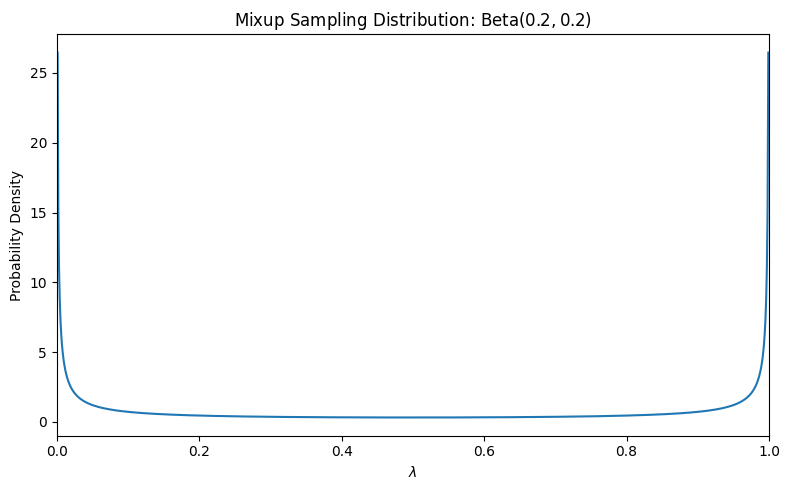

SECTION 6 - BETA DISTRIBUTION
Alpha: 0.2
Saved: /content/AI6103_Assignment/figures/section6_beta_distribution.png


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from pathlib import Path

# ============================================================
# Section 6 - Mixup Beta Distribution
# ============================================================

ALPHA = 0.2

# Project directories
PROJECT_DIR = Path("/content/AI6103_Assignment")
FIGURE_DIR = PROJECT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Beta distribution
x = np.linspace(0.001, 0.999, 1000)
y = beta.pdf(x, ALPHA, ALPHA)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(x, y)

plt.xlabel(r"$\lambda$")
plt.ylabel("Probability Density")

plt.title(r"Mixup Sampling Distribution: $\mathrm{Beta}(0.2, 0.2)$")

plt.xlim(0, 1)

plt.tight_layout()

# Save locally
figure_path = FIGURE_DIR / "section6_beta_distribution.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 60)
print("SECTION 6 - BETA DISTRIBUTION")
print("=" * 60)

print("Alpha:", ALPHA)
print("Saved:", figure_path)

#section6

In [8]:
import inspect

print("=" * 60)
print("检查 run_experiment 是否支持 Mixup")
print("=" * 60)

print(inspect.signature(run_experiment))

print("\n" + "=" * 60)
print("检查 train_one_epoch 的实现")
print("=" * 60)

print(inspect.getsource(train_one_epoch))

检查 run_experiment 是否支持 Mixup
(experiment_name, learning_rate, epochs, weight_decay=0.0, use_cosine_scheduler=False, use_mixup=False, mixup_alpha=0.2)

检查 train_one_epoch 的实现
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    use_mixup=False,
    mixup_alpha=0.2,
):

    model.train()

    running_loss = 0.0
    running_correct = 0
    total_samples = 0

    use_amp = torch.cuda.is_available()

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # Mixup is applied only when explicitly requested.
        if use_mixup:

            lam = float(
                np.random.beta(mixup_alpha, mixup_alpha)
            )

            permutation = torch.randperm(
                images.size(0),
                device=images.device
            )


In [9]:
import inspect

print(inspect.getsource(run_experiment))

def run_experiment(
    experiment_name,
    learning_rate,
    epochs,
    weight_decay=0.0,
    use_cosine_scheduler=False,
    use_mixup=False,
    mixup_alpha=0.2,
):

    set_seed(SEED)

    print("\n" + "#" * 70)
    print("Experiment:", experiment_name)
    print("Learning rate:", learning_rate)
    print("Epochs:", epochs)
    print("Weight decay:", weight_decay)
    print("Cosine scheduler:", use_cosine_scheduler)
    print("Mixup:", use_mixup)
    print("#" * 70)

    model = create_model().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=MOMENTUM,
        weight_decay=weight_decay,
    )

    scheduler = None

    if use_cosine_scheduler:

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=0.0,
        )

    scaler = create_scaler()

    best_val_accuracy = -1.0
    best_epoch = 0

    sta

In [10]:
import inspect

print(inspect.getsource(evaluate))

@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0
    running_correct = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with autocast_context():
            outputs = model(images)
            loss = criterion(outputs, labels)

        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        running_loss += loss.item() * batch_size
        running_correct += (
            predictions == labels
        ).sum().item()

        total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_accuracy = running_correct / total_samples

    return epoch_loss, epoch_accuracy



In [11]:
model_s6_mixup, summary_s6_mixup = run_experiment(
    experiment_name="section6_mixup_alpha_0.2",
    learning_rate=0.05,
    epochs=300,
    weight_decay=5e-4,
    use_cosine_scheduler=True,
    use_mixup=True,
    mixup_alpha=0.2,
)

print("\n" + "=" * 65)
print("SECTION 6 - MIXUP SUMMARY")
print("=" * 65)

for key, value in summary_s6_mixup.items():
    print(f"{key}: {value}")


######################################################################
Experiment: section6_mixup_alpha_0.2
Learning rate: 0.05
Epochs: 300
Weight decay: 0.0005
Cosine scheduler: True
Mixup: True
######################################################################
Epoch 001/300 | LR 0.0500000 | Train Loss 4.9389 | Train Acc 0.0092 | Val Loss 4.7856 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Time 25.9s
Epoch 002/300 | LR 0.0499986 | Train Loss 4.8046 | Train Acc 0.0091 | Val Loss 4.7789 | Val Acc 0.0104 | Best Val Acc 0.0104 (Epoch 1) | Time 26.6s
Epoch 003/300 | LR 0.0499945 | Train Loss 4.7837 | Train Acc 0.0102 | Val Loss 4.7852 | Val Acc 0.0124 | Best Val Acc 0.0124 (Epoch 3) | Time 29.9s
Epoch 004/300 | LR 0.0499877 | Train Loss 4.7811 | Train Acc 0.0105 | Val Loss 4.7783 | Val Acc 0.0130 | Best Val Acc 0.0130 (Epoch 4) | Time 31.4s
Epoch 005/300 | LR 0.0499781 | Train Loss 4.7763 | Train Acc 0.0124 | Val Loss 4.7710 | Val Acc 0.0144 | Best Val Acc 0.0144 (Epoch 5) | Tim

In [12]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/AI6103_Assignment")

metrics_path = PROJECT_DIR / "logs" / "epoch_metrics.csv"

df = pd.read_csv(metrics_path)

section6_df = df[
    df["experiment"] == "section6_mixup_alpha_0.2"
].copy()

section6_df = (
    section6_df
    .drop_duplicates(subset=["epoch"], keep="last")
    .sort_values("epoch")
)

print("=" * 60)
print("SECTION 6 METRICS CHECK")
print("=" * 60)

print("Total epochs:", len(section6_df))

print("\nFirst 5 epochs:")
print(section6_df.head().to_string(index=False))

print("\nLast 5 epochs:")
print(section6_df.tail().to_string(index=False))

print("\nBest validation accuracy:")
best_row = section6_df.loc[
    section6_df["val_accuracy"].idxmax()
]

print(best_row.to_string())

SECTION 6 METRICS CHECK
Total epochs: 300

First 5 epochs:
              experiment  epoch  learning_rate  weight_decay  train_loss  train_accuracy  val_loss  val_accuracy  elapsed_seconds
section6_mixup_alpha_0.2      1       0.050000        0.0005    4.938866        0.009224  4.785561      0.010437        25.863809
section6_mixup_alpha_0.2      2       0.049999        0.0005    4.804570        0.009085  4.778913      0.010437        55.621534
section6_mixup_alpha_0.2      3       0.049995        0.0005    4.783684        0.010203  4.785159      0.012394        86.671232
section6_mixup_alpha_0.2      4       0.049988        0.0005    4.781126        0.010482  4.778264      0.013046       120.902333
section6_mixup_alpha_0.2      5       0.049978        0.0005    4.776278        0.012439  4.771031      0.014351       156.276714

Last 5 epochs:
              experiment  epoch  learning_rate  weight_decay  train_loss  train_accuracy  val_loss  val_accuracy  elapsed_seconds
section6_mixup_

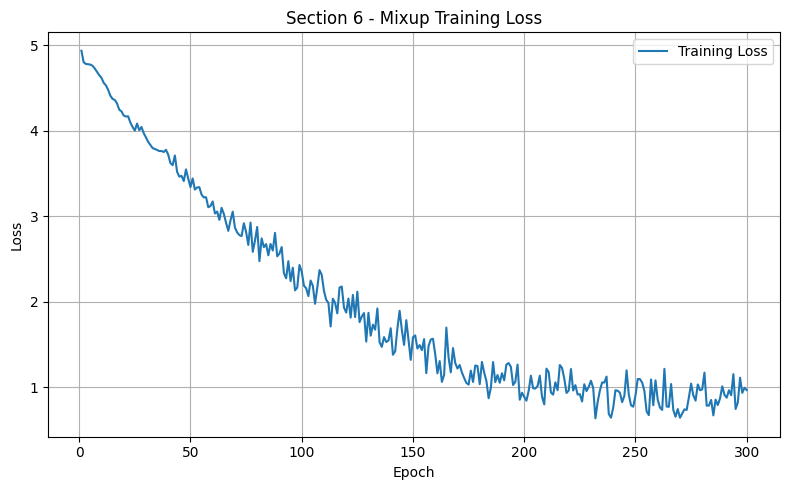

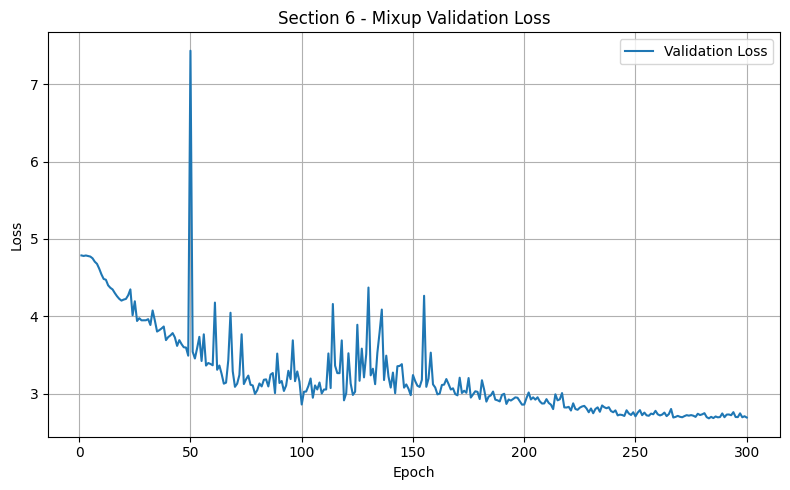

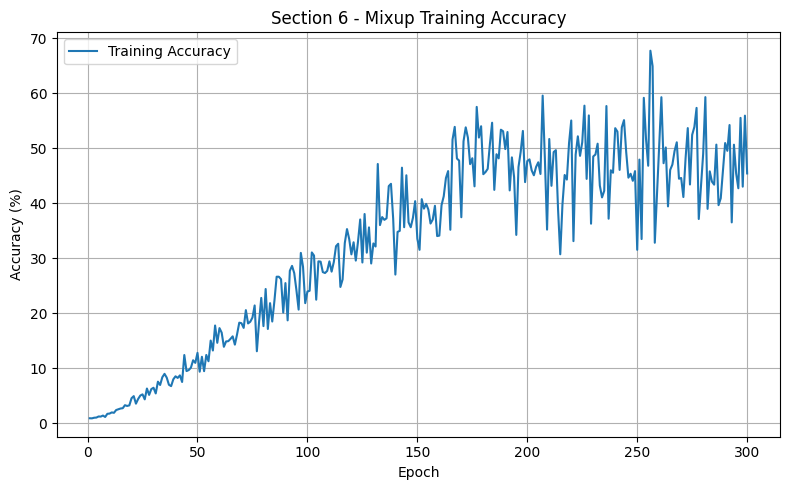

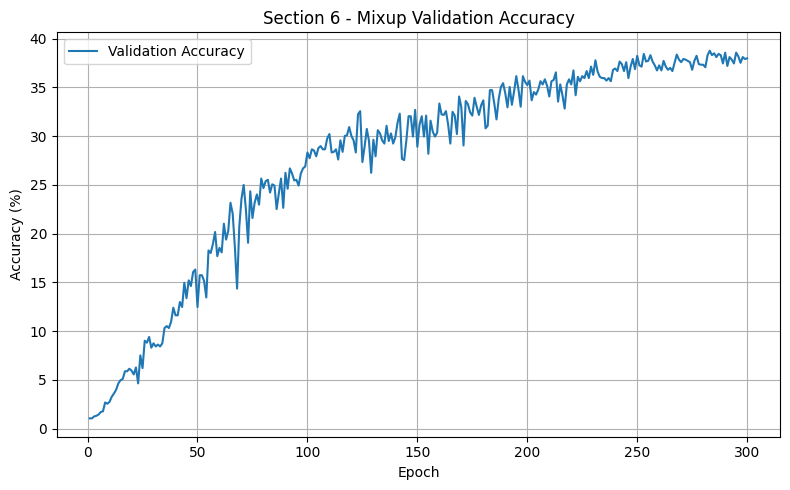

SECTION 6 FIGURES
section6_training_loss.png | Exists: True | Size: 154.57 KB
section6_validation_loss.png | Exists: True | Size: 150.55 KB
section6_training_accuracy.png | Exists: True | Size: 224.07 KB
section6_validation_accuracy.png | Exists: True | Size: 176.26 KB


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Section 6 - Generate Training Curves
# ============================================================

PROJECT_DIR = Path("/content/AI6103_Assignment")

METRICS_PATH = PROJECT_DIR / "logs" / "epoch_metrics.csv"
FIGURE_DIR = PROJECT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load metrics
df = pd.read_csv(METRICS_PATH)

# Filter Section 6
experiment_name = "section6_mixup_alpha_0.2"

section6_df = df[
    df["experiment"] == experiment_name
].copy()

# Remove duplicate epochs if any
section6_df = (
    section6_df
    .drop_duplicates(subset=["epoch"], keep="last")
    .sort_values("epoch")
)

# Verify
assert len(section6_df) == 300, (
    f"Expected 300 epochs, found {len(section6_df)}"
)

epochs = section6_df["epoch"]

# ============================================================
# 1. Training Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    section6_df["train_loss"],
    label="Training Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Section 6 - Mixup Training Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "section6_training_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 2. Validation Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    section6_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Section 6 - Mixup Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "section6_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. Training Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    section6_df["train_accuracy"] * 100,
    label="Training Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Section 6 - Mixup Training Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "section6_training_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. Validation Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    section6_df["val_accuracy"] * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Section 6 - Mixup Validation Accuracy")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "section6_validation_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# Verify saved figures
# ============================================================

print("=" * 60)
print("SECTION 6 FIGURES")
print("=" * 60)

for filename in [
    "section6_training_loss.png",
    "section6_validation_loss.png",
    "section6_training_accuracy.png",
    "section6_validation_accuracy.png",
]:

    path = FIGURE_DIR / filename

    print(
        filename,
        "| Exists:", path.exists(),
        "| Size:",
        f"{path.stat().st_size / 1024:.2f} KB"
        if path.exists()
        else "N/A"
    )

In [14]:
import os
import shutil
from pathlib import Path

# 项目路径
LOCAL_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

# 确认 Google Drive 已挂载
if not Path("/content/drive/MyDrive").exists():
    raise RuntimeError("Google Drive 未挂载，请先执行 drive.mount('/content/drive')")

if not LOCAL_DIR.exists():
    raise FileNotFoundError(f"本地项目目录不存在：{LOCAL_DIR}")

# 需要同步的实验结果目录
SYNC_DIRS = [
    "results",
    "logs",
    "figures",
    "checkpoints",
]

# 需要同步的项目配置文件
SYNC_FILES = [
    "experiment_config.json",
    "class_mapping.csv",
]

DRIVE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("SYNCING SECTION 6 AND PREVIOUS EXPERIMENT RESULTS")
print("=" * 60)

# 同步结果目录
for folder in SYNC_DIRS:
    src = LOCAL_DIR / folder
    dst = DRIVE_DIR / folder

    if src.exists():
        shutil.copytree(
            src,
            dst,
            dirs_exist_ok=True
        )
        print(f"[SYNCED] {folder}")
    else:
        print(f"[SKIPPED] {folder} - not found locally")

# 同步配置文件
for filename in SYNC_FILES:
    src = LOCAL_DIR / filename
    dst = DRIVE_DIR / filename

    if src.exists():
        shutil.copy2(src, dst)
        print(f"[SYNCED] {filename}")
    else:
        print(f"[SKIPPED] {filename} - not found locally")

print("\n" + "=" * 60)
print("SYNC VERIFICATION")
print("=" * 60)

# 检查 Section 6 的四张图
section6_figures = [
    "section6_training_loss.png",
    "section6_validation_loss.png",
    "section6_training_accuracy.png",
    "section6_validation_accuracy.png",
]

for filename in section6_figures:
    path = DRIVE_DIR / "figures" / filename

    if path.exists():
        print(f"[OK] {filename} | {path.stat().st_size / 1024:.2f} KB")
    else:
        print(f"[MISSING] {filename}")

# 检查 Section 6 实验总结
summary_path = DRIVE_DIR / "results" / "section6_summary.csv"

if summary_path.exists():
    print(f"\n[OK] Section 6 summary: {summary_path}")
else:
    print("\n[WARNING] Section 6 summary.csv not found in Drive")

print("\n同步完成。")
print(f"Google Drive destination: {DRIVE_DIR}")

SYNCING SECTION 6 AND PREVIOUS EXPERIMENT RESULTS
[SYNCED] results
[SYNCED] logs
[SYNCED] figures
[SYNCED] checkpoints
[SKIPPED] experiment_config.json - not found locally
[SKIPPED] class_mapping.csv - not found locally

SYNC VERIFICATION
[OK] section6_training_loss.png | 154.57 KB
[OK] section6_validation_loss.png | 150.55 KB
[OK] section6_training_accuracy.png | 224.07 KB
[OK] section6_validation_accuracy.png | 176.26 KB

[WARNING] Section 6 summary.csv not found in Drive

同步完成。
Google Drive destination: /content/drive/MyDrive/AI6103_Assignment


In [15]:
from pathlib import Path

LOCAL_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

print("=" * 60)
print("SECTION 6 SUMMARY SEARCH")
print("=" * 60)

for root in [LOCAL_DIR, DRIVE_DIR]:
    print(f"\nSearching: {root}")

    if not root.exists():
        print("Directory not found")
        continue

    matches = list(root.rglob("*section6*summary*"))

    if matches:
        for path in matches:
            print(f"[FOUND] {path}")
    else:
        print("[NOT FOUND] No Section 6 summary")

print("\n" + "=" * 60)
print("CONFIGURATION FILE SEARCH")
print("=" * 60)

config_names = [
    "experiment_config.json",
    "class_mapping.csv",
]

for filename in config_names:
    print(f"\nSearching for: {filename}")

    for root in [LOCAL_DIR, DRIVE_DIR]:
        matches = list(root.rglob(filename)) if root.exists() else []

        for path in matches:
            print(f"[FOUND] {path}")

print("\n" + "=" * 60)
print("SECTION 6 RESULT FILES IN DRIVE")
print("=" * 60)

results_dir = DRIVE_DIR / "results"

if results_dir.exists():
    for path in sorted(results_dir.iterdir()):
        if path.is_file():
            print(f"{path.name} | {path.stat().st_size / 1024:.2f} KB")
else:
    print("Drive results directory not found")

SECTION 6 SUMMARY SEARCH

Searching: /content/AI6103_Assignment
[FOUND] /content/AI6103_Assignment/results/section6_mixup_alpha_0.2_summary.csv

Searching: /content/drive/MyDrive/AI6103_Assignment
[FOUND] /content/drive/MyDrive/AI6103_Assignment/results/section6_mixup_alpha_0.2_summary.csv

CONFIGURATION FILE SEARCH

Searching for: experiment_config.json
[FOUND] /content/AI6103_Assignment/config/experiment_config.json
[FOUND] /content/drive/MyDrive/AI6103_Assignment/config/experiment_config.json

Searching for: class_mapping.csv
[FOUND] /content/AI6103_Assignment/config/class_mapping.csv
[FOUND] /content/drive/MyDrive/AI6103_Assignment/config/class_mapping.csv

SECTION 6 RESULT FILES IN DRIVE
backup_manifest.csv | 3.49 KB
section3_summary.csv | 0.45 KB
section4_summary.csv | 0.44 KB
section5_combined_summary.csv | 0.45 KB
section5_wd_1e-4_summary.csv | 0.30 KB
section5_wd_5e-4_summary.csv | 0.30 KB
section6_mixup_alpha_0.2_summary.csv | 0.31 KB


In [16]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

print("=" * 65)
print("EXPERIMENT ARTIFACT AUDIT")
print("=" * 65)

# 1. 检查各阶段的 summary
summary_files = [
    "section3_summary.csv",
    "section4_summary.csv",
    "section5_combined_summary.csv",
    "section5_wd_1e-4_summary.csv",
    "section5_wd_5e-4_summary.csv",
    "section6_mixup_alpha_0.2_summary.csv",
]

print("\n[1] SUMMARY FILES")

for filename in summary_files:
    path = DRIVE_DIR / "results" / filename
    if path.exists():
        df = pd.read_csv(path)
        print(f"[OK] {filename} | rows={len(df)}")
    else:
        print(f"[MISSING] {filename}")

# 2. 检查训练日志
print("\n[2] LOG FILES")

logs_dir = DRIVE_DIR / "logs"

if logs_dir.exists():
    for path in sorted(logs_dir.rglob("*")):
        if path.is_file():
            print(f"[FOUND] {path.relative_to(DRIVE_DIR)}")
else:
    print("[MISSING] logs directory")

# 3. 检查模型 checkpoint
print("\n[3] CHECKPOINT FILES")

checkpoint_dir = DRIVE_DIR / "checkpoints"

if checkpoint_dir.exists():
    checkpoint_files = [
        p for p in checkpoint_dir.rglob("*")
        if p.is_file()
    ]

    if checkpoint_files:
        for path in sorted(checkpoint_files):
            print(
                f"[FOUND] {path.relative_to(DRIVE_DIR)}"
                f" | {path.stat().st_size / (1024 ** 2):.2f} MB"
            )
    else:
        print("[WARNING] No checkpoint files found")
else:
    print("[MISSING] checkpoints directory")

# 4. 检查 Section 6 日志中的 epoch 数量
print("\n[4] SECTION 6 EPOCH AUDIT")

for root in [PROJECT_DIR, DRIVE_DIR]:
    if not root.exists():
        continue

    for path in root.rglob("epoch_metrics.csv"):
        try:
            df = pd.read_csv(path)

            if "experiment" in df.columns:
                exp_df = df[
                    df["experiment"].astype(str)
                    .str.contains("section6_mixup_alpha_0.2", case=False, na=False)
                ]
            else:
                exp_df = df.iloc[0:0]

            if not exp_df.empty and "epoch" in exp_df.columns:
                epochs = exp_df["epoch"].nunique()
                print(
                    f"{path} | Section 6 epochs={epochs}"
                    f" | {'[OK]' if epochs == 300 else '[CHECK]'}"
                )
        except Exception as e:
            print(f"[ERROR] {path}: {e}")

print("\nAudit completed.")

EXPERIMENT ARTIFACT AUDIT

[1] SUMMARY FILES
[OK] section3_summary.csv | rows=3
[OK] section4_summary.csv | rows=2
[OK] section5_combined_summary.csv | rows=2
[OK] section5_wd_1e-4_summary.csv | rows=1
[OK] section5_wd_5e-4_summary.csv | rows=1
[OK] section6_mixup_alpha_0.2_summary.csv | rows=1

[2] LOG FILES
[FOUND] logs/epoch_metrics.csv
[FOUND] logs/progress.md

[3] CHECKPOINT FILES
[FOUND] checkpoints/lr_0.001_best.pth | 156.11 MB
[FOUND] checkpoints/lr_0.001_latest.pth | 156.12 MB
[FOUND] checkpoints/lr_0.05_best.pth | 156.11 MB
[FOUND] checkpoints/lr_0.05_latest.pth | 156.12 MB
[FOUND] checkpoints/lr_0.5_best.pth | 156.11 MB
[FOUND] checkpoints/lr_0.5_latest.pth | 156.11 MB
[FOUND] checkpoints/section4_constant_best.pth | 156.12 MB
[FOUND] checkpoints/section4_constant_latest.pth | 156.13 MB
[FOUND] checkpoints/section4_cosine_best.pth | 156.12 MB
[FOUND] checkpoints/section4_cosine_latest.pth | 156.13 MB
[FOUND] checkpoints/section5_wd_1e-4_best.pth | 156.12 MB
[FOUND] checkpoin

In [17]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/AI6103_Assignment/checkpoints/"
    "section6_mixup_alpha_0.2_best.pth"
)

print("=" * 60)
print("BEST CHECKPOINT VALIDATION")
print("=" * 60)

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

print(f"File exists: {checkpoint_path}")
print(f"File size: {checkpoint_path.stat().st_size / (1024 ** 2):.2f} MB")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"  {key}: dict with {len(value)} entries")
        elif isinstance(value, torch.Tensor):
            print(f"  {key}: Tensor, shape={tuple(value.shape)}")
        else:
            print(f"  {key}: {type(value).__name__}")

    for key in ["epoch", "best_val_accuracy", "best_val_acc",
                "val_accuracy", "val_acc", "experiment"]:
        if key in checkpoint:
            print(f"{key}: {checkpoint[key]}")

print("\nCheckpoint inspection completed.")

BEST CHECKPOINT VALIDATION
File exists: /content/AI6103_Assignment/checkpoints/section6_mixup_alpha_0.2_best.pth
File size: 156.13 MB

Checkpoint type: dict

Top-level keys:
  experiment: str
  epoch: int
  best_val_accuracy: float
  model_state_dict: dict with 782 entries
  optimizer_state_dict: dict with 2 entries
  scheduler_state_dict: dict with 8 entries
  scaler_state_dict: dict with 5 entries
epoch: 283
best_val_accuracy: 0.38747553816046965
experiment: section6_mixup_alpha_0.2

Checkpoint inspection completed.


In [18]:
from pathlib import Path
import json

PROJECT_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

print("=" * 65)
print("MODEL AND CONFIGURATION AUDIT")
print("=" * 65)

# 1. 检查实验配置
config_path = PROJECT_DIR / "config" / "experiment_config.json"

if not config_path.exists():
    config_path = DRIVE_DIR / "config" / "experiment_config.json"

if not config_path.exists():
    raise FileNotFoundError("experiment_config.json not found")

print(f"\nConfig: {config_path}")

with open(config_path, "r", encoding="utf-8") as f:
    config = json.load(f)

print(json.dumps(config, indent=2, ensure_ascii=False))

# 2. 检查类别映射
mapping_path = PROJECT_DIR / "config" / "class_mapping.csv"

if not mapping_path.exists():
    mapping_path = DRIVE_DIR / "config" / "class_mapping.csv"

print("\n" + "=" * 65)
print("CLASS MAPPING")
print("=" * 65)

if mapping_path.exists():
    import pandas as pd

    mapping = pd.read_csv(mapping_path)
    print("Path:", mapping_path)
    print("Shape:", mapping.shape)
    print("Columns:", mapping.columns.tolist())
    print("\nFirst 5 rows:")
    print(mapping.head().to_string(index=False))

    print("\nUnique class count:", mapping.shape[0])
else:
    print("[WARNING] class_mapping.csv not found")

# 3. 定位模型定义
print("\n" + "=" * 65)
print("MODEL DEFINITION FILES")
print("=" * 65)

for path in sorted(PROJECT_DIR.rglob("*.py")):
    if any(
        keyword in path.name.lower()
        for keyword in ["model", "train", "dataset", "data"]
    ):
        print(path.relative_to(PROJECT_DIR))

MODEL AND CONFIGURATION AUDIT

Config: /content/AI6103_Assignment/config/experiment_config.json
{
  "image_size": 100,
  "num_classes": 120,
  "batch_size": 128,
  "num_workers": 2,
  "momentum": 0.9,
  "mean": [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754
  ],
  "std": [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994
  ],
  "best_learning_rate": 0.05,
  "seed": 42,
  "model": "EfficientNetV2-S",
  "pretrained_weights": null,
  "optimizer": "SGD",
  "dataset_sizes": {
    "train": 7155,
    "validation": 1533,
    "test": 1534
  }
}

CLASS MAPPING
Path: /content/AI6103_Assignment/config/class_mapping.csv
Shape: (120, 2)
Columns: ['class_index', 'breed']

First 5 rows:
 class_index                          breed
           0                  affenpinscher
           1                   afghan_hound
           2            african_hunting_dog
           3                       airedale
           4 american_staffordshire_terrier

Uniq

In [19]:
from pathlib import Path

PROJECT_DIR = Path("/content/AI6103_Assignment")

print("=" * 60)
print("PROJECT FILE STRUCTURE")
print("=" * 60)

for path in sorted(PROJECT_DIR.rglob("*")):
    if not path.is_file():
        continue

    relative_path = path.relative_to(PROJECT_DIR)

    # 避免输出数据集中的大量文件
    if "dataset" in relative_path.parts:
        continue

    print(relative_path)

print("\n" + "=" * 60)
print("PYTHON SOURCE FILES")
print("=" * 60)

for path in sorted(PROJECT_DIR.rglob("*.py")):
    if "dataset" not in path.parts:
        print(path.relative_to(PROJECT_DIR))

PROJECT FILE STRUCTURE
checkpoints/lr_0.001_best.pth
checkpoints/lr_0.001_latest.pth
checkpoints/lr_0.05_best.pth
checkpoints/lr_0.05_latest.pth
checkpoints/lr_0.5_best.pth
checkpoints/lr_0.5_latest.pth
checkpoints/section4_constant_best.pth
checkpoints/section4_constant_latest.pth
checkpoints/section4_cosine_best.pth
checkpoints/section4_cosine_latest.pth
checkpoints/section5_wd_1e-4_best.pth
checkpoints/section5_wd_1e-4_latest.pth
checkpoints/section5_wd_5e-4_best.pth
checkpoints/section5_wd_5e-4_latest.pth
checkpoints/section6_mixup_alpha_0.2_best.pth
checkpoints/section6_mixup_alpha_0.2_latest.pth
config/class_mapping.csv
config/experiment_config.json
figures/section3_training_accuracy.png
figures/section3_training_loss.png
figures/section3_validation_accuracy.png
figures/section3_validation_loss.png
figures/section4_training_accuracy.png
figures/section4_training_loss.png
figures/section4_validation_accuracy.png
figures/section4_validation_loss.png
figures/section6_beta_distributi

In [20]:
from pathlib import Path

print("=" * 60)
print("CURRENT WORKING DIRECTORY")
print("=" * 60)

import os
print("Working directory:", os.getcwd())

print("\n" + "=" * 60)
print("PYTHON FILES IN COMMON LOCATIONS")
print("=" * 60)

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive/AI6103_Assignment"),
]

seen = set()

for root in search_roots:
    if not root.exists():
        continue

    print(f"\nSearching under: {root}")

    for path in root.rglob("*.py"):
        if any(part.startswith(".") for part in path.parts):
            continue

        resolved = str(path.resolve())

        if resolved in seen:
            continue

        seen.add(resolved)
        print(path)

print("\nTotal unique Python files found:", len(seen))

print("\n" + "=" * 60)
print("POSSIBLE NOTEBOOK FILES")
print("=" * 60)

for root in search_roots:
    if not root.exists():
        continue

    for path in root.rglob("*.ipynb"):
        if ".ipynb_checkpoints" in path.parts:
            continue

        print(path)

CURRENT WORKING DIRECTORY
Working directory: /content

PYTHON FILES IN COMMON LOCATIONS

Searching under: /content

Searching under: /content/drive/MyDrive/AI6103_Assignment

Total unique Python files found: 0

POSSIBLE NOTEBOOK FILES
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Open_LLM_Benchmark_Prompt_Engineering (2).ipynb
/content/drive/MyDrive/Colab Notebooks/Open_LLM_Benchmark_Prompt_Engineering (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Open_LLM_Benchmark_Prompt_Engineering.ipynb
/content/drive/MyDrive/Colab Notebooks/RLAgent_2026Fall_completed.ipynb
/content/drive/MyDrive/Colab Notebooks/RLAgent_1_fixed.ipynb
/content/drive/MyDrive/Colab Notebooks/DQN_CliffBoxPushing (1).ipynb
/content/drive/MyDrive/Colab Notebooks/DQN_CliffBoxPushing.ipynb
/content/drive/MyDrive/Colab Notebooks/finalver.ipynb
/content/drive/MyDrive/Colab Notebooks/finalver_with_dqn_visualization (1).ipynb
/content/drive/MyDrive/Colab Notebooks/finalver_wit

In [ ]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/AI6103_Assignment_Fall_2026.ipynb"
)

if not notebook_path.exists():
    print("Notebook not found:", notebook_path)
else:
    with open(notebook_path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    cells = notebook.get("cells", [])

    print("Notebook:", notebook_path.name)
    print("Total cells:", len(cells))
    print("\n" + "=" * 70)
    print("MARKDOWN HEADINGS")
    print("=" * 70)

    for i, cell in enumerate(cells):
        if cell.get("cell_type") != "markdown":
            continue

        source = "".join(cell.get("source", []))
        headings = [
            line for line in source.splitlines()
            if line.strip().startswith("#")
        ]

        for heading in headings:
            print(f"[Cell {i}] {heading}")

    keywords = [
        "efficientnet",
        "create_model",
        "model =",
        "transforms",
        "normalize",
        "dataset",
        "dataloader",
        "test_loader",
        "test accuracy",
        "classification",
        "mixup",
        "state_dict",
        "checkpoint",
    ]

    print("\n" + "=" * 70)
    print("RELEVANT CODE CELLS")
    print("=" * 70)

    for i, cell in enumerate(cells):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))
        source_lower = source.lower()

        matched = [k for k in keywords if k in source_lower]

        if matched:
            print(f"\n{'=' * 70}")
            print(f"Cell {i} | Keywords: {', '.join(matched)}")
            print("=" * 70)

            # Avoid printing enormous training loops or output logs.
            lines = source.splitlines()
            if len(lines) > 100:
                print("\n".join(lines[:100]))
                print(f"\n... [truncated; total {len(lines)} lines]")
            else:
                print(source)

In [22]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "AI6103_Assignment_Fall_2026.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Cell 70 是完整环境恢复代码所在单元格
cell_index = 70
cell_source = "".join(notebook["cells"][cell_index]["source"])

# 输出关键函数及其上下文
lines = cell_source.splitlines()

keywords = [
    "class DogBreedDataset",
    "def create_model",
    "def evaluate",
    "def train_one_epoch",
    "def run_experiment",
    "def get_transforms",
    "def save_checkpoint",
    "def load_checkpoint",
    "EfficientNet_V2_S_Weights",
    "efficientnet_v2_s",
    "Normalize(",
    "test_loader",
]

print("=" * 70)
print("KEY FUNCTION LOCATIONS")
print("=" * 70)

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        print(f"Line {i + 1}: {line.strip()}")

print("\n" + "=" * 70)
print("MODEL / DATASET / EVALUATION IMPLEMENTATION")
print("=" * 70)

# 每个关键词显示前后一定范围，避免重复输出整份 Notebook
shown_ranges = []

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        start = max(0, i - 3)
        end = min(len(lines), i + 35)

        # 合并重叠区间
        if shown_ranges and start <= shown_ranges[-1][1]:
            shown_ranges[-1] = (
                shown_ranges[-1][0],
                max(shown_ranges[-1][1], end)
            )
        else:
            shown_ranges.append((start, end))

for start, end in shown_ranges:
    print(f"\n--- Lines {start + 1}-{end} ---")
    print("\n".join(lines[start:end]))

KEY FUNCTION LOCATIONS
Line 424: class DogBreedDataset(Dataset):
Line 482: transforms.Normalize(mean=MEAN, std=STD),
Line 488: transforms.Normalize(mean=MEAN, std=STD),
Line 544: test_loader = DataLoader(
Line 559: print("Test batches:", len(test_loader))
Line 570: def create_model():
Line 573: model = models.efficientnet_v2_s(weights=None)
Line 654: def train_one_epoch(
Line 751: def evaluate(
Line 866: def save_checkpoint(
Line 915: def run_experiment(
Line 1204: "test_loader",
Line 1225: print("Test:", len(test_loader.dataset))
Line 1230: print("Test:", len(test_loader))

MODEL / DATASET / EVALUATION IMPLEMENTATION

--- Lines 421-458 ---
print("STEP 8: Defining DogBreedDataset")
print("=" * 70)

class DogBreedDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_directory,
        class_to_idx,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.image_directory = Path(image_directory)
        self

In [23]:
import json
import torch
import pandas as pd
from pathlib import Path
from torchvision import models
import torch.nn as nn

# ============================================================
# 1. Define paths
# ============================================================

PROJECT_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

CHECKPOINT_PATH = (
    PROJECT_DIR / "checkpoints"
    / "section6_mixup_alpha_0.2_best.pth"
)

CONFIG_PATH = PROJECT_DIR / "config" / "experiment_config.json"
CLASS_MAPPING_PATH = PROJECT_DIR / "config" / "class_mapping.csv"

print("=" * 65)
print("STEP 1: Check required files")
print("=" * 65)

for path in [
    CHECKPOINT_PATH,
    CONFIG_PATH,
    CLASS_MAPPING_PATH,
]:
    print(
        f"{'PASS' if path.exists() else 'FAIL'} "
        f"{path.name}"
    )

assert CHECKPOINT_PATH.exists(), "Best checkpoint is missing."
assert CONFIG_PATH.exists(), "Experiment config is missing."
assert CLASS_MAPPING_PATH.exists(), "Class mapping is missing."

# ============================================================
# 2. Load experiment configuration
# ============================================================

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    config = json.load(f)

print("\n" + "=" * 65)
print("STEP 2: Experiment configuration")
print("=" * 65)

print(json.dumps(config, indent=2, ensure_ascii=False))

# ============================================================
# 3. Check class mapping
# ============================================================

class_mapping = pd.read_csv(CLASS_MAPPING_PATH)

print("\n" + "=" * 65)
print("STEP 3: Class mapping")
print("=" * 65)

print("Shape:", class_mapping.shape)
print("Columns:", class_mapping.columns.tolist())
print(class_mapping.head().to_string(index=False))

assert len(class_mapping) == 120, (
    f"Expected 120 classes, found {len(class_mapping)}"
)

assert class_mapping["class_index"].nunique() == 120
assert class_mapping["breed"].nunique() == 120

# ============================================================
# 4. Rebuild the exact model architecture
# ============================================================

model = models.efficientnet_v2_s(weights=None)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    120,
)

print("\n" + "=" * 65)
print("STEP 4: Model architecture")
print("=" * 65)

print("Model: EfficientNetV2-S")
print("Classifier input features:", in_features)
print("Classifier output features:", model.classifier[1].out_features)

# ============================================================
# 5. Load checkpoint and verify compatibility
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

print("\n" + "=" * 65)
print("STEP 5: Checkpoint")
print("=" * 65)

print("Experiment:", checkpoint.get("experiment"))
print("Best epoch:", checkpoint.get("epoch"))
print(
    "Best validation accuracy:",
    checkpoint.get("best_val_accuracy"),
)

assert (
    checkpoint.get("experiment")
    == "section6_mixup_alpha_0.2"
), "Unexpected checkpoint experiment."

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

print("PASS: All model parameters loaded successfully.")

# ============================================================
# 6. Check test dataset metadata only
# ============================================================

print("\n" + "=" * 65)
print("STEP 6: Test dataset metadata")
print("=" * 65)

print("Test dataset size:", len(test_dataset))
print("Test DataLoader batches:", len(test_loader))
print("Evaluation transform:", eval_transform)

assert len(test_dataset) == 1534, (
    f"Expected 1534 test images, found {len(test_dataset)}"
)

assert len(test_loader) > 0

print("\nAll checks passed.")
print("No test images were evaluated.")

STEP 1: Check required files
PASS section6_mixup_alpha_0.2_best.pth
PASS experiment_config.json
PASS class_mapping.csv

STEP 2: Experiment configuration
{
  "image_size": 100,
  "num_classes": 120,
  "batch_size": 128,
  "num_workers": 2,
  "momentum": 0.9,
  "mean": [
    0.4771834057763069,
    0.4527636099287068,
    0.3927860050343754
  ],
  "std": [
    0.25341599247313307,
    0.24796733174129357,
    0.25226678270663994
  ],
  "best_learning_rate": 0.05,
  "seed": 42,
  "model": "EfficientNetV2-S",
  "pretrained_weights": null,
  "optimizer": "SGD",
  "dataset_sizes": {
    "train": 7155,
    "validation": 1533,
    "test": 1534
  }
}

STEP 3: Class mapping
Shape: (120, 2)
Columns: ['class_index', 'breed']
 class_index                          breed
           0                  affenpinscher
           1                   afghan_hound
           2            african_hunting_dog
           3                       airedale
           4 american_staffordshire_terrier

STEP 4: Mode

FINAL TEST SET EVALUATION
Device: cuda
GPU: Tesla T4
Checkpoint: section6_mixup_alpha_0.2_best.pth
Checkpoint experiment: section6_mixup_alpha_0.2
Best epoch: 283
Best validation accuracy: 38.7476%
Model loaded successfully.
Processed batch 01/12 | samples: 128/1534
Processed batch 02/12 | samples: 256/1534
Processed batch 03/12 | samples: 384/1534
Processed batch 04/12 | samples: 512/1534
Processed batch 05/12 | samples: 640/1534
Processed batch 06/12 | samples: 768/1534
Processed batch 07/12 | samples: 896/1534
Processed batch 08/12 | samples: 1024/1534
Processed batch 09/12 | samples: 1152/1534
Processed batch 10/12 | samples: 1280/1534
Processed batch 11/12 | samples: 1408/1534
Processed batch 12/12 | samples: 1534/1534

FINAL TEST METRICS
experiment: section6_mixup_alpha_0.2
checkpoint_epoch: 283
best_validation_accuracy: 0.387476
test_samples: 1534
test_loss: 2.674773
test_accuracy: 0.389179
macro_precision: 0.401155
macro_recall: 0.380715
macro_f1: 0.378797
weighted_precision: 0

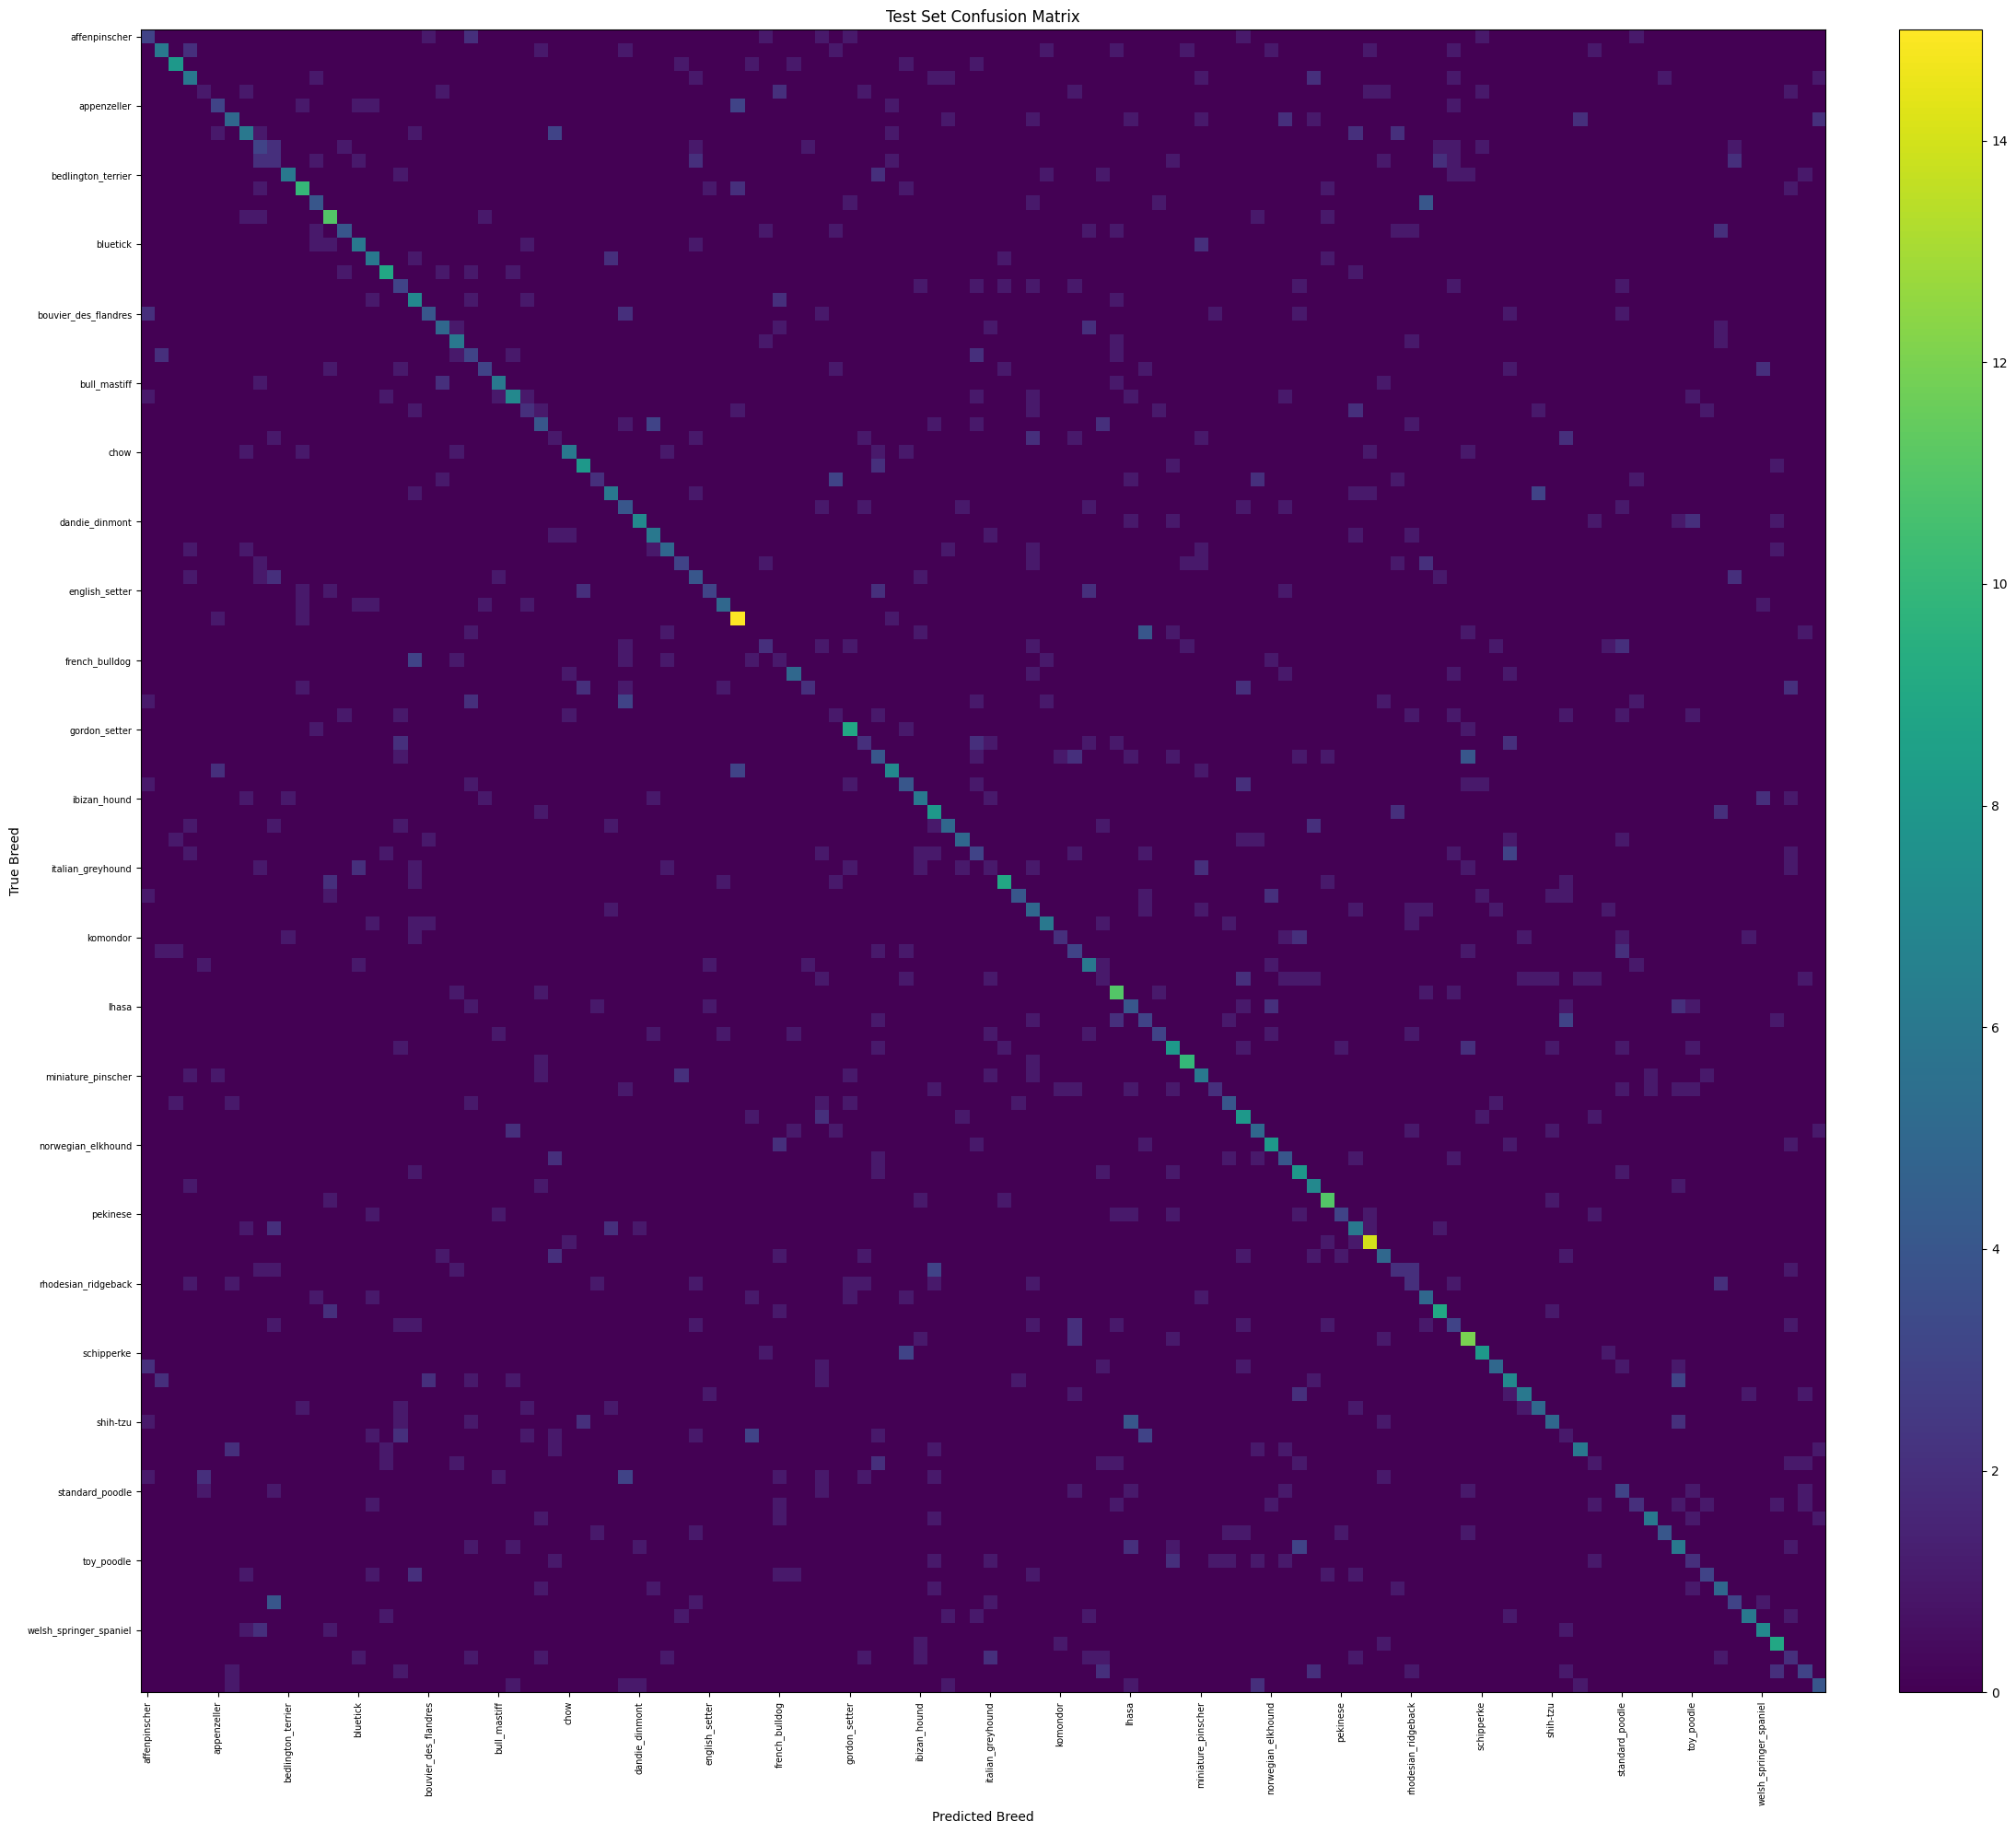

Confusion matrix CSV saved: /content/AI6103_Assignment/results/final_test_confusion_matrix.csv
Confusion matrix figure saved: /content/AI6103_Assignment/figures/final_test_confusion_matrix.png

Top 10 classes by F1:
                             precision    recall  f1-score  support
mexican_hairless              0.769231  0.833333  0.800000     12.0
pomeranian                    0.700000  0.823529  0.756757     17.0
entlebucher                   0.625000  0.833333  0.714286     18.0
african_hunting_dog           0.727273  0.615385  0.666667     13.0
saint_bernard                 0.642857  0.692308  0.666667     13.0
papillon                      0.578947  0.733333  0.647059     15.0
border_terrier                0.642857  0.642857  0.642857     14.0
west_highland_white_terrier   0.562500  0.750000  0.642857     12.0
sussex_spaniel                0.750000  0.545455  0.631579     11.0
clumber                       0.571429  0.666667  0.615385     12.0

Bottom 10 classes by F1:
          

In [24]:
# ============================================================
# AI6103 - Final Test Set Evaluation
# Best checkpoint: Section 6, Mixup alpha = 0.2, Epoch 283
# ============================================================

import json
import shutil
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from torchvision import models


# ============================================================
# 1. Reproducibility and paths
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

PROJECT_DIR = Path("/content/AI6103_Assignment")
DRIVE_DIR = Path("/content/drive/MyDrive/AI6103_Assignment")

CHECKPOINT_PATH = (
    PROJECT_DIR
    / "checkpoints"
    / "section6_mixup_alpha_0.2_best.pth"
)

RESULT_DIR = PROJECT_DIR / "results"
FIGURE_DIR = PROJECT_DIR / "figures"

RESULT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("FINAL TEST SET EVALUATION")
print("=" * 70)

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Checkpoint:", CHECKPOINT_PATH.name)


# ============================================================
# 2. Load the best model checkpoint
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

model = models.efficientnet_v2_s(weights=None)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 120)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

model = model.to(device)
model.eval()

criterion = nn.CrossEntropyLoss()

print("Checkpoint experiment:", checkpoint["experiment"])
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation accuracy:",
    f"{checkpoint['best_val_accuracy']:.4%}",
)
print("Model loaded successfully.")


# ============================================================
# 3. Evaluate the test set exactly once
# ============================================================

all_labels = []
all_predictions = []
all_probabilities = []
total_loss = 0.0
total_samples = 0

start_time = time.time()

with torch.inference_mode():
    for batch_index, (images, labels) in enumerate(test_loader, start=1):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        if device.type == "cuda":
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        probabilities = torch.softmax(outputs.float(), dim=1)
        predictions = outputs.argmax(dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(labels.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())
        all_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )

        print(
            f"Processed batch {batch_index:02d}/"
            f"{len(test_loader):02d} "
            f"| samples: {total_samples}/{len(test_dataset)}"
        )

elapsed_time = time.time() - start_time

y_true = np.asarray(all_labels, dtype=np.int64)
y_pred = np.asarray(all_predictions, dtype=np.int64)
y_prob = np.asarray(all_probabilities, dtype=np.float32)

assert len(y_true) == len(test_dataset), (
    f"Expected {len(test_dataset)} predictions, got {len(y_true)}"
)

assert y_prob.shape == (len(test_dataset), 120), (
    f"Unexpected probability shape: {y_prob.shape}"
)

assert np.isfinite(y_prob).all(), (
    "Non-finite values found in prediction probabilities."
)


# ============================================================
# 4. Calculate final test metrics
# ============================================================

test_loss = total_loss / total_samples
test_accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

weighted_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

weighted_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0,
)

print("\n" + "=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

metrics = {
    "experiment": checkpoint["experiment"],
    "checkpoint_epoch": int(checkpoint["epoch"]),
    "best_validation_accuracy": float(
        checkpoint["best_val_accuracy"]
    ),
    "test_samples": int(len(y_true)),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(macro_precision),
    "macro_recall": float(macro_recall),
    "macro_f1": float(macro_f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1": float(weighted_f1),
    "evaluation_time_seconds": float(elapsed_time),
}

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key}: {value:.6f}")
    else:
        print(f"{key}: {value}")


# ============================================================
# 5. Save the overall metrics
# ============================================================

metrics_path = RESULT_DIR / "final_test_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

metrics_csv_path = RESULT_DIR / "final_test_metrics.csv"
pd.DataFrame([metrics]).to_csv(
    metrics_csv_path,
    index=False,
)


# ============================================================
# 6. Save per-class classification report
# ============================================================

class_mapping = pd.read_csv(
    PROJECT_DIR / "config" / "class_mapping.csv"
)

class_mapping = class_mapping.sort_values("class_index")

class_names = class_mapping["breed"].astype(str).tolist()

assert len(class_names) == 120

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(120)),
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = RESULT_DIR / "final_test_classification_report.csv"
report_df.to_csv(report_path, index=True)

print("\nClassification report saved:", report_path)


# ============================================================
# 7. Save individual predictions
# ============================================================

test_df_for_predictions = test_dataset.dataframe.reset_index(drop=True)

prediction_df = pd.DataFrame({
    "image_id": test_df_for_predictions["id"].astype(str),
    "true_class_index": y_true,
    "predicted_class_index": y_pred,
    "true_breed": [
        class_names[i] for i in y_true
    ],
    "predicted_breed": [
        class_names[i] for i in y_pred
    ],
    "correct": y_true == y_pred,
    "confidence": y_prob.max(axis=1),
})

predictions_path = RESULT_DIR / "final_test_predictions.csv"
prediction_df.to_csv(predictions_path, index=False)

print("Predictions saved:", predictions_path)


# ============================================================
# 8. Save confusion matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(120)),
)

cm_path = RESULT_DIR / "final_test_confusion_matrix.csv"

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names,
).to_csv(cm_path, index=True)

# 120 x 120 matrix: save a readable high-resolution figure.
fig, ax = plt.subplots(figsize=(22, 20))

image = ax.imshow(
    cm,
    interpolation="nearest",
    aspect="auto",
)

ax.set_title("Test Set Confusion Matrix")
ax.set_xlabel("Predicted Breed")
ax.set_ylabel("True Breed")

# Avoid overcrowding labels.
tick_positions = np.arange(0, 120, 5)

ax.set_xticks(tick_positions)
ax.set_yticks(tick_positions)

ax.set_xticklabels(
    [class_names[i] for i in tick_positions],
    rotation=90,
    fontsize=7,
)

ax.set_yticklabels(
    [class_names[i] for i in tick_positions],
    fontsize=7,
)

fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()

cm_figure_path = FIGURE_DIR / "final_test_confusion_matrix.png"

fig.savefig(
    cm_figure_path,
    dpi=250,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Confusion matrix CSV saved:", cm_path)
print("Confusion matrix figure saved:", cm_figure_path)


# ============================================================
# 9. Show best and worst represented classes by F1
# ============================================================

per_class_df = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"],
].copy()

per_class_df = per_class_df.sort_values(
    "f1-score",
    ascending=False,
)

print("\nTop 10 classes by F1:")
print(per_class_df.head(10).to_string())

print("\nBottom 10 classes by F1:")
print(per_class_df.tail(10).to_string())


# ============================================================
# 10. Back up final evaluation results to Google Drive
# ============================================================

DRIVE_RESULT_DIR = DRIVE_DIR / "results"
DRIVE_FIGURE_DIR = DRIVE_DIR / "figures"

DRIVE_RESULT_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

result_files = [
    metrics_path,
    metrics_csv_path,
    report_path,
    predictions_path,
    cm_path,
]

for src in result_files:
    dst = DRIVE_RESULT_DIR / src.name
    shutil.copy2(src, dst)
    print("Backed up:", dst.name)

shutil.copy2(
    cm_figure_path,
    DRIVE_FIGURE_DIR / cm_figure_path.name,
)

print("\n" + "=" * 70)
print("FINAL EVALUATION COMPLETE")
print("=" * 70)

print("Test samples:", len(y_true))
print(f"Test accuracy: {test_accuracy:.4%}")
print("Results directory:", RESULT_DIR)
print("Drive backup:", DRIVE_RESULT_DIR)